# Digit-k computation test (Emergence S4, extended) — Gemma-2 9B → 2B (graft L20 ← L34)

STANDALONE, fresh pod. Run cell 1, RESTART the kernel, then run from cell 2 to the end.

**Question.** The donor's state is grafted where it has *not yet computed* digit k, and a map is
trained **directly to deliver digit k**. Transferring the donor's computation would then help, so the
training objective pushes for it. Does anything beyond the answer content transfer?

**Setup** (= CELL S4 of `Emergence_Gemma` / `Emergence_Qwen`, generalised to digit 3).
- The recipient reads the prompt plus the gold digits 1..k−1.
- The graft REPLACES its last-position state at layer `L_R`. The target is the digit-k token.
- One map per donor source, trained from scratch on digit k with S4's recipe: ridge init, Adam 1e-3,
  6 epochs, batch 16, CE on the digit-k token.
- Scope: single-position, mid-layer stitching only.

| source | donor state | role |
|---|---|---|
| `PREFILL` | the `=` token, graft layer (= S4's A) | test: digit k not computed yet |
| `MID_PRED` | the position that predicts digit k, graft layer | test: the donor is part-way to digit k |
| `MID_PRED_MID` | the same position, a layer between the graft layer and the last | dose-response: partly computed |
| `DEEP_PRED` | the same position, the donor's final (post-norm) output (= S4's B) | reference: digit k computed |
| `PRESENT` | after digit k is input, graft layer (= S4's C) | positive control: digit k present |
| `PREFILL_SP` | the space before digit 1, graft layer | probes only (the paper's first-token site) |

**Other maps.** All use the same recipe, data and number of steps; code-fed writers are ridge-initialised with λ = 1.
- `CONST`: one trained vector for every problem. The no-information null.
- `PREFIX`: a writer fed the gold digits 1..k−1, which the recipient already has. The graft wipes the
  current token, and a source may restore it, so this is the "restored the context" null.
- `SHUF_PFX`: the source's own map fed another bin problem's state that shares digits 1..k−1.
- Every source is compared with all three; the strongest is the null used.
- `PRODUCT`: a writer fed the digits of a·b plus the prefix. This is the **positive control for usable
  computation**: can the recipient finish the problem from a transferred intermediate result? It
  counts only if it beats both PREFIX and a lookup that guesses digit k from a·b and the prefix
  while ignoring c.
- `GOLD`: a writer fed gold digit k plus the prefix. This is the channel ceiling.
- `*_PFX`: a source state concatenated with the prefix. This is the fair comparator for the bottleneck.
- `*_s1`: a second training order.
- `*_MLP`: a nonlinear map.

**Bins.**
- The **eval bin** contains eval problems where the donor gets the first token AND digit k right
  (teacher-forced), and the recipient natively gets digit k wrong.
- S4's population (the donor's first token right, the recipient wrong) is scored for the GitHub sanity check.

| part | answers |
|---|---|
| 0 | **The paper's basic first-token stitch**, replicated (EXP2/EXP3, seed 0) and checked against GitHub, with its training-loss curve; the same run continues to 20 epochs to show whether the loss plateaus. |
| P | **Was digit k (or an intermediate, a·b's digit) computed at the source?** Held-out linear and MLP probes against baselines, a logit-lens ceiling (≈1 on the bin by construction) and a depth sweep. |
| T | Trains the maps; checks S4 and S2 against GitHub. PREFILL, MID_PRED, CONST and PREFIX run to 20 epochs; their 6-epoch snapshot is what every other part uses. |
| L | **Training-loss graphs** for every digit-k map (per batch and per epoch, training vs held-out), a plateau read-out, and whether 20 epochs lifts held-out conferral above the nulls. |
| 1 | **Could it just memorise?** The map vs its fair null on its OWN training problems and on the eval bin, plus per-epoch curves. |
| 2 | **Above the fair nulls?** Seed-averaged primary test; positive controls PRESENT, GOLD and PRODUCT; results split by answer length. |
| 3 | **Room to do better?** SVD truncation of dW (primary) and W, on eval and training; the MLP map vs the linear map. |
| 4 | **What content drives it?** Partner swaps (AM / PM / AB) with gating. |
| 5 | **Erasure** of digit k from the source: class-mean (primary) and orthogonalised INLP, with permuted-label and random controls. |
| 6 | **Probe bottleneck**: cross-fitted digit-k readout plus prefix, against the state+prefix map. |
| 7 | **Continuation** (= GitHub's same-bin completion test, CELL SB): on problems the recipient natively gets digit k right, does the digit-k graft help it with digit k+1? Teacher-forced on all such problems (primary), plus GitHub's free-generation paired reading; against native, no-information grafts and a matched shuffle. |
| S | Summary: each claim, its numbers and a mechanical label. Labels are a reading aid; the numbers are the result. |

**Statistics.**
- A "no effect" claim needs the upper 95% bound below the smallest effect of interest, `SESOI` = 0.05.
- The primary above-null test is Holm-corrected over the 4 primary cells (2 sources × 2 digits).
- The Part 3–6 contrasts (MLP vs linear, swap contrasts, bottleneck vs map) use 99% intervals. All
  other intervals are 95% and unadjusted.
- Parts 3–6 print a label only if the map is above its fair null; otherwise they print UNINFORMATIVE.

**Run.**
- Set `PAIR` in cell 2 (preset in this file).
- Hardware: a 48 GB card (GitHub's run used an sm_89 card, so an L40S / RTX 6000 Ada reproduces it most
  closely) and at least 32 GB of CPU RAM.
- Time: roughly 4.5–5 h for Gemma and about 1.5 h for Qwen (`RUN_LONG = False` saves about 1 h / 20 minutes).
- Plots are shown inline and saved to `digitk_computation_<pair>_plots/`.
- Results are checkpointed to `digitk_computation_<pair>.json` after every part.
- Trained maps are cached with a fingerprint, so a re-run after a crash skips finished training.
- `SMOKE_TEST = True` is a plumbing check only.

In [1]:
# === CELL 1: install into THIS kernel's Python (run once, then RESTART THE KERNEL) ===
# Installs with the kernel's own interpreter (sys.executable). On vast.ai (and some other hosts) the `pip` on the
# PATH belongs to a different Python than the notebook kernel, so `!pip install` leaves the kernel without
# numpy / torch. Pins = the Emergence notebooks' (transformers 4.46.3). torch: the image's build is kept if the
# kernel has one; otherwise one matched to the GPU is installed (GitHub's runs used torch 2.4.1 + CUDA 12.4;
# Blackwell cards, compute capability 12.x such as RTX 5090 / RTX PRO 6000, need a CUDA 12.8 build).
import sys, subprocess, shutil, importlib.util
print("kernel python:", sys.executable)
def _pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args])
    if r.returncode != 0:                      # a bare venv without pip: bootstrap it once and retry
        subprocess.run([sys.executable, "-m", "ensurepip", "--upgrade"])
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)
def _have(mod): return importlib.util.find_spec(mod) is not None
_cap = None
if shutil.which("nvidia-smi"):
    _out = subprocess.run(["nvidia-smi", "--query-gpu=name,compute_cap", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip().splitlines()
    if _out:
        print("GPU:", _out[0]); _cap = float(_out[0].split(",")[-1])
if not _have("torch"):
    print("no torch in this kernel: installing one for compute capability", _cap)
    if _cap is not None and _cap >= 12:
        _pip("torch", "--index-url", "https://download.pytorch.org/whl/cu128")
    else:
        _pip("torch==2.4.1", "--index-url", "https://download.pytorch.org/whl/cu124")
_pip("transformers==4.46.3", "accelerate", "matplotlib", "huggingface_hub", "hf_transfer",
     *([] if _have("numpy") else ["numpy<2"]))
# torchvision / torchaudio from the image can clash with the torch above when transformers imports them
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision", "torchaudio"])
print("deps installed into", sys.executable, "-> RESTART THE KERNEL now, then continue from CELL 2")

kernel python: /venv/main/bin/python
GPU: NVIDIA L40S, 8.9
no torch in this kernel: installing one for compute capability 8.9


deps installed into /venv/main/bin/python -> RESTART THE KERNEL now, then continue from CELL 2


In [1]:
# === CELL 2: imports + RUN CONFIG ===
import os
os.environ.setdefault("HF_HUB_ENABLE_HF_TRANSFER", "1")
import json, math, random, time, gc, re, collections
from fractions import Fraction
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
_GPU = (torch.cuda.get_device_name(0), list(torch.cuda.get_device_capability(0))) if torch.cuda.is_available() else ("cpu", None)
if torch.cuda.is_available():                  # does this torch build carry kernels for this GPU generation?
    _majors = {int(m_.group(1)[:-1]) for a_ in torch.cuda.get_arch_list() for m_ in [re.match(r"sm_(\d{2,3})", a_)] if m_}
    assert not _majors or _GPU[1][0] in _majors, (
        f"this torch ({torch.__version__}) has no kernels for {_GPU[0]} (compute capability {_GPU[1]}). In a cell run:\n"
        f"  import sys, subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '--upgrade', 'torch', "
        f"'--index-url', 'https://download.pytorch.org/whl/cu128'])\nthen RESTART THE KERNEL and run from CELL 2.")
print(f"torch {torch.__version__} | transformers {transformers.__version__} (want 4.46.3) | {_GPU[0]} cap {_GPU[1]} "
      f"(GitHub's run: torch 2.4.1+cu124, cap (8, 9))")

PAIR = "gemma"            # "gemma" or "qwen"
SMOKE_TEST = False             # True = plumbing check with tiny sizes; numbers meaningless

_PAIRS = {   # = MODEL_2B / MODEL_9B / SINGLE_PAIR (recipient layer, donor layer) in the Emergence notebooks
    "gemma": dict(MODEL_R="google/gemma-2-2b", MODEL_D="google/gemma-2-9b", L_R=20, L_D=34),
    "qwen":  dict(MODEL_R="Qwen/Qwen2.5-0.5B", MODEL_D="Qwen/Qwen2.5-7B", L_R=17, L_D=23),
}
MODEL_R, MODEL_D, L_R, L_D = (_PAIRS[PAIR][x] for x in ("MODEL_R", "MODEL_D", "L_R", "L_D"))

# --- Emergence S4 recipe, unchanged ---
N_TRAIN, N_EVAL = 3000, 2000
ARITH_BATCH = BATCH = 16          # recipient batches: states, training, scoring
COLLECT_BATCH = 8                 # donor batches (= collect_states_multi)
TASK_EPOCHS, RIDGE_LAMBDA = 6, 1e3
K_LIST = [2, 3]                   # digit 2 (= S4) and digit 3 (new)

# --- what to run (cut from the bottom of this list first if time is short) ---
RUN_EXTRA_SEED = True             # PREFILL and MID_PRED with a second training order (used in the primary test)
RUN_MLP_MAP = True                # nonlinear map: ridge-initialised linear map + zero-initialised MLP residual
RUN_SWAPS = True                  # Part 4 (and its partner extraction in CELL 8)
RUN_ERASURE = True                # Part 5
RUN_BOTTLENECK = True             # Part 6
RUN_CONTINUATION = True           # Part 7 (same-bin completion: does the digit-k graft help digit k+1?)
RUN_FIRST_TOKEN = True            # Part 0: the paper's basic first-token stitch (EXP2/EXP3), with loss curves
FT_SEEDS = [0]                    # first-token task-map seeds (the paper trained 5; seed 0 is the one it scores)
RUN_LONG = True                   # continue PREFILL, MID_PRED, CONST, PREFIX (and the first-token map) to LONG_EPOCHS
LONG_EPOCHS = 20                  # the 6-epoch snapshot of the same run is the map every other part uses
FREE_DONOR = True                 # drop the donor from the GPU once every donor state is extracted
CACHE_MAPS = True                 # trained maps saved with a fingerprint; a re-run loads matching ones

# --- test settings ---
SESOI = 0.05                      # smallest effect of interest (conferral points)
WRITER_LAMBDA = 1.0               # ridge lambda for code-fed writers (one-hot / softmax inputs)
MLP_MAP_HIDDEN = 1024
SVD_RANKS = [1, 2, 4, 8, 16, 32, 64, 128, 256]       # + 0 and full
INLP_RANKS = [10, 20, 40, 80, 160]                    # 10 directions per round (a 10-way digit probe)
SHUF_SEEDS = [0, 1, 2]
TRAIN_SAMPLE = 800                # training-bin problems scored per SVD rank
MONITOR_SAMPLE = 600              # training-bin problems scored after every epoch
PROBE_MLP_STEPS = 800             # = probe_mlp (Followup3_MLPprobe)
N_FOLDS = 5                       # cross-fitted bottleneck readers
SWAP_SEED, N_CAND, MIN_GAP = 1234, 3, 2               # partner swaps: up to N_CAND tries, digit-k gap >= MIN_GAP
BN_SEED = 0
LONG_MAPS = ("PREFILL", "MID_PRED", "CONST", "PREFIX")
MAX_NEW_ARITH = 8                 # = Emergence: greedy tokens for full-answer generation (Part 0)
MIN_CONT_N = 30                   # Part 7 needs at least this many solvable-bin problems
CONT_MAX_NEW = 6                  # greedy tokens generated after digit k-1 (answers have <= 4 digits)
BOOT_B = 4000
CODE_VERSION = "digitk-v3"
if SMOKE_TEST:
    N_TRAIN, N_EVAL, TASK_EPOCHS = 300, 250, 2
    SVD_RANKS, INLP_RANKS, SHUF_SEEDS = [1, 4, 16], [10, 20], [0, 1]
    TRAIN_SAMPLE, MONITOR_SAMPLE, PROBE_MLP_STEPS, MLP_MAP_HIDDEN, N_CAND, BOOT_B = 80, 60, 60, 64, 2, 500
    MIN_CONT_N = 5
    LONG_EPOCHS = TASK_EPOCHS + 2
assert SHUF_SEEDS and INLP_RANKS and SVD_RANKS

TAG = f"digitk_computation_{PAIR}" + ("_SMOKE" if SMOKE_TEST else "")
OUT_JSON = TAG + ".json"
CACHE_DIR = f"{TAG}_maps_{CODE_VERSION}"
PLOT_DIR = f"{TAG}_plots"
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(PLOT_DIR, exist_ok=True)
SANITY = {}
RESULTS = {"_config": dict(pair=PAIR, donor=MODEL_D, recipient=MODEL_R, L_R=L_R, L_D=L_D, n_train=N_TRAIN,
                           n_eval=N_EVAL, epochs=TASK_EPOCHS, k_list=K_LIST, smoke=SMOKE_TEST, sesoi=SESOI,
                           mlp_map_hidden=MLP_MAP_HIDDEN, min_gap=MIN_GAP, code_version=CODE_VERSION,
                           long_epochs=LONG_EPOCHS if RUN_LONG else None, ft_seeds=FT_SEEDS,
                           torch=torch.__version__, transformers=transformers.__version__,
                           gpu=_GPU[0], cuda_capability=_GPU[1]),
           "SANITY": SANITY}
PER_ITEM = {}
def save(tag=""):
    with open(OUT_JSON, "w") as f:
        json.dump({**RESULTS, "per_item": PER_ITEM, "_last": tag}, f, indent=1, default=str)
    print(f"  [saved {OUT_JSON}{' after ' + tag if tag else ''}]")

# --- what the GitHub Emergence runs got (sanity targets) ---
_REF = {
    "gemma": dict(n_donor_solved=1693,
                  ft=dict(n_unsolv=632, task_first=0.886, recon_first=0.191, native_full=0.003, recon_full=0.034,
                          task_full=0.127, final_batch_ce=0.008, task_solv_first=0.951, recon_cos_recon=0.981,
                          recon_cos_task=0.219, shuffle_first=0.102),
                  s4=dict(n_eval=1693, n_fail=1233, A=0.234, B=0.515, C=0.999, C_shuffle=0.102),
                  s2_n=1384, s2={34: dict(prefill_d2=0.16, diag_d2=0.182, diag_d3=0.585),
                                 37: dict(prefill_d2=0.22, diag_d2=0.364, diag_d3=0.71),
                                 41: dict(prefill_d2=0.24, diag_d2=0.455, diag_d3=0.73)}),
    "qwen": dict(n_donor_solved=1681,
                 ft=dict(n_unsolv=568, task_first=0.794, recon_first=0.134, native_full=0.000, recon_full=0.005,
                         task_full=0.038, final_batch_ce=0.094, task_solv_first=0.868, recon_cos_recon=0.991,
                         recon_cos_task=0.071, shuffle_first=0.178),
                 s4=dict(n_eval=1681, n_fail=1240, A=0.149, B=0.436, C=0.998, C_shuffle=0.106),
                 s2_n=1379, s2={23: dict(prefill_d2=0.157, diag_d2=0.171, diag_d3=0.335),
                                25: dict(prefill_d2=0.204, diag_d2=0.233, diag_d3=0.546),
                                27: dict(prefill_d2=0.228, diag_d2=0.394, diag_d3=0.583)}),
}
REF = _REF[PAIR]
def check(name, got, want, tol, warn=None):
    """PASS within tol; WARN within warn (a bf16 argmax tie or a different GPU can move a few items); CHECK
    beyond. SMOKE runs record SKIP (tiny data, nothing to compare)."""
    if SMOKE_TEST: st = "SKIP"
    else:
        d = abs(got - want)
        st = "PASS" if d <= tol else ("WARN" if warn is not None and d <= warn else "CHECK")
    SANITY[name] = {"github": want, "this_run": got, "status": st}
    print(f"  {st:5s} {name:52s} github {want}   this run {got}")
print("PAIR =", PAIR, "| SMOKE_TEST =", SMOKE_TEST, "| device", DEVICE)

torch 2.4.1+cu124 | transformers 4.46.3 (want 4.46.3) | NVIDIA L40S cap [8, 9] (GitHub's run: torch 2.4.1+cu124, cap (8, 9))
PAIR = gemma | SMOKE_TEST = False | device cuda


In [ ]:
# === CELL 3: Hugging Face login (Gemma is gated; Qwen is not) ===
from huggingface_hub import login
_tok = os.environ.get("") or ""   # paste, run, then clear before sharing
if PAIR == "gemma" or not _tok.startswith("hf_PASTE"):
    login(_tok); print("logged in")
else:
    print("no token set; Qwen is not gated, continuing")
del _tok

logged in


In [3]:
# === CELL 4: statistics helpers ===
def wilson(k, n, z=1.96):
    if n == 0: return (float("nan"),) * 3
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = (z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / d
    return p, max(0.0, c - h), min(1.0, c + h)
def wilson_bools(b, z=1.96):
    b = np.asarray(b, bool); return wilson(int(b.sum()), int(b.size), z)
def fmt(tr): p, lo, hi = tr; return f"{p:.3f} [{lo:.3f}, {hi:.3f}]"
def rate(v):
    v = [x for x in v if x is not None and not (isinstance(x, float) and math.isnan(x))]
    return round(float(np.mean(v)), 4) if len(v) else None
def mcnemar_exact(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01 = int((~a & b).sum()); n10 = int((a & ~b).sum()); n = n01 + n10
    if n == 0: return dict(n01=0, n10=0, p=1.0)
    k = min(n01, n10); tot = Fraction(0)
    for i in range(0, k + 1): tot += Fraction(math.comb(n, i))
    return dict(n01=n01, n10=n10, p=min(1.0, float(2 * tot / Fraction(2) ** n)))
def R(ok):
    """Rate with a Wilson 95% interval."""
    ok = [bool(x) for x in ok]
    if not ok: return {"n": 0, "rate": None, "ci": None}
    return {"n": len(ok), "rate": round(float(np.mean(ok)), 4), "ci": fmt(wilson_bools(ok))}
def paired(a, b, seed=0, alpha=0.05):
    """b minus a on the same items (NaN pairs dropped): mean difference, percentile-bootstrap interval at
    level 1-alpha, two-sided bootstrap p; exact McNemar when both are 0/1."""
    a = np.asarray(a, float); b = np.asarray(b, float); keep = ~(np.isnan(a) | np.isnan(b)); a, b = a[keep], b[keep]
    d = b - a
    if len(d) == 0: return {"n": 0, "diff": None, "lo": None, "hi": None, "ci": None, "p_boot": None, "level": 1 - alpha}
    rng = np.random.default_rng(seed); m = d[rng.integers(0, len(d), (BOOT_B, len(d)))].mean(1)
    lo, hi = np.percentile(m, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p = float(min(1.0, 2 * min((m <= 0).mean(), (m >= 0).mean())))
    out = {"n": int(len(d)), "diff": round(float(d.mean()), 4), "lo": round(float(lo), 4), "hi": round(float(hi), 4),
           "ci": f"{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]", "p_boot": round(p, 5), "level": 1 - alpha}
    if set(np.unique(a)) <= {0.0, 1.0} and set(np.unique(b)) <= {0.0, 1.0}:
        mc = mcnemar_exact(a > 0.5, b > 0.5); out.update(only_a=mc["n10"], only_b=mc["n01"], mcnemar_p=mc["p"])
    return out
def holm(pvals):
    """Holm step-down adjusted p-values for a dict name -> p."""
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out = {}; run = 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p)); out[k] = round(run, 5)
    return out
def effect_label(p, what="effect"):
    """Three-way: ABOVE (interval > 0) / BELOW (< 0) / no detectable effect, with its upper bound; 'equivalent
    to none' only when the upper bound is below SESOI."""
    if p is None or p.get("lo") is None: return "n/a"
    if p.get("only_a") == 0 and p.get("only_b") == 0:
        return f"identical on all {p['n']} items (no discordant pairs; the interval is degenerate)"
    if p["lo"] > 0: return f"ABOVE ({p['ci']})"
    if p["hi"] < 0: return f"BELOW ({p['ci']})"
    return (f"no detectable {what}: at most {p['hi']:+.3f}" +
            (f" (< SESOI {SESOI}: equivalent to none)" if p["hi"] < SESOI else f" (cannot rule out {SESOI})"))
def above(p): return p is not None and p.get("lo") is not None and p["lo"] > 0
print("stats ready")

stats ready


In [4]:
# === CELL 5: shared helpers (= Emergence CELL 5, the parts S4 uses) ===
PATCH_POS = -1
def _hid(o): return o[0] if isinstance(o, tuple) else o
def _pack(o, h): return (h,) + tuple(o[1:]) if isinstance(o, tuple) else h
def left_pad(id_list, pad_id):
    L = max(t.numel() for t in id_list)
    ids = torch.full((len(id_list), L), pad_id, dtype=torch.long)
    m = torch.zeros((len(id_list), L), dtype=torch.long)
    for i, t in enumerate(id_list):
        t = t.flatten(); ids[i, L - t.numel():] = t; m[i, L - t.numel():] = 1
    return ids, m
def fit_ridge(X9, X2, lam=RIDGE_LAMBDA):
    mu9, mu2 = X9.mean(0), X2.mean(0)
    A, B = X9 - mu9, X2 - mu2
    W = torch.linalg.solve(A.T @ A + lam * torch.eye(A.shape[1]), A.T @ B)
    return mu9, mu2, W
FEWSHOT = ("2 + 5 = 7\n6 * 3 = 18\n4 * 7 + 2 = 30\n9 * 8 = 72\n"
           "3 * 4 + 5 = 17\n40 * 20 = 800\n")
def _aprompt(expr): return f"{FEWSHOT}{expr} ="
def _aencode(tok, expr, ans):
    p = tok(_aprompt(expr)).input_ids
    f = tok(_aprompt(expr) + " " + str(ans)).input_ids
    if f[:len(p)] != p or len(f) <= len(p): return None, None
    j = len(p)
    while j < len(f) and not any(ch.isdigit() for ch in tok.decode([f[j]])): j += 1
    if j >= len(f): return None, None
    return torch.tensor(f[:j]), f[j]
def gen_arith(tok, n, rng, exclude=None):
    exclude = exclude or set(); out, seen = [], set()
    tries = 0
    while len(out) < n and tries < n * 120:
        tries += 1
        a, b, c = rng.randint(2, 40), rng.randint(2, 40), rng.randint(1, 99)
        expr, ans = f"{a} * {b} + {c}", a * b + c
        if expr in seen or expr in exclude: continue
        seen.add(expr)
        ids, tok_id = _aencode(tok, expr, ans)
        if tok_id is None: continue
        out.append(dict(expr=expr, ans=ans, ids=ids, tok=tok_id))
    return out
@torch.inference_mode()
def states_and_top(model, layers, prob_ids, batch=ARITH_BATCH):
    acc = {L: [] for L in layers}; top = []
    for i in range(0, len(prob_ids), batch):
        ids, m = left_pad(prob_ids[i:i + batch], tokenizer.pad_token_id)
        out = model(ids.to(DEVICE), attention_mask=m.to(DEVICE), output_hidden_states=True)
        for L in layers: acc[L].append(out.hidden_states[L + 1][:, -1, :].float().cpu())
        top += out.logits[:, -1, :].argmax(-1).cpu().tolist()
    return {L: torch.cat(v) for L, v in acc.items()}, top
_graft = {"vec": None}
def patch_vec_batch(_m, _i, o):
    h = _hid(o); vec = _graft["vec"]
    if vec is None or h.shape[1] <= 1 or h.shape[0] != vec.shape[0]:
        return o
    h2 = torch.cat([h[:, :-1, :], vec.to(h.dtype).unsqueeze(1)], 1)
    return _pack(o, h2)
_EXPR_RE = re.compile(r"^(\d+) \* (\d+) \+ (\d+)$")
def _ex(a, b, c): return f"{a} * {b} + {c}"
def _parse_first_int(text):
    """Arithmetic answers: the FIRST integer the model emits after '=' (= Emergence CELL 5)."""
    m = re.search(r"-?\d+", text)
    return float(m.group()) if m else None
@torch.inference_mode()
def arith_fullanswer_correct(model, layer, probs, vecs=None, batch=ARITH_BATCH):
    """= Emergence CELL 5: generate the full number, compare to gold; vecs[i] grafted at the last prompt
    position of problem i during prefill."""
    ok, handle = [], None
    if vecs is not None:
        handle = model.model.layers[layer].register_forward_hook(patch_vec_batch)
    try:
        for i in range(0, len(probs), batch):
            chunk = probs[i:i + batch]
            ids, m = left_pad([p["ids"] for p in chunk], tokenizer.pad_token_id)
            ids, m = ids.to(DEVICE), m.to(DEVICE)
            _graft["vec"] = (torch.stack(vecs[i:i + len(chunk)]).to(DEVICE) if vecs is not None else None)
            gen = model.generate(ids, attention_mask=m, max_new_tokens=MAX_NEW_ARITH,
                                 do_sample=False, pad_token_id=tokenizer.eos_token_id)
            txt = tokenizer.batch_decode(gen[:, ids.shape[1]:], skip_special_tokens=True)
            for p, t in zip(chunk, txt):
                pred = _parse_first_int(t)
                ok.append(pred is not None and abs(pred - p["ans"]) < 0.5)
    finally:
        if handle: handle.remove()
        _graft["vec"] = None
    return ok
print("helpers ready")

helpers ready


In [5]:
# === CELL 6: load both models (bf16, eager attention), assert a shared tokenizer (= Emergence CELL 6) ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_R)
tokenizer.padding_side = "left"
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
model_r = AutoModelForCausalLM.from_pretrained(MODEL_R, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                               low_cpu_mem_usage=True).to(DEVICE).eval()
model_d = AutoModelForCausalLM.from_pretrained(MODEL_D, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                               low_cpu_mem_usage=True).to(DEVICE).eval()
model_r.requires_grad_(False); model_d.requires_grad_(False)
with torch.inference_mode():
    _hl = model_d(tokenizer("The capital of France is", return_tensors="pt").to(DEVICE).input_ids).logits[0, -1, :]
assert not torch.isnan(_hl).any() and not torch.isinf(_hl).any(), "donor produced NaN/Inf logits"
del _hl
_t1, _t2 = AutoTokenizer.from_pretrained(MODEL_R), AutoTokenizer.from_pretrained(MODEL_D)
_probe = "3 * 12 + 7 = 43\nThe answer is 256."
assert _t1(_probe).input_ids == _t2(_probe).input_ids, "tokenizer mismatch: positions would not align"
del _t1, _t2
print("loaded:", model_r.config.num_hidden_layers, "recipient layers,", model_d.config.num_hidden_layers, "donor layers")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/818 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (18 outputs left out)

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

loaded: 26 recipient layers, 42 donor layers


In [6]:
# === CELL 7: problems, per-digit items, recipient + donor states, bins ===
# Problems: = Emergence CELL 8 (train Random(0), eval Random(1) excluding train, eval kept if the donor's
# first answer token is right). Items: = S4's _prep, generalised to digit k. Donor states: = S4's
# collect_states_multi (right-padded, batch 8, hidden_states[L+1]), several layers per forward. DEEP is
# hidden_states[num_layers] = the donor's final post-norm output, exactly S4's B.
D_R, D_D = model_r.config.hidden_size, model_d.config.hidden_size
DEEP = model_d.config.num_hidden_layers - 1
SWEEP = sorted(set([L_D, L_D + (DEEP - L_D) // 2, DEEP]))      # = Emergence S2's depth sweep
POS_KEYS = ("eq", "sp", "pred", "post")
SRC = {"PREFILL": ("eq", L_D), "PREFILL_SP": ("sp", L_D), "MID_PRED": ("pred", L_D),
       "DEEP_PRED": ("pred", DEEP), "PRESENT": ("post", L_D)}
if len(SWEEP) == 3: SRC["MID_PRED_MID"] = ("pred", SWEEP[1])
SRC_NOTE = {"PREFILL": "'=' token, graft layer (= S4 A)", "PREFILL_SP": "space before digit 1, graft layer",
            "MID_PRED": "position predicting digit k, graft layer",
            "MID_PRED_MID": f"position predicting digit k, layer {SWEEP[1] if len(SWEEP) == 3 else '-'}",
            "DEEP_PRED": "same position, donor final post-norm output (= S4 B)",
            "PRESENT": "after digit k is input, graft layer (= S4 C)"}

def _digit_toks(full, base_len, ans):            # = S4
    dg = []
    for j in range(base_len, len(full)):
        for ch in tokenizer.decode([full[j]]):
            if ch.isdigit() and len(dg) < len(ans): dg.append(j)
    return dg
def prep_one(expr, ans, k, src=None):
    """S4's _prep for one problem, digit k: context = prompt + gold digits 1..k-1, target = digit-k token."""
    astr = str(abs(int(ans)))
    if len(astr) < k: return None
    base = tokenizer(_aprompt(expr)).input_ids
    full = tokenizer(_aprompt(expr) + " " + astr).input_ids
    if full[:len(base)] != base: return None
    dg = _digit_toks(full, len(base), astr)
    if len(dg) < k or len(set(dg[:k])) < k: return None          # each of digits 1..k is its own token
    pk = dg[k - 1]
    a, b, c = (int(x) for x in _EXPR_RE.match(expr).groups())
    return dict(src=src, expr=expr, abc=(a, b, c), lens=(len(str(a)), len(str(b)), len(str(c))), ans=int(ans),
                astr=astr, k=k, dk=int(astr[k - 1]), prefix=astr[:k - 1],
                pdig=(a * b // 10 ** (len(astr) - k)) % 10,              # digit of a*b at digit k's place value
                ctx=torch.tensor(full[:pk]), tgt=full[pk], full=torch.tensor(full),
                dpos=dg[:k], pos=dict(eq=len(base) - 1, sp=dg[0] - 1, pred=pk - 1, post=pk))

@torch.inference_mode()
def donor_collect(items, layers, pos_keys, batch=COLLECT_BATCH):
    """Donor states at several (position, layer) pairs, one forward per batch (right-padded, batch 8, as
    S4). Also sets it['tf']: is the donor's teacher-forced top-1 right on each of digits 1..k."""
    out = {(pk, L): [] for pk in pos_keys for L in layers}
    for i in range(0, len(items), batch):
        chunk = items[i:i + batch]
        T = max(it["full"].numel() for it in chunk)
        ids = torch.full((len(chunk), T), tokenizer.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(chunk), T), dtype=torch.long)
        for r, it in enumerate(chunk):
            n = it["full"].numel(); ids[r, :n] = it["full"]; att[r, :n] = 1
        o = model_d(ids.to(DEVICE), attention_mask=att.to(DEVICE), output_hidden_states=True)
        for r, it in enumerate(chunk):
            for L in layers:
                hs = o.hidden_states[L + 1]
                for pk in pos_keys: out[(pk, L)].append(hs[r, it["pos"][pk]].cpu())
            lp = torch.tensor([d - 1 for d in it["dpos"]], device=o.logits.device)
            pred = o.logits[r, lp].argmax(-1).cpu().tolist()
            it["tf"] = [int(pv) == int(it["full"][d]) for pv, d in zip(pred, it["dpos"])]
    return {key: torch.stack(v) for key, v in out.items()}
@torch.inference_mode()
def collect_plain(seqs, pos_lists, layers, batch=COLLECT_BATCH):
    """= Emergence S0 collect_states_multi (right-padded, batch 8) for several layers: {L: [N, npos, d]}."""
    out = {L: [] for L in layers}
    for i in range(0, len(seqs), batch):
        chunk = seqs[i:i + batch]; plists = pos_lists[i:i + batch]
        T = max(s.numel() for s in chunk)
        ids = torch.full((len(chunk), T), tokenizer.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(chunk), T), dtype=torch.long)
        for r, s in enumerate(chunk): ids[r, :s.numel()] = s; att[r, :s.numel()] = 1
        hs = model_d(ids.to(DEVICE), attention_mask=att.to(DEVICE), output_hidden_states=True).hidden_states
        for L in layers:
            for r, pl in enumerate(plists):
                out[L].append(hs[L + 1][r, torch.tensor(pl, device=hs[L + 1].device), :].cpu())
    return {L: torch.stack(v) for L, v in out.items()}

def digit_onehot(digs_list, n_digits):
    out = torch.zeros(len(digs_list), 10 * n_digits)
    for r, ds in enumerate(digs_list):
        for j, d in enumerate(ds): out[r, 10 * j + int(d)] = 1.0
    return out
def prefix_code(items, k): return digit_onehot([it["prefix"] for it in items], k - 1)

t0 = time.time()
train = gen_arith(tokenizer, N_TRAIN, random.Random(0))
evalp_all = gen_arith(tokenizer, N_EVAL, random.Random(1), {p["expr"] for p in train})
TRAIN_EXPRS = {p["expr"] for p in train}
# donor states at the last prompt position (= Emergence CELL 8's X9t / X9e), kept for Part 0
_X9e_all, _dtop_ev = states_and_top(model_d, [L_D], [p["ids"] for p in evalp_all])
_keep_ev = [i for i, (p, t) in enumerate(zip(evalp_all, _dtop_ev)) if t == p["tok"]]
evalp = [evalp_all[i] for i in _keep_ev]
X9E_FT = _X9e_all[L_D][_keep_ev]
_X9t, _dtop_tr = states_and_top(model_d, [L_D], [p["ids"] for p in train])
X9T_FT = _X9t[L_D]; del _X9e_all, _X9t
D_FIRST_TR = [t == p["tok"] for t, p in zip(_dtop_tr, train)]
print(f"arith: {len(train)} train, {len(evalp_all)} eval generated, donor first token right on {len(evalp)} eval")
RESULTS["problems"] = dict(n_train=len(train), n_eval_generated=len(evalp_all), n_eval_donor_first_token_right=len(evalp),
                           donor_first_token_right_on_train=rate(D_FIRST_TR))
print("SANITY (problems vs GitHub Emergence CELL 8):")
check("eval problems the donor solves (first token)", len(evalp), REF["n_donor_solved"], 0, warn=2)

DS = {}
for k in K_LIST:
    tr = [it for it in (prep_one(p["expr"], p["ans"], k, i) for i, p in enumerate(train)) if it is not None]
    ev = [it for it in (prep_one(p["expr"], p["ans"], k, i) for i, p in enumerate(evalp)) if it is not None]
    for it in ev:
        a, b, c = it["abc"]; it["twin"] = a != b and _ex(b, a, c) in TRAIN_EXPRS    # b*a+c (same answer) was trained on
    X2tr, rtop_tr = states_and_top(model_r, [L_R], [it["ctx"] for it in tr]); X2tr = X2tr[L_R]
    X2ev, rtop_ev = states_and_top(model_r, [L_R], [it["ctx"] for it in ev]); X2ev = X2ev[L_R]
    Str = donor_collect(tr, SWEEP, POS_KEYS); Sev = donor_collect(ev, SWEEP, POS_KEYS)
    nat_tr = [t == it["tgt"] for t, it in zip(rtop_tr, tr)]
    nat_ev = [t == it["tgt"] for t, it in zip(rtop_ev, ev)]
    S4FAIL = [i for i in range(len(ev)) if not nat_ev[i]]                       # = S4's `uns`
    BIN = [i for i in S4FAIL if ev[i]["tf"][k - 1]]                             # + donor right on digit k
    TRBIN = [i for i in range(len(tr)) if not nat_tr[i] and tr[i]["tf"][k - 1] and D_FIRST_TR[tr[i]["src"]]]
    if not SMOKE_TEST: assert len(BIN) >= 100 and len(TRBIN) >= 100, (len(BIN), len(TRBIN))
    IN = {"tr": {s: Str[SRC[s]] for s in SRC}, "ev": {s: Sev[SRC[s]] for s in SRC}}
    IN["tr"]["PREFIX"], IN["ev"]["PREFIX"] = prefix_code(tr, k), prefix_code(ev, k)
    DS[k] = dict(tr=tr, ev=ev, Str=Str, Sev=Sev, X2tr=X2tr, X2ev=X2ev, nat_tr=nat_tr, nat_ev=nat_ev,
                 S4FAIL=S4FAIL, BIN=BIN, TRBIN=TRBIN, IN=IN, PFX_SCALE={})
    RESULTS.setdefault("bins", {})[f"d{k}"] = dict(
        n_train_items=len(tr), n_eval_items=len(ev),
        recipient_native_digit_k_train=rate(nat_tr), recipient_native_digit_k_eval=rate(nat_ev),
        donor_teacher_forced_digit_k_train=rate([it["tf"][k - 1] for it in tr]),
        donor_teacher_forced_digit_k_eval=rate([it["tf"][k - 1] for it in ev]),
        n_S4_population_recipient_wrong=len(S4FAIL), n_eval_bin=len(BIN), n_train_bin=len(TRBIN),
        n_eval_bin_with_twin_in_training=sum(ev[i]["twin"] for i in BIN),
        eval_bin_answer_lengths=dict(collections.Counter(len(ev[i]["astr"]) for i in BIN)),
        n_train_items_with_space_token_before_digit1=sum(it["pos"]["sp"] != it["pos"]["eq"] for it in tr))
    print(f"  digit {k}: {len(tr)} train / {len(ev)} eval items | recipient native digit-{k} right: train "
          f"{rate(nat_tr)}, eval {rate(nat_ev)} | donor teacher-forced digit-{k} right: train "
          f"{rate([it['tf'][k-1] for it in tr])}, eval {rate([it['tf'][k-1] for it in ev])} | S4 population "
          f"{len(S4FAIL)} | EVAL BIN {len(BIN)} | TRAIN BIN {len(TRBIN)}  [{time.time()-t0:.0f}s]")
    if rate([it["tf"][k - 1] for it in tr]) < 0.85:
        print(f"  NOTE: the donor is wrong on digit {k} for >15% of training problems; the gold-label objective then"
              " also rewards the map for beating the donor there")

DIGIT_TOK = {}
for k in K_LIST:
    for it in DS[k]["tr"] + DS[k]["ev"]:
        DIGIT_TOK.setdefault(it["dk"], it["tgt"])
        assert DIGIT_TOK[it["dk"]] == it["tgt"], "a digit maps to two different tokens"
assert sorted(DIGIT_TOK) == list(range(10)), DIGIT_TOK
print("digit tokens:", {d: DIGIT_TOK[d] for d in sorted(DIGIT_TOK)})
# logit-lens ceiling for DEEP_PRED (final post-norm output): the donor's own unembedding rows for the 10 digits
WU_DIG = model_d.lm_head.weight[[DIGIT_TOK[d] for d in range(10)]].detach().float().cpu()

# S2's own states (its batches contain only the 3-digit eval items), for the S2 sanity check
S2_STATES = None
if 2 in K_LIST and 3 in K_LIST:
    _ev3 = DS[3]["ev"]; _t3 = [i for i, it in enumerate(_ev3) if len(it["astr"]) == 3]
    S2_STATES = dict(items=_t3, X=collect_plain([_ev3[i]["full"] for i in _t3],
                                                [[_ev3[i]["dpos"][j] - 1 for j in range(3)] for i in _t3], SWEEP))
if 2 in K_LIST:
    print("SANITY (digit-2 items vs GitHub S4):")
    check("S4 n_eval", len(DS[2]["ev"]), REF["s4"]["n_eval"], 0, warn=2)
    check("S4 n_recipient_fails_d2", len(DS[2]["S4FAIL"]), REF["s4"]["n_fail"], 0, warn=3)
save("states")

arith: 3000 train, 2000 eval generated, donor first token right on 1693 eval
SANITY (problems vs GitHub Emergence CELL 8):
  PASS  eval problems the donor solves (first token)         github 1693   this run 1693
  digit 2: 2999 train / 1693 eval items | recipient native digit-2 right: train 0.2798, eval 0.2717 | donor teacher-forced digit-2 right: train 0.5365, eval 0.5399 | S4 population 1233 | EVAL BIN 577 | TRAIN BIN 856  [121s]
  NOTE: the donor is wrong on digit 2 for >15% of training problems; the gold-label objective then also rewards the map for beating the donor there
  digit 3: 2766 train / 1594 eval items | recipient native digit-3 right: train 0.444, eval 0.4542 | donor teacher-forced digit-3 right: train 0.7043, eval 0.7227 | S4 population 870 | EVAL BIN 520 | TRAIN BIN 747  [185s]
  NOTE: the donor is wrong on digit 3 for >15% of training problems; the gold-label objective then also rewards the map for beating the donor there
digit tokens: {0: 235276, 1: 235274, 2: 235284

In [7]:
# === CELL 8: partner problems for Part 4, then free the donor ===
# For every eval-bin problem P and digit k, up to N_CAND candidate partners P' of each type. A partner is
# never a training problem or the commuted twin of one, and the donor must get it right (teacher-forced
# digits 1..k). AM and PM partners match P's operand digit counts (same prompt length). The recipient keeps
# reading P; only the grafted donor state comes from P'.
#   AM: same answer length and digits 1..k, different {a, b}
#   PM: same answer length and digits 1..k-1, digit k differs by >= MIN_GAP, different {a, b}
#   AB: same a and b (same product), c' with as many digits as c, same digits 1..k-1, digit k differs by >= MIN_GAP
t0 = time.time()
SPACE = [(a, b, c) for a in range(2, 41) for b in range(2, 41) for c in range(1, 100)]     # = gen_arith's range
def _bad_partner(a2, b2, c2): return _ex(a2, b2, c2) in TRAIN_EXPRS or _ex(b2, a2, c2) in TRAIN_EXPRS
def _cands(it, ptype, k, IDX, rng):
    a, b, c = it["abc"]; y = it["astr"]; dk = it["dk"]; pre = it["prefix"]
    if ptype == "AB":
        out = []
        for c2 in range(1, 100):
            if c2 == c or len(str(c2)) != len(str(c)): continue
            y2 = str(a * b + c2)
            if len(y2) != len(y) or y2[:k - 1] != pre or abs(int(y2[k - 1]) - dk) < MIN_GAP: continue
            if _bad_partner(a, b, c2): continue
            out.append((a, b, c2))
        rng.shuffle(out); return out[:N_CAND]
    pool = IDX[(len(y), y[:k])] if ptype == "AM" else IDX[(len(y), pre, "pre")]
    out, tried = [], 0
    while len(out) < N_CAND and tried < 1500 and pool:
        tried += 1
        a2, b2, c2 = pool[rng.randrange(len(pool))]
        if sorted((a2, b2)) == sorted((a, b)) or (a2, b2, c2) in out or _bad_partner(a2, b2, c2): continue
        if (len(str(a2)), len(str(b2)), len(str(c2))) != it["lens"]: continue
        if ptype == "PM" and abs(int(str(a2 * b2 + c2)[k - 1]) - dk) < MIN_GAP: continue
        out.append((a2, b2, c2))
    return out

PART = {}
if RUN_SWAPS:
    for k in K_LIST:
        D = DS[k]; IDX = collections.defaultdict(list)
        for (a, b, c) in SPACE:
            y = str(a * b + c)
            if len(y) < k: continue
            IDX[(len(y), y[:k])].append((a, b, c)); IDX[(len(y), y[:k - 1], "pre")].append((a, b, c))
        PART[k] = {}
        for t_i, ptype in enumerate(("AM", "PM", "AB")):
            rng = random.Random(SWAP_SEED + 100 * k + t_i)
            cand_items, owner = [], []
            for j, i in enumerate(D["BIN"]):
                for (a2, b2, c2) in _cands(D["ev"][i], ptype, k, IDX, rng):
                    it2 = prep_one(_ex(a2, b2, c2), a2 * b2 + c2, k)
                    if it2 is not None: cand_items.append(it2); owner.append(j)
            S = donor_collect(cand_items, SWEEP, POS_KEYS) if cand_items else {}
            chosen = {}
            for ci, (it2, j) in enumerate(zip(cand_items, owner)):
                if j not in chosen and all(it2["tf"]): chosen[j] = ci
            bp = sorted(chosen); ci_list = [chosen[j] for j in bp]
            PART[k][ptype] = dict(bin_pos=bp, items=[cand_items[c] for c in ci_list],
                                  IN={s: (S[SRC[s]][ci_list] if ci_list else None) for s in SRC})
            if ptype == "AM": assert all(D["ev"][D["BIN"][j]]["dk"] == p["dk"] for j, p in zip(bp, PART[k][ptype]["items"]))
            del S
            print(f"  digit {k} {ptype}: partner found for {len(bp)}/{len(D['BIN'])} bin problems "
                  f"({len(cand_items)} candidates run)  [{time.time()-t0:.0f}s]")
            RESULTS.setdefault("partners", {}).setdefault(f"d{k}", {})[ptype] = dict(n_with_partner=len(bp), n_bin=len(D["BIN"]))
if FREE_DONOR:
    del model_d; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    print("  donor freed")
save("partners")

  digit 2 AM: partner found for 462/577 bin problems (1725 candidates run)  [20s]
  digit 2 PM: partner found for 450/577 bin problems (1730 candidates run)  [40s]
  digit 2 AB: partner found for 296/577 bin problems (1247 candidates run)  [54s]
  digit 3 AM: partner found for 331/520 bin problems (1559 candidates run)  [72s]
  digit 3 PM: partner found for 342/520 bin problems (1560 candidates run)  [90s]
  digit 3 AB: partner found for 256/520 bin problems (1479 candidates run)  [107s]
  donor freed
  [saved digitk_computation_gemma.json after partners]


In [8]:
# === CELL 9: map machinery (S4's _train / _confer, generalised), nulls, probes ===
def apply_map(M, x, W=None):
    """graft = (x - mu) @ W + b  [+ MLP residual]. W overrides the weights (SVD truncation); bias kept."""
    x = x.to(DEVICE).float()
    W_ = M["W"] if W is None else W
    h = (x - M["mu"]) @ W_ + M["b"] if W_ is not None else M["b"].unsqueeze(0).expand(x.shape[0], -1)
    if M.get("W1") is not None:
        h = h + F.gelu(((x - M["mu"]) / M["sd"]) @ M["W1"] + M["b1"]) @ M["W2"] + M["b2"]
    return h

@torch.inference_mode()
def score(fn, items, X=None, want_ce=False):
    """Recipient top-1 at the last context position, fn(X rows) grafted at L_R (fn None: no graft)."""
    if fn is not None: assert X.shape[0] == len(items)
    h = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch) if fn is not None else None
    tops, ces = [], []
    try:
        for i in range(0, len(items), BATCH):
            chunk = items[i:i + BATCH]
            if fn is not None: _graft["vec"] = fn(X[i:i + len(chunk)])
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE)).logits[:, -1, :].float()
            tops += lg.argmax(-1).cpu().tolist()
            if want_ce:
                ces += F.cross_entropy(lg, torch.tensor([it["tgt"] for it in chunk], device=lg.device),
                                       reduction="none").cpu().tolist()
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return (tops, ces) if want_ce else tops

MAPS = {k: {} for k in K_LIST}       # MAPS[k][name] = (map, input source)
def conf(k, name, split, idx, inp=None, W=None, want_ce=False):
    """Conferral (top-1 == gold digit-k token) of map `name` on DS[k][split] items idx. inp replaces the
    map's own inputs (a tensor aligned with idx); W replaces its weights."""
    M, src = MAPS[k][name]; D = DS[k]; items = [D[split][i] for i in idx]
    if not items: return ([], [], []) if want_ce else ([], [])
    X = D["IN"][split][src][idx] if inp is None else inp
    out = score(lambda x: apply_map(M, x, W), items, X, want_ce)
    tops = out[0] if want_ce else out
    ok = [t == it["tgt"] for t, it in zip(tops, items)]
    return (ok, tops, out[1]) if want_ce else (ok, tops)

def train_map(tag, kind, items, S_tr, X2_tr, seed=0, epochs=None, monitor=None, lam=RIDGE_LAMBDA, snapshot_epochs=()):
    """S4 _train: W from the ridge map (lambda `lam`), b from the recipient mean, Adam lr 1e-3, CE on the
    digit-k token, batch 16, order = S4's in-place shuffle with random.Random(ep) each epoch (seed 0, = S4)
    or random.Random(seed*100 + ep). kind: 'linear' | 'const' (W = 0, b only) | 'mlp' (linear + zero-init
    MLP residual). Code-fed writers are 'linear' with lam = WRITER_LAMBDA. Records every batch's loss
    (step_loss) and the per-epoch mean; snapshot_epochs = epochs after which the weights are also kept
    (snapshot_map() turns one into a map identical to stopping there)."""
    epochs = TASK_EPOCHS if epochs is None else epochs; snapshot_epochs = tuple(sorted(snapshot_epochs))
    fp = dict(v=CODE_VERSION, kind=kind, seed=seed, epochs=epochs, n=len(items), d_in=int(S_tr.shape[1]),
              d_out=int(X2_tr.shape[1]), s_sum=f"{float(S_tr.double().sum()):.6e}", t_sum=int(sum(it["tgt"] for it in items)),
              lam=lam, hid=MLP_MAP_HIDDEN if kind == "mlp" else None, batch=BATCH, L_R=L_R, L_D=L_D,
              x2_sum=f"{float(X2_tr.double().sum()):.6e}", snaps=list(snapshot_epochs))
    path = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.-]", "_", f"{tag}_e{epochs}") + ".pt")
    if CACHE_MAPS and os.path.exists(path):
        try:
            M = torch.load(path, map_location=DEVICE)
            if M.get("fp") == fp:
                print(f"    [{tag}] loaded from {path}"); return M
            print(f"    [{tag}] cached map has a different fingerprint: retraining")
        except Exception as e:
            print(f"    [{tag}] cache unreadable ({e}): retraining")
    t1 = time.time()
    S_tr = S_tr.float().clone(); X2f = X2_tr.float().clone(); d_in = S_tr.shape[1]
    torch.manual_seed(0)
    M = dict(kind=kind, W0=None, W1=None)
    if kind in ("linear", "mlp"):
        mu, m2, Wr = fit_ridge(S_tr, X2f, lam=lam)
        M["W"] = Wr.clone().to(DEVICE).requires_grad_(True); M["W0"] = Wr.to(DEVICE); M["mu"] = mu.to(DEVICE)
    elif kind == "const":
        M["W"] = None; M["mu"] = S_tr.mean(0).to(DEVICE); m2 = X2f.mean(0)
    else:
        raise ValueError(kind)
    M["b"] = m2.clone().to(DEVICE).requires_grad_(True)
    params = ([M["W"]] if M["W"] is not None else []) + [M["b"]]
    if kind == "mlp":
        g = torch.Generator().manual_seed(seed); bd = 1.0 / math.sqrt(d_in)
        M["W1"] = ((torch.rand(d_in, MLP_MAP_HIDDEN, generator=g) * 2 - 1) * bd).to(DEVICE).requires_grad_(True)
        M["b1"] = ((torch.rand(MLP_MAP_HIDDEN, generator=g) * 2 - 1) * bd).to(DEVICE).requires_grad_(True)
        M["W2"] = torch.zeros(MLP_MAP_HIDDEN, X2f.shape[1], device=DEVICE, requires_grad=True)
        M["b2"] = torch.zeros(X2f.shape[1], device=DEVICE, requires_grad=True)
        M["sd"] = S_tr.std(0).clamp_min(1e-6).to(DEVICE)
        params += [M["W1"], M["b1"], M["W2"], M["b2"]]
    opt = torch.optim.Adam(params, lr=1e-3)
    idx = list(range(len(items))); ce, curve, steps, step_loss, snaps = [], [], 0, [], {}
    if monitor is not None: curve.append({"epoch": 0, **monitor(M)})
    for ep in range(epochs):
        random.Random(ep if seed == 0 else seed * 100 + ep).shuffle(idx)
        hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch)
        run, nb = 0.0, 0
        try:
            for s in range(0, len(idx), BATCH):
                sub = idx[s:s + BATCH]
                _graft["vec"] = apply_map(M, S_tr[sub])
                ids, m = left_pad([items[j]["ctx"] for j in sub], tokenizer.pad_token_id)
                lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE)).logits[:, -1, :].float()
                t = torch.tensor([items[j]["tgt"] for j in sub], device=DEVICE)
                loss = F.cross_entropy(lg, t)
                opt.zero_grad(); loss.backward(); opt.step()
                lv = float(loss.detach()); run += lv; nb += 1; steps += 1; step_loss.append(float(f"{lv:.4g}"))
        finally:
            hk.remove(); _graft["vec"] = None
        ce.append(float(f"{run / max(1, nb):.4g}"))
        if ep + 1 in snapshot_epochs:
            snaps[ep + 1] = {kk: v.detach().clone() for kk, v in M.items() if torch.is_tensor(v) and kk not in ("W0", "mu", "sd")}
        if monitor is not None: curve.append({"epoch": ep + 1, **monitor(M)})
        print(f"    {tag} epoch {ep + 1}: mean CE {ce[-1]:.4g}" + (f" | {curve[-1]}" if monitor is not None else ""))
    M = {kk: (v.detach() if torch.is_tensor(v) else v) for kk, v in M.items()}
    M.update(ce=ce, curve=curve, steps=steps, n_train=len(items), fp=fp, step_loss=step_loss, snapshots=snaps,
             steps_per_epoch=math.ceil(len(items) / BATCH))
    if CACHE_MAPS:
        torch.save(M, path + ".tmp"); os.replace(path + ".tmp", path)
    print(f"    [{tag}] {steps} steps  [{time.time()-t1:.0f}s]")
    del opt; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return M

def make_monitor(k, src):
    """After each epoch: accuracy AND mean cross-entropy on a fixed training-bin sample and on the eval bin
    (reporting only; nothing is selected on it)."""
    D = DS[k]
    tr_items = [D["tr"][i] for i in D["TRBIN_MON"]]; ev_items = [D["ev"][i] for i in D["BIN"]]
    Xtr = D["IN"]["tr"][src][D["TRBIN_MON"]]; Xev = D["IN"]["ev"][src][D["BIN"]]
    def _one(f, items, X):
        if not items: return None, None
        tops, ces = score(f, items, X, want_ce=True)
        return rate([t == it["tgt"] for t, it in zip(tops, items)]), round(float(np.mean(ces)), 4)
    def mon(M):
        f = lambda x: apply_map(M, x)
        a, ace = _one(f, tr_items, Xtr); b, bce = _one(f, ev_items, Xev)
        return {"train_bin": a, "eval_bin": b, "train_bin_CE": ace, "eval_bin_CE": bce}
    return mon
def snapshot_map(M, ep):
    """The map exactly as it was after epoch ep of its run (weights, loss log and monitor curve cut there)."""
    S = dict(M); S.update(M["snapshots"][ep]); spe = M["steps_per_epoch"]
    S.update(ce=M["ce"][:ep], curve=M["curve"][:ep + 1], step_loss=M["step_loss"][:ep * spe], steps=ep * spe,
             snapshots={}, snapshot_of_epoch=ep)
    return S
def plateau_readout(ce, window=3, thr=0.10):
    """A loss series by epoch: still falling (> thr relative drop over the last `window` epochs), rising,
    flattening, or at ~0. Also the log-loss slope per epoch over that window and the share of the whole drop
    (epoch 1 -> last) that happened in it. A flattening series is not necessarily a plateau: read the slope."""
    ce = [x for x in ce if x is not None]
    if len(ce) < window + 1: return {"epochs": len(ce), "label": "too few epochs to judge"}
    a, b = ce[-window - 1], ce[-1]
    if any(isinstance(x, float) and math.isnan(x) for x in (a, b)): return {"epochs": len(ce), "label": "NaN loss"}
    rel = (a - b) / a if a > 0 else 0.0
    slope = (math.log(b) - math.log(a)) / window if a > 0 and b > 0 else None
    share = (a - b) / (ce[0] - b) if ce[0] - b > 1e-12 else None
    lab = (f"at ~0 (CE {b} < 0.01: fits these problems)" if b < 0.01 else
           f"still falling ({rel:.0%} over the last {window} epochs)" if rel > thr else
           f"RISING ({-rel:.0%} over the last {window} epochs)" if rel < -thr else
           f"flattening ({rel:.0%} over the last {window} epochs)")
    return {"epochs": len(ce), "ce_epoch1": ce[0], f"ce_epoch{min(len(ce), TASK_EPOCHS)}": ce[min(len(ce), TASK_EPOCHS) - 1],
            "ce_last": b, f"relative_drop_last_{window}_epochs": round(rel, 3),
            "log_slope_per_epoch_last_window": None if slope is None else round(slope, 4),
            "share_of_total_drop_in_last_window": None if share is None else round(share, 3), "label": lab}
def _smooth(v, w):
    v = np.asarray(v, float)
    if len(v) == 0: return v
    w = max(1, min(w, len(v))); c = np.cumsum(np.insert(v, 0, 0.0)); return (c[w:] - c[:-w]) / w
_PALETTE = {"PREFILL": "#1f77b4", "MID_PRED": "#ff7f0e", "MID_PRED_MID": "#2ca02c", "DEEP_PRED": "#d62728",
            "PRESENT": "#9467bd", "CONST": "#7f7f7f", "PREFIX": "#8c564b", "PRODUCT": "#e377c2", "GOLD": "#17becf",
            "PREFILL_PFX": "#aec7e8", "MID_PRED_PFX": "#ffbb78", "MID_PRED_MID_PFX": "#98df8a", "PREFILL_MLP": "#393b79",
            "MID_PRED_MLP": "#8c6d31", "PREFILL_s1": "#6baed6", "MID_PRED_s1": "#fdae6b", "task": "#1f77b4"}
def _color_for(name):
    base = re.sub(r"_ep\d+$", "", name)
    if base in _PALETTE: return _PALETTE[base]
    if base.startswith("task"): return _PALETTE["task"]
    return plt.get_cmap("tab20")(sum(map(ord, base)) % 20)
def plot_run(M, label, ax_loss, ax_acc=None, ax_ce=None, w=50, raw=False, color=None):
    """Training loss per batch (running mean over w batches, at most half an epoch; raw batches optional) and
    per-epoch mean (dots); the monitored train-bin / eval-bin accuracy and CE per epoch (solid = eval bin,
    dashed = train bin). One colour per map across all panels."""
    spe = M.get("steps_per_epoch") or 1; sl = M.get("step_loss") or []
    color = color or _color_for(label); w = max(5, min(w, spe // 2))
    if sl:
        x = np.arange(1, len(sl) + 1) / spe
        if raw: ax_loss.plot(x, sl, alpha=0.18, lw=0.5, color=color)
        sm = _smooth(sl, w)
        ax_loss.plot(x[len(x) - len(sm):], sm, lw=1.6, label=label, color=color)
    if M.get("ce"):
        ax_loss.plot(np.arange(1, len(M["ce"]) + 1), M["ce"], "o", ms=3, color=color, label=None if sl else label)
    curve = M.get("curve") or []
    if curve:
        e = [c["epoch"] for c in curve]
        if ax_acc is not None:
            ax_acc.plot(e, [c["eval_bin"] for c in curve], "-", color=color, label=f"{label} (eval bin)")
            ax_acc.plot(e, [c["train_bin"] for c in curve], "--", color=color, alpha=0.75, label=f"{label} (train bin)")
        if ax_ce is not None and curve[0].get("eval_bin_CE") is not None:
            ax_ce.plot(e, [c["eval_bin_CE"] for c in curve], "-", color=color, label=f"{label} (eval bin)")
            ax_ce.plot(e, [c["train_bin_CE"] for c in curve], "--", color=color, alpha=0.75, label=f"{label} (train bin)")
    return color
def _finish(fig, axes, path, title):
    for a in axes:
        a.axvline(TASK_EPOCHS, ls=":", c="k", lw=1); a.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=130); plt.show(); plt.close(fig)
    print(f"  [plot saved {path}]")
def _sample(idx, n, seed=0):
    r = random.Random(seed); return sorted(r.sample(idx, min(n, len(idx))))

# --- shuffles and fair nulls ---
KEYS_LEN = [lambda it: it["ctx"].numel()]
KEYS_PFX = [lambda it: (it["ctx"].numel(), len(it["astr"]), it["prefix"]), lambda it: (len(it["astr"]), it["prefix"])]
def derange(items, idx, keys, seed):
    """Random single-cycle derangement of idx within groups sharing key(item), trying each key in turn for
    problems still unmatched. Returns the partner list and the positions left without a partner (fixed)."""
    rng = random.Random(seed); out = {}; left = list(idx)
    for key_fn in keys:
        by = {}
        for j in left: by.setdefault(key_fn(items[j]), []).append(j)
        left = []
        for g in by.values():
            if len(g) < 2: left += g; continue
            order = g[:]; rng.shuffle(order)
            out.update({order[i]: order[(i + 1) % len(order)] for i in range(len(order))})
    for j in left: out[j] = j
    perm = [out[j] for j in idx]
    return perm, [n for n, (j, p) in enumerate(zip(idx, perm)) if j == p]
def map_input(k, name, split, rows, own_rows=None):
    """Inputs of map `name` taken from items `rows` (a partner list); *_PFX maps keep the OWN problem's prefix."""
    M, src = MAPS[k][name]; D = DS[k]
    if src.endswith("_PFX"):
        base = src[:-4]; own = rows if own_rows is None else own_rows
        return torch.cat([D["IN"][split][base][rows].float(), D["PFX_SCALE"][base] * D["IN"][split]["PREFIX"][own]], 1)
    return D["IN"][split][src][rows]
TRAINED_NULLS = ("CONST", "PREFIX")
_NULLS, _TNULL = {}, {}
def null_vectors(k, name, split, idx, tag):
    """Per-item outcomes of the nulls for map `name` on items idx (cached under tag): CONST, PREFIX, and
    SHUF_PFX (the map fed another problem's state with the same digits 1..k-1; mean over SHUF_SEEDS; NaN
    where no partner existed). strongest() picks the one with the highest rate."""
    key = (k, name, split, tag)
    if key in _NULLS: return _NULLS[key]
    D = DS[k]; out = {}
    for nul in TRAINED_NULLS:
        if (k, nul, split, tag) not in _TNULL: _TNULL[(k, nul, split, tag)] = [float(x) for x in conf(k, nul, split, idx)[0]]
        out[nul] = _TNULL[(k, nul, split, tag)]
    acc = np.zeros(len(idx)); cnt = np.zeros(len(idx))
    for sd in SHUF_SEEDS:
        perm, fixed = derange(D[split], idx, KEYS_PFX, sd)
        ok, _ = conf(k, name, split, idx, inp=map_input(k, name, split, perm, idx))
        m = np.ones(len(idx), bool); m[fixed] = False
        acc[m] += np.asarray(ok, float)[m]; cnt[m] += 1
    out["SHUF_PFX"] = [float(a / c) if c else float("nan") for a, c in zip(acc, cnt)]
    _NULLS[key] = out
    return out
def strongest(nv): return max(nv, key=lambda n: -1.0 if rate(nv[n]) is None else rate(nv[n]))
def _nanavg(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return [float(np.nan) if (np.isnan(x) and np.isnan(y)) else float(x if np.isnan(y) else y if np.isnan(x) else (x + y) / 2)
            for x, y in zip(a, b)]

# --- probes (presence, bottleneck readers, erasure) ---
def lin_probe_fit(Xtr, ytr, steps=300, lr=1e-2):
    """= digit_probe (Emergence S0): zero-init 10-way linear probe on centered states, Adam lr 1e-2, CPU."""
    Xtr = Xtr.float().cpu().clone(); ytr = ytr.cpu()
    Pw = torch.zeros(Xtr.shape[1], 10, requires_grad=True)
    opt = torch.optim.Adam([Pw], lr=lr); mu = Xtr.mean(0); A = Xtr - mu
    for _ in range(steps):
        opt.zero_grad(); F.cross_entropy(A @ Pw, ytr).backward(); opt.step()
    return (mu, Pw.detach())
def lin_probe_logits(P, X): mu, Pw = P; return (X.float().cpu() - mu) @ Pw
def digit_probe(Xtr, ytr, Xte, yte):                 # = Emergence S0 digit_probe (returns accuracy)
    P = lin_probe_fit(Xtr, ytr)
    return round(float((lin_probe_logits(P, Xte).argmax(1) == yte.cpu()).float().mean()), 3)
def mlp_probe_fit(Xtr, ytr, steps=None, hidden=256, wd=1e-3, seed=0):
    """= probe_mlp (Followup3_MLPprobe): standardise -> Linear-GELU-Linear, AdamW 1e-3, wd 1e-3, full batch."""
    torch.manual_seed(seed)
    Xtr = Xtr.float().to(DEVICE).clone(); ytr = ytr.to(DEVICE)
    mu, sd = Xtr.mean(0), Xtr.std(0).clamp_min(1e-6)
    A = (Xtr - mu) / sd
    net = nn.Sequential(nn.Linear(Xtr.shape[1], hidden), nn.GELU(), nn.Linear(hidden, 10)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=wd)
    for _ in range(PROBE_MLP_STEPS if steps is None else steps):
        opt.zero_grad(); F.cross_entropy(net(A), ytr).backward(); opt.step()
    net.eval().requires_grad_(False)
    return (net, mu, sd)
@torch.no_grad()
def mlp_probe_logits(P, X): net, mu, sd = P; return net((X.float().to(DEVICE) - mu) / sd).cpu()
def labels(k, split, idx=None, field="dk"):
    items = DS[k][split] if idx is None else [DS[k][split][i] for i in idx]
    return torch.tensor([it[field] for it in items])
print("machinery ready")

machinery ready


    FT_task_s0 epoch 1: mean CE 0.557 | {'epoch': 1, 'train_bin': 0.8933, 'eval_bin': 0.8623, 'train_bin_CE': 0.2689, 'eval_bin_CE': 0.3659}
    FT_task_s0 epoch 2: mean CE 0.2475 | {'epoch': 2, 'train_bin': 0.9183, 'eval_bin': 0.8813, 'train_bin_CE': 0.2251, 'eval_bin_CE': 0.3125}
    FT_task_s0 epoch 3: mean CE 0.1884 | {'epoch': 3, 'train_bin': 0.9333, 'eval_bin': 0.8703, 'train_bin_CE': 0.2123, 'eval_bin_CE': 0.3443}
    FT_task_s0 epoch 4: mean CE 0.2433 | {'epoch': 4, 'train_bin': 0.95, 'eval_bin': 0.8877, 'train_bin_CE': 0.2078, 'eval_bin_CE': 0.3614}
    FT_task_s0 epoch 5: mean CE 0.1748 | {'epoch': 5, 'train_bin': 0.9633, 'eval_bin': 0.8987, 'train_bin_CE': 0.135, 'eval_bin_CE': 0.2693}
    FT_task_s0 epoch 6: mean CE 0.1194 | {'epoch': 6, 'train_bin': 0.95, 'eval_bin': 0.9019, 'train_bin_CE': 0.1471, 'eval_bin_CE': 0.3184}
    FT_task_s0 epoch 7: mean CE 0.1756 | {'epoch': 7, 'train_bin': 0.9617, 'eval_bin': 0.8813, 'train_bin_CE': 0.1247, 'eval_bin_CE': 0.3237}
    FT_task_

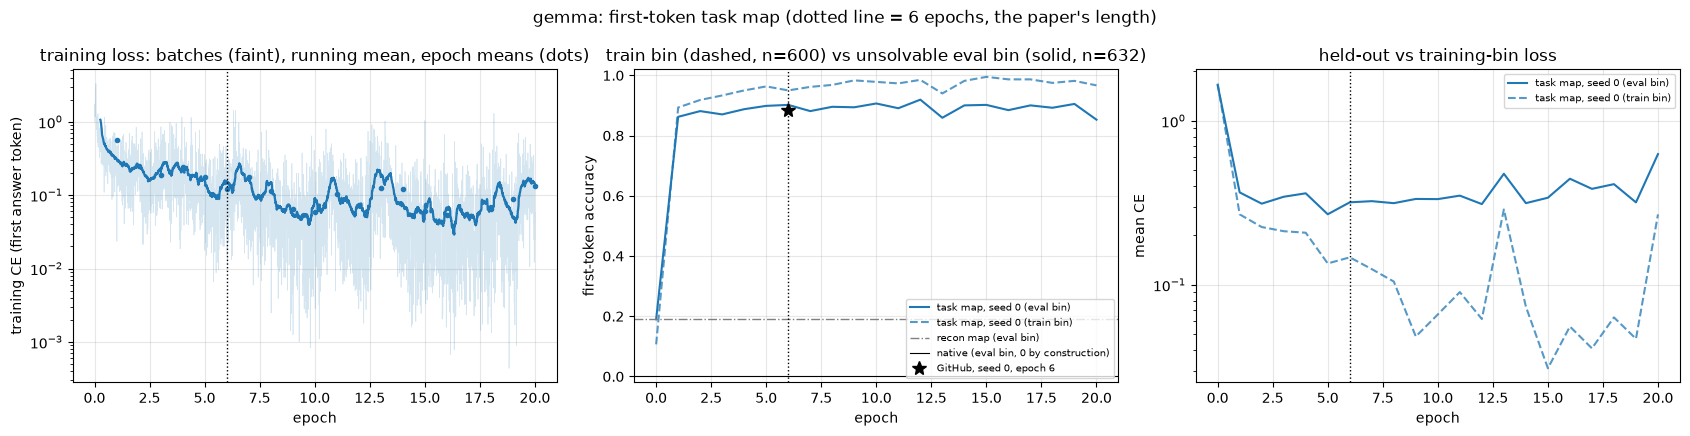

  [plot saved digitk_computation_gemma_plots/P0_first_token_loss.png]
  [498s]
  [saved digitk_computation_gemma.json after 0]


In [9]:
# === CELL 9b: PART 0 — the basic first-token stitch (= GitHub EXP2/EXP3, seed 0), with training-loss curves ===
# Replicates the paper's first stitch (Gemma_eval_EXP13-21 / Qwen_eval_EXP13-19, CELLs 8-10): donor state at
# the last prompt position (states_and_top), ridge reconstruction map, task map trained on the FIRST answer
# token (W from ridge, b = recipient mean, Adam 1e-3, batch 16, order random.Random(seed*100 + ep), 6 epochs),
# scored on the unsolvable bin (the recipient's own first token wrong, the donor's right).
# New here: every batch's training loss is recorded, and after each epoch the training-bin accuracy / loss and
# the eval-bin conferral / loss. The seed-0 run then continues to LONG_EPOCHS so a plateau (or not) is visible;
# its epoch-6 snapshot is the replication, checked against GitHub.
t0 = time.time()
P0 = {}; RESULTS["P0_first_token"] = P0
if RUN_FIRST_TOKEN:
    ft_tr = [dict(ctx=p["ids"], tgt=p["tok"]) for p in train]
    ft_ev = [dict(ctx=p["ids"], tgt=p["tok"]) for p in evalp]
    X2t_ft, r_top_tr = states_and_top(model_r, [L_R], [p["ids"] for p in train]); X2t_ft = X2t_ft[L_R]
    X2e_ft, r_top_ev = states_and_top(model_r, [L_R], [p["ids"] for p in evalp]); X2e_ft = X2e_ft[L_R]
    solv_ft = [i for i in range(len(evalp)) if r_top_ev[i] == evalp[i]["tok"]]
    unsolv_ft = [i for i in range(len(evalp)) if r_top_ev[i] != evalp[i]["tok"]]
    trbin_ft = [i for i in range(len(train)) if D_FIRST_TR[i] and r_top_tr[i] != train[i]["tok"]]
    DS["FT"] = dict(tr=ft_tr, ev=ft_ev, IN={"tr": {"FT": X9T_FT}, "ev": {"FT": X9E_FT}}, X2tr=X2t_ft, X2ev=X2e_ft,
                    BIN=unsolv_ft, TRBIN=trbin_ft, TRBIN_MON=_sample(trbin_ft, MONITOR_SAMPLE))
    MAPS["FT"] = {}
    ep_total = LONG_EPOCHS if RUN_LONG and LONG_EPOCHS > TASK_EPOCHS else TASK_EPOCHS
    M = train_map("FT_task_s0", "linear", ft_tr, X9T_FT, X2t_ft, seed=0, epochs=ep_total, monitor=make_monitor("FT", "FT"),
                  snapshot_epochs=(TASK_EPOCHS,) if ep_total > TASK_EPOCHS else ())
    MAPS["FT"]["task_s0"] = (snapshot_map(M, TASK_EPOCHS) if ep_total > TASK_EPOCHS else M, "FT")
    if ep_total > TASK_EPOCHS: MAPS["FT"][f"task_s0_ep{ep_total}"] = (M, "FT")
    for sd in [x for x in FT_SEEDS if x != 0]:
        MAPS["FT"][f"task_s{sd}"] = (train_map(f"FT_task_s{sd}", "linear", ft_tr, X9T_FT, X2t_ft, seed=sd), "FT")
    M6 = MAPS["FT"]["task_s0"][0]
    MAPS["FT"]["recon"] = (dict(W=M6["W0"], b=X2t_ft.float().mean(0).to(DEVICE), mu=M6["mu"], W1=None), "FT")
    def _ft_first(name, idx): return R(conf("FT", name, "ev", idx)[0])
    def _ft_full(name, idx):
        vecs = list(apply_map(MAPS["FT"][name][0], X9E_FT[idx]).cpu()) if name else None
        return R(arith_fullanswer_correct(model_r, L_R, [evalp[j] for j in idx], vecs=vecs))
    P0.update(n_donor_solved=len(evalp), n_unsolvable=len(unsolv_ft), n_solvable=len(solv_ft),
              recon_first_unsolv=_ft_first("recon", unsolv_ft), recon_full_unsolv=_ft_full("recon", unsolv_ft),
              native_full_unsolv=_ft_full(None, unsolv_ft))
    for name in [n for n in MAPS["FT"] if n.startswith("task_")]:
        Mn = MAPS["FT"][name][0]
        P0[name] = {"epochs": len(Mn["ce"]), "first_unsolv": _ft_first(name, unsolv_ft), "full_unsolv": _ft_full(name, unsolv_ft),
                    "first_solv": _ft_first(name, solv_ft), "mean_CE_per_epoch": Mn["ce"], "plateau": plateau_readout(Mn["ce"])}
    spe = M["steps_per_epoch"]
    P0["training_loss"] = {"last_batch_CE_at_epoch_6 (= GitHub 'final batch CE')": M["step_loss"][TASK_EPOCHS * spe - 1],
                           "last_batch_size": len(train) - (spe - 1) * BATCH,
                           "mean_CE_per_epoch": M["ce"], "plateau": plateau_readout(M["ce"]),
                           "curve (per epoch: train-bin / eval-bin accuracy and CE)": M["curve"]}
    PER_ITEM["FT/step_loss_seed0"] = M["step_loss"]
    # the rest of GitHub CELL 10: cosine of the written vector to the recipient's own state (all eval problems),
    # and the shuffle control (task map fed another problem's state; GitHub's randperm after torch.manual_seed(4),
    # the last seed its training loop set; the permutation depends on how many eval problems were kept)
    _Mr, _Mt = MAPS["FT"]["recon"][0], MAPS["FT"]["task_s0"][0]
    with torch.no_grad():
        P0["recon_cos_recon"] = round(float(F.cosine_similarity(apply_map(_Mr, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
        P0["recon_cos_task"] = round(float(F.cosine_similarity(apply_map(_Mt, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
    _shuf = torch.randperm(len(evalp), generator=torch.Generator().manual_seed(4))
    _sh_rows = torch.cat([_shuf[i:i + len(unsolv_ft[i:i + BATCH])] for i in range(0, len(unsolv_ft), BATCH)])
    P0["shuffle_first_unsolv"] = R(conf("FT", "task_s0", "ev", unsolv_ft, inp=X9E_FT[_sh_rows])[0])
    print(f"  bins: donor solves {len(evalp)} | recipient natively solves {len(solv_ft)} | unsolvable n={len(unsolv_ft)}")
    print(f"  recon: first {P0['recon_first_unsolv']['ci']} full {P0['recon_full_unsolv']['ci']} | native full {P0['native_full_unsolv']['ci']} | "
          f"shuffle first {P0['shuffle_first_unsolv']['ci']} | recon cosine: recon map {P0['recon_cos_recon']}, task map {P0['recon_cos_task']}")
    for name in [n for n in MAPS["FT"] if n.startswith("task_")]:
        r_ = P0[name]
        print(f"  {name:16s} ({r_['epochs']} epochs): first {r_['first_unsolv']['ci']} | full {r_['full_unsolv']['ci']} | "
              f"solvable-bin first {r_['first_solv']['rate']} | training loss {r_['plateau']['label']}")
    print("  per-epoch (train-bin acc / eval-bin acc / train-bin CE / eval-bin CE): " +
          "  ".join(f"ep{c['epoch']} {c['train_bin']}/{c['eval_bin']}/{c['train_bin_CE']}/{c['eval_bin_CE']}" for c in M["curve"]))
    print("SANITY (first-token stitch, epoch 6, vs GitHub EXP2/EXP3 seed 0):")
    F_ = REF["ft"]
    check("FT unsolvable bin n", len(unsolv_ft), F_["n_unsolv"], 2, warn=8)
    check("FT task first token (unsolvable)", P0["task_s0"]["first_unsolv"]["rate"], F_["task_first"], 0.02, warn=0.035)
    check("FT recon first token (unsolvable)", P0["recon_first_unsolv"]["rate"], F_["recon_first"], 0.02, warn=0.035)
    check("FT task full answer (unsolvable; GitHub = 5-seed mean)", P0["task_s0"]["full_unsolv"]["rate"], F_["task_full"], 0.025, warn=0.04)
    check("FT recon full answer (unsolvable)", P0["recon_full_unsolv"]["rate"], F_["recon_full"], 0.015, warn=0.03)
    check("FT native full answer (unsolvable)", P0["native_full_unsolv"]["rate"], F_["native_full"], 0.01, warn=0.02)
    check("FT task first token (solvable bin)", P0["task_s0"]["first_solv"]["rate"], F_["task_solv_first"], 0.02, warn=0.035)
    check("FT recon cosine, recon map (all eval)", P0["recon_cos_recon"], F_["recon_cos_recon"], 0.005, warn=0.015)
    check("FT recon cosine, task map (all eval)", P0["recon_cos_task"], F_["recon_cos_task"], 0.015, warn=0.04)
    check("FT shuffle control first token (unsolvable)", P0["shuffle_first_unsolv"]["rate"], F_["shuffle_first"], 0.03, warn=0.05)
    check("FT last-batch CE at epoch 6 (an 8-problem batch; noisy, informational)",
          P0["training_loss"]["last_batch_CE_at_epoch_6 (= GitHub 'final batch CE')"], F_["final_batch_ce"], 0.05, warn=0.2)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
    plot_run(M, "task map, seed 0", ax[0], ax[1], ax[2], raw=True, color=_PALETTE["task"])
    ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training CE (first answer token)")
    ax[0].set_title("training loss: batches (faint), running mean, epoch means (dots)")
    ax[1].axhline(P0["recon_first_unsolv"]["rate"], c="grey", ls="-.", lw=1, label="recon map (eval bin)")
    ax[1].axhline(0.0, c="k", lw=0.8, label="native (eval bin, 0 by construction)")
    ax[1].plot([TASK_EPOCHS], [REF["ft"]["task_first"]], "k*", ms=10, label="GitHub, seed 0, epoch 6")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("first-token accuracy"); ax[1].set_ylim(-0.02, 1.02)
    ax[1].set_title(f"train bin (dashed, n={len(DS['FT']['TRBIN_MON'])}) vs unsolvable eval bin (solid, n={len(unsolv_ft)})")
    ax[1].legend(fontsize=7, loc="lower right")
    ax[2].set_xlabel("epoch"); ax[2].set_ylabel("mean CE"); ax[2].set_yscale("log"); ax[2].legend(fontsize=7)
    ax[2].set_title("held-out vs training-bin loss")
    _finish(fig, ax, os.path.join(PLOT_DIR, "P0_first_token_loss.png"),
            f"{PAIR}: first-token task map (dotted line = {TASK_EPOCHS} epochs, the paper's length)")
print(f"  [{time.time()-t0:.0f}s]"); save("0")

In [10]:
# === CELL 10: PART P — was digit k (or an intermediate) computed at each source? (+ S2 sanity) ===
# Held-out probes, fit on ALL training items (gold labels), scored per item on the EVAL BIN.
# Baselines a probe must beat:
#   majority      the most common label in training
#   prefix        the most common label given the answer length and digits 1..k-1 (the recipient sees these)
#   recipient     the same probes on the RECIPIENT's own graft-site state (also reported on all eval items,
#                 since the bin is selected for recipient failure)
# Labels (paired bootstrap of the best probe vs the best baseline, per item):
#   PRESENT if the lower bound > SESOI; absent if the upper bound < SESOI; otherwise weak/uncertain.
# Also:
#   +prefix       a probe on [state, prefix one-hot] against the prefix lookup: beyond what the recipient has
#   intermediate  a·b's digit at digit k's place value: is there a partial result to transfer?
#   logit lens    DEEP_PRED through the donor's own unembedding: the decodability ceiling
t0 = time.time()
P = {}
if S2_STATES is not None:
    ev3 = DS[3]["ev"]; t3 = S2_STATES["items"]
    y = torch.tensor([[int(c) for c in ev3[i]["astr"]] for i in t3]); h = len(t3) // 2
    print("SANITY (Emergence S2: 3-digit eval answers in S2's own batches, first half -> second half, linear probe):")
    check("S2 n items", len(t3), REF["s2_n"], 0, warn=3)
    if not SMOKE_TEST: check("S2 sweep layers", float(SWEEP == sorted(REF["s2"])), 1.0, 0)
    P["S2_reproduction"] = {}
    for L in SWEEP:
        X = S2_STATES["X"][L].float()                                   # [n, 3 positions, d]
        g = {"prefill_d2": digit_probe(X[:h, 0], y[:h, 1], X[h:, 0], y[h:, 1]),
             "diag_d2": digit_probe(X[:h, 1], y[:h, 1], X[h:, 1], y[h:, 1]),
             "diag_d3": digit_probe(X[:h, 2], y[:h, 2], X[h:, 2], y[h:, 2])}
        P["S2_reproduction"][f"layer_{L}"] = g
        if L in REF["s2"]:
            for key, v in g.items(): check(f"S2 layer {L} {key}", v, REF["s2"][L][key], 0.02, warn=0.04)

# Which probe kind (linear / MLP) and which baseline is "best" is chosen on eval items OUTSIDE the bin
# (held out from training too), then tested on the bin, so the choice does not peek at the test items.
def _sel(k):
    D = DS[k]; bs = set(D["BIN"]); nb = [i for i in range(len(D["ev"])) if i not in bs]
    return nb if len(nb) >= 30 else D["BIN"]
def _lookup_vec(k, key_fn, field="dk", idx=None):
    tab = collections.defaultdict(collections.Counter)
    for it in DS[k]["tr"]: tab[key_fn(it)][it[field]] += 1
    maj = collections.Counter(it[field] for it in DS[k]["tr"]).most_common(1)[0][0]
    idx = DS[k]["BIN"] if idx is None else idx
    return [float((tab[key_fn(it)].most_common(1)[0][0] if tab[key_fn(it)] else maj) == it[field])
            for it in (DS[k]["ev"][i] for i in idx)]
def _probe_vecs(k, Xtr, Xev, field="dk"):
    """Linear + MLP probe: per-item correctness on the eval bin and on the selection items, rates on all eval."""
    D = DS[k]; ytr = labels(k, "tr", field=field); yev = labels(k, "ev", field=field); B = D["BIN"]; SL = _sel(k)
    pl = lin_probe_logits(lin_probe_fit(Xtr, ytr), Xev).argmax(1); pm = mlp_probe_logits(mlp_probe_fit(Xtr, ytr), Xev).argmax(1)
    return {"lin": [float(x) for x in (pl[B] == yev[B]).tolist()], "mlp": [float(x) for x in (pm[B] == yev[B]).tolist()],
            "lin_sel": rate((pl[SL] == yev[SL]).tolist()), "mlp_sel": rate((pm[SL] == yev[SL]).tolist()),
            "lin_all_eval": rate((pl == yev).tolist()), "mlp_all_eval": rate((pm == yev).tolist())}
def presence_label(p):
    if p["lo"] is None: return "n/a"
    if p["lo"] > SESOI: return "PRESENT"
    if p["hi"] < SESOI: return "absent (gain over baseline < SESOI)"
    return "weak / uncertain"
def _with_prefix(k, X, split, s):
    return torch.cat([X.float(), s * DS[k]["IN"][split]["PREFIX"]], 1)
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; out = {"digit_k": {}, "intermediate_product_digit": {}, "depth_sweep": {}}
    for field, tgt_key in (("dk", "digit_k"), ("pdig", "intermediate_product_digit")):
        SL = _sel(k)
        lk = {"majority": lambda it: 0, "prefix_lookup": lambda it: (len(it["astr"]), it["prefix"])}
        base = {n: _lookup_vec(k, f, field) for n, f in lk.items()}
        base_sel = {n: rate(_lookup_vec(k, f, field, SL)) for n, f in lk.items()}
        rv = _probe_vecs(k, D["X2tr"], D["X2ev"], field)
        base["recipient_linear"], base["recipient_mlp"] = rv["lin"], rv["mlp"]
        base_sel["recipient_linear"], base_sel["recipient_mlp"] = rv["lin_sel"], rv["mlp_sel"]
        bb = max(base, key=lambda n: base_sel[n])
        res = {"baselines": {n: rate(v) for n, v in base.items()}, "best_baseline": bb, "best_baseline_rate_on_bin": rate(base[bb]),
               "recipient_all_eval": {"lin": rv["lin_all_eval"], "mlp": rv["mlp_all_eval"]}, "sources": {}}
        if field == "dk":
            sc2 = float(D["X2tr"].float().std(0).mean())
            rvp = _probe_vecs(k, _with_prefix(k, D["X2tr"], "tr", sc2), _with_prefix(k, D["X2ev"], "ev", sc2), field)
            pbase = {"prefix_lookup": base["prefix_lookup"], "recipient_linear+prefix": rvp["lin"], "recipient_mlp+prefix": rvp["mlp"]}
            pbase_sel = {"prefix_lookup": base_sel["prefix_lookup"], "recipient_linear+prefix": rvp["lin_sel"], "recipient_mlp+prefix": rvp["mlp_sel"]}
            pbb = max(pbase, key=lambda n: pbase_sel[n])
        for s in SRC:
            v = _probe_vecs(k, D["IN"]["tr"][s], D["IN"]["ev"][s], field)
            best = "lin" if v["lin_sel"] >= v["mlp_sel"] else "mlp"
            p = paired(base[bb], v[best])
            res["sources"][s] = {"lin": rate(v["lin"]), "mlp": rate(v["mlp"]), "lin_all_eval": v["lin_all_eval"],
                                 "mlp_all_eval": v["mlp_all_eval"], "best": best, "minus_best_baseline": p, "label": presence_label(p)}
            if field == "dk" and s in ("PREFILL", "MID_PRED"):
                sc = float(D["IN"]["tr"][s].float().std(0).mean())
                vp = _probe_vecs(k, _with_prefix(k, D["IN"]["tr"][s], "tr", sc), _with_prefix(k, D["IN"]["ev"][s], "ev", sc), field)
                bp_ = "lin" if vp["lin_sel"] >= vp["mlp_sel"] else "mlp"
                pp = paired(pbase[pbb], vp[bp_])
                res["sources"][s]["with_prefix"] = {"lin": rate(vp["lin"]), "mlp": rate(vp["mlp"]), "baseline": pbb,
                                                    "baseline_rate": rate(pbase[pbb]), "minus_baseline": pp, "label": presence_label(pp)}
        if field == "dk":
            ll = (D["IN"]["ev"]["DEEP_PRED"][B].float() @ WU_DIG.T).argmax(1)
            res["logit_lens_DEEP_PRED"] = rate((ll == labels(k, "ev", B)).tolist())
            ceil = max(res["logit_lens_DEEP_PRED"], res["sources"]["DEEP_PRED"]["lin"], res["sources"]["DEEP_PRED"]["mlp"])
            bbr = float(np.mean(base[bb]))
            for s, r in res["sources"].items():
                r["normalised_presence"] = round((max(r["lin"], r["mlp"]) - bbr) / (ceil - bbr), 3) if ceil - bbr > 0.02 else None
        out[tgt_key] = res
    for pk in ("eq", "sp", "pred"):
        for L in SWEEP:
            v = _probe_vecs(k, D["Str"][(pk, L)], D["Sev"][(pk, L)])
            out["depth_sweep"][f"{pk}@L{L}"] = {"lin": rate(v["lin"]), "mlp": rate(v["mlp"])}
    P[f"d{k}"] = out
    dk_, pd_ = out["digit_k"], out["intermediate_product_digit"]
    print(f"\n  DIGIT {k} (eval bin n={len(B)}) — digit-{k} baselines {dk_['baselines']} | logit lens DEEP_PRED {dk_['logit_lens_DEEP_PRED']}")
    for s, r in dk_["sources"].items():
        extra = f" | +prefix {r['with_prefix']['lin']}/{r['with_prefix']['mlp']} -> {r['with_prefix']['label']}" if "with_prefix" in r else ""
        print(f"     {s:13s} ({SRC_NOTE[s]:52s}) lin {r['lin']} mlp {r['mlp']} | minus best baseline "
              f"{r['minus_best_baseline']['ci']} -> {r['label']} | normalised {r['normalised_presence']}{extra}")
    print(f"     intermediate (a*b digit) baselines {pd_['baselines']}: " +
          " | ".join(f"{s} {r['lin']}/{r['mlp']} -> {r['label']}" for s, r in pd_["sources"].items()))
    print("     depth sweep (lin/mlp): " + "  ".join(f"{kk} {v['lin']}/{v['mlp']}" for kk, v in out["depth_sweep"].items()))
RESULTS["P_presence"] = P
print(f"  [{time.time()-t0:.0f}s]"); save("P")

SANITY (Emergence S2: 3-digit eval answers in S2's own batches, first half -> second half, linear probe):
  PASS  S2 n items                                           github 1384   this run 1384
  PASS  S2 sweep layers                                      github 1.0   this run 1.0
  PASS  S2 layer 34 prefill_d2                               github 0.16   this run 0.16
  PASS  S2 layer 34 diag_d2                                  github 0.182   this run 0.182
  PASS  S2 layer 34 diag_d3                                  github 0.585   this run 0.585
  PASS  S2 layer 37 prefill_d2                               github 0.22   this run 0.22
  PASS  S2 layer 37 diag_d2                                  github 0.364   this run 0.364
  PASS  S2 layer 37 diag_d3                                  github 0.71   this run 0.71
  PASS  S2 layer 41 prefill_d2                               github 0.24   this run 0.24
  PASS  S2 layer 41 diag_d2                                  github 0.455   this run 0.45

In [19]:
# === CELL 11: PART T — train every map (S4's three first, then the S4 sanity check, then the rest) ===
t0 = time.time()
_NULLS.clear(); _TNULL.clear()
def _plan(k):
    plan = [("PREFILL", "linear", "PREFILL", 0, True), ("DEEP_PRED", "linear", "DEEP_PRED", 0, False),
            ("PRESENT", "linear", "PRESENT", 0, True), ("CONST", "const", "PREFILL", 0, True),
            ("PREFIX", "writer", "PREFIX", 0, True), ("MID_PRED", "linear", "MID_PRED", 0, True)]
    if RUN_EXTRA_SEED: plan += [("PREFILL_s1", "linear", "PREFILL", 1, False), ("MID_PRED_s1", "linear", "MID_PRED", 1, False)]
    if "MID_PRED_MID" in SRC: plan.append(("MID_PRED_MID", "linear", "MID_PRED_MID", 0, False))
    plan += [("PRODUCT", "writer", "PRODUCT", 0, False), ("GOLD", "writer", "GOLD", 0, False),
             ("PREFILL_PFX", "linear", "PREFILL_PFX", 0, False), ("MID_PRED_PFX", "linear", "MID_PRED_PFX", 0, False)]
    if "MID_PRED_MID" in SRC: plan.append(("MID_PRED_MID_PFX", "linear", "MID_PRED_MID_PFX", 0, False))
    if RUN_MLP_MAP: plan += [("PREFILL_MLP", "mlp", "PREFILL", 0, False), ("MID_PRED_MLP", "mlp", "MID_PRED", 0, False)]
    return plan
for k in K_LIST:
    D = DS[k]; D["TRBIN_MON"] = _sample(D["TRBIN"], MONITOR_SAMPLE)
    for split in ("tr", "ev"):
        items = D[split]
        D["IN"][split]["PRODUCT"] = torch.cat([digit_onehot([str(it["abc"][0] * it["abc"][1]).zfill(4) for it in items], 4),
                                               D["IN"][split]["PREFIX"]], 1)
        D["IN"][split]["GOLD"] = torch.cat([digit_onehot([[it["dk"]] for it in items], 1), D["IN"][split]["PREFIX"]], 1)
    for base in [b_ for b_ in ("PREFILL", "MID_PRED", "MID_PRED_MID") if b_ in SRC]:
        D["PFX_SCALE"][base] = float(D["IN"]["tr"][base].float().std(0).mean())   # puts the one-hots on the state's scale
        for split in ("tr", "ev"):
            D["IN"][split][base + "_PFX"] = torch.cat([D["IN"][split][base].float(),
                                                       D["PFX_SCALE"][base] * D["IN"][split]["PREFIX"]], 1)
    plan = _plan(k)
    print(f"\n  DIGIT {k}: training {[p[0] for p in plan]}")
    for name, kind, src, seed, mon in plan:
        kd, lam = ("linear", WRITER_LAMBDA) if kind == "writer" else (kind, RIDGE_LAMBDA)
        long_ = RUN_LONG and name in LONG_MAPS and LONG_EPOCHS > TASK_EPOCHS
        M = train_map(f"d{k}_{name}", kd, D["tr"], D["IN"]["tr"][src], D["X2tr"], seed=seed,
                      monitor=make_monitor(k, src) if mon else None, lam=lam,
                      epochs=LONG_EPOCHS if long_ else None, snapshot_epochs=(TASK_EPOCHS,) if long_ else ())
        if long_:                               # the epoch-6 snapshot is the map every other part uses
            MAPS[k][name] = (snapshot_map(M, TASK_EPOCHS), src); MAPS[k][f"{name}_ep{LONG_EPOCHS}"] = (M, src)
        else:
            MAPS[k][name] = (M, src)
        if k == 2 and name == "PRESENT":
            print("  SANITY (digit-2 conferral on S4's population vs GitHub S4):")
            F4 = D["S4FAIL"]; s4 = {}
            for nm, key in (("A", "PREFILL"), ("B", "DEEP_PRED"), ("C", "PRESENT")):
                s4[nm] = rate(conf(2, key, "ev", F4)[0])
            order = list(F4); random.Random(0).shuffle(order)                  # = S4's shuffle (not a derangement)
            s4["C_shuffle"] = rate(conf(2, "PRESENT", "ev", F4, inp=D["IN"]["ev"]["PRESENT"][order])[0])
            for nm in ("A", "B", "C", "C_shuffle"):
                check(f"S4 {nm} digit-2 conferral", s4[nm], REF["s4"][nm], 0.015, warn=0.03)
            RESULTS["S4_reproduction"] = s4; save("S4 check")
    save(f"trained d{k}")
if 2 in K_LIST and RUN_EXTRA_SEED:
    RESULTS["S4_reproduction"]["A_seed1_same_population"] = rate(conf(2, "PREFILL_s1", "ev", DS[2]["S4FAIL"])[0])
    print(f"  training-order noise yardstick: PREFILL seed 0 {RESULTS['S4_reproduction']['A']} vs seed 1 "
          f"{RESULTS['S4_reproduction']['A_seed1_same_population']} on S4's population")
RESULTS["adam_steps"] = {f"d{k}/{n}": MAPS[k][n][0]["steps"] for k in K_LIST for n in MAPS[k]}
print(f"  [{time.time()-t0:.0f}s]"); save("T")


  DIGIT 2: training ['PREFILL', 'DEEP_PRED', 'PRESENT', 'CONST', 'PREFIX', 'MID_PRED', 'PREFILL_s1', 'MID_PRED_s1', 'MID_PRED_MID', 'PRODUCT', 'GOLD', 'PREFILL_PFX', 'MID_PRED_PFX', 'MID_PRED_MID_PFX', 'PREFILL_MLP', 'MID_PRED_MLP']
    [d2_PREFILL] loaded from digitk_computation_gemma_maps_digitk-v3/d2_PREFILL_e20.pt


/tmp/ipykernel_2014/1616633713.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  M = torch.load(path, map_location=DEVICE)


    [d2_DEEP_PRED] loaded from digitk_computation_gemma_maps_digitk-v3/d2_DEEP_PRED_e6.pt
    [d2_PRESENT] loaded from digitk_computation_gemma_maps_digitk-v3/d2_PRESENT_e6.pt
  SANITY (digit-2 conferral on S4's population vs GitHub S4):
  PASS  S4 A digit-2 conferral                               github 0.234   this run 0.2336
  PASS  S4 B digit-2 conferral                               github 0.515   this run 0.515
  PASS  S4 C digit-2 conferral                               github 0.999   this run 0.9992
  PASS  S4 C_shuffle digit-2 conferral                       github 0.102   this run 0.1022
  [saved digitk_computation_gemma.json after S4 check]
    [d2_CONST] loaded from digitk_computation_gemma_maps_digitk-v3/d2_CONST_e20.pt
    [d2_PREFIX] loaded from digitk_computation_gemma_maps_digitk-v3/d2_PREFIX_e20.pt
    [d2_MID_PRED] loaded from digitk_computation_gemma_maps_digitk-v3/d2_MID_PRED_e20.pt
    [d2_PREFILL_s1] loaded from digitk_computation_gemma_maps_digitk-v3/d2_PREFILL_

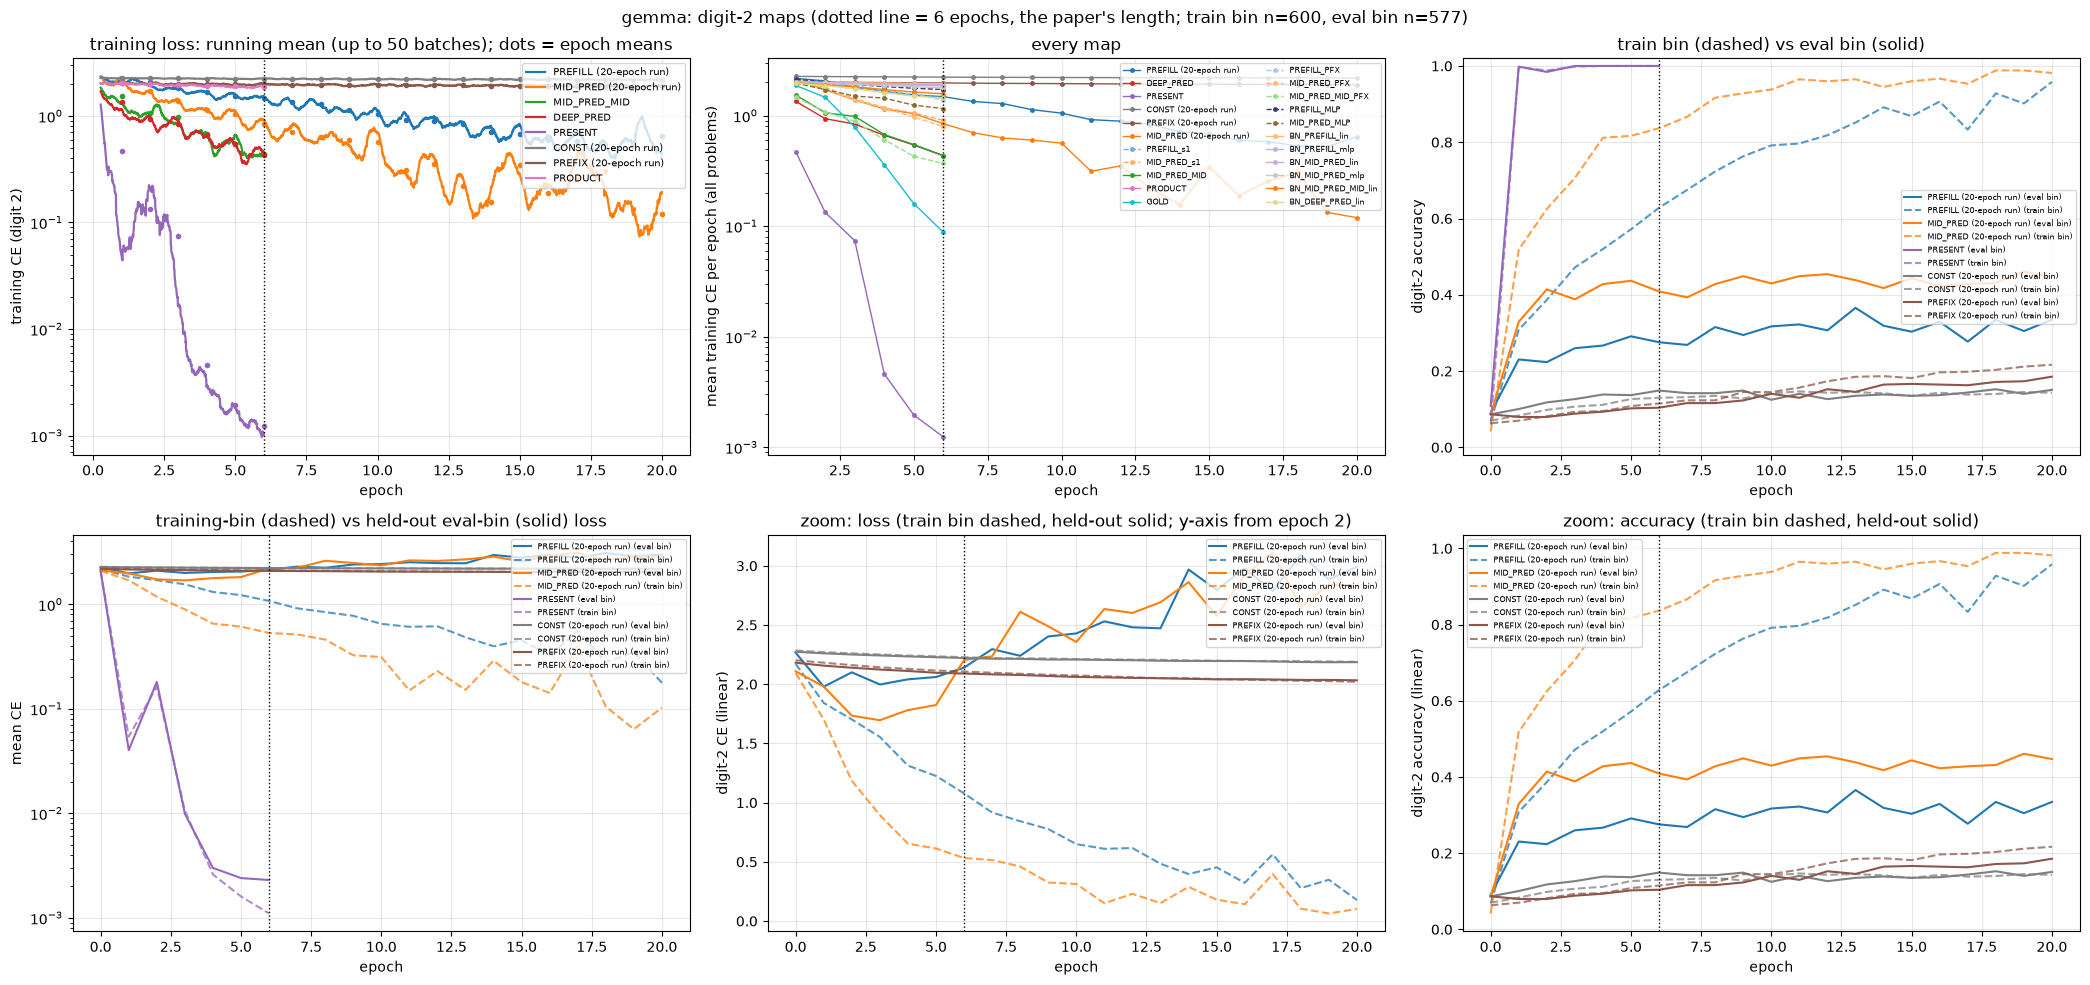

  [plot saved digitk_computation_gemma_plots/PL_digit2_loss.png]

  DIGIT 2 — loss per epoch and plateau read-out (training-bin CE where monitored):
     PREFILL (20-epoch run)     [training-bin CE] [1.842, 1.7024, 1.5546, 1.3128, 1.2252, 1.0783, 0.9165, 0.843, 0.7767, 0.65, 0.6099, 0.6164, 0.4839, 0.3971, 0.4535, 0.3225, 0.5627, 0.278, 0.3488, 0.1775] -> still falling (68% over the last 3 epochs) (log-slope -0.3846, share of drop in last 3 epochs 0.231)
     DEEP_PRED                  [all-problem mean CE] [1.348, 0.9385, 0.8384, 0.6641, 0.5422, 0.4327] -> still falling (48% over the last 3 epochs) (log-slope -0.2205, share of drop in last 3 epochs 0.443)
     PRESENT                    [training-bin CE] [0.0541, 0.1633, 0.0106, 0.0026, 0.0016, 0.0011] -> at ~0 (CE 0.0011 < 0.01: fits these problems) (log-slope -0.7552, share of drop in last 3 epochs 0.179)
     CONST (20-epoch run)       [training-bin CE] [2.2708, 2.2609, 2.2514, 2.2421, 2.2358, 2.2283, 2.2204, 2.2182, 2.2178, 2.2123

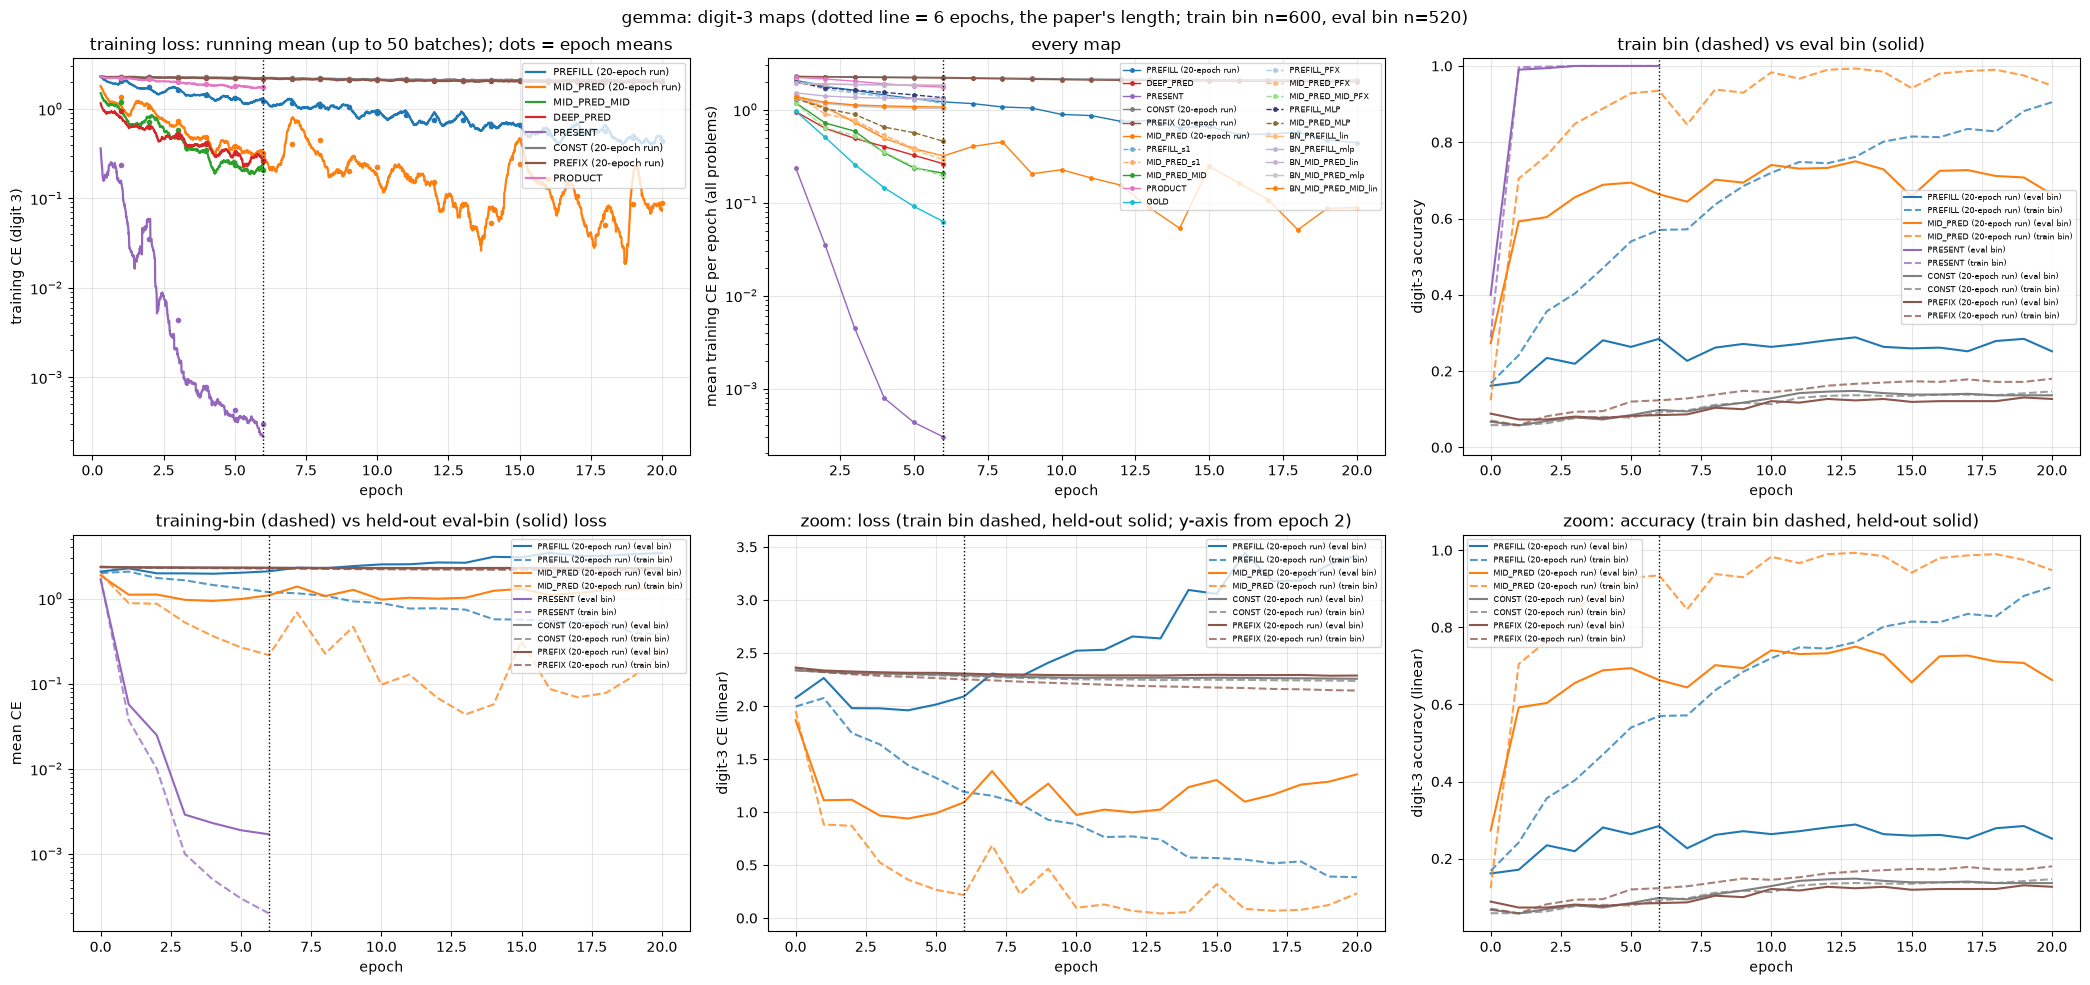

  [plot saved digitk_computation_gemma_plots/PL_digit3_loss.png]

  DIGIT 3 — loss per epoch and plateau read-out (training-bin CE where monitored):
     PREFILL (20-epoch run)     [training-bin CE] [2.0747, 1.745, 1.6378, 1.443, 1.3221, 1.1892, 1.1539, 1.078, 0.9261, 0.8856, 0.7642, 0.77, 0.7416, 0.5713, 0.5658, 0.5521, 0.5164, 0.5342, 0.3918, 0.3855] -> still falling (25% over the last 3 epochs) (log-slope -0.0974, share of drop in last 3 epochs 0.077)
     DEEP_PRED                  [all-problem mean CE] [0.9544, 0.6297, 0.4908, 0.4006, 0.323, 0.2617] -> still falling (47% over the last 3 epochs) (log-slope -0.2096, share of drop in last 3 epochs 0.331)
     PRESENT                    [training-bin CE] [0.0373, 0.01, 0.001, 0.0005, 0.0003, 0.0002] -> at ~0 (CE 0.0002 < 0.01: fits these problems) (log-slope -0.5365, share of drop in last 3 epochs 0.022)
     CONST (20-epoch run)       [training-bin CE] [2.3192, 2.307, 2.3005, 2.2959, 2.2897, 2.281, 2.2734, 2.2641, 2.2598, 2.2506, 2.2

In [20]:
# === CELL 11b: PART L — training-loss curves for every digit-k map, and the plateau read-out ===
# Per digit (2 x 3 panels): (a) training loss per batch (running mean) and per epoch (dots), log scale, the main
# maps; (b) per-epoch mean training CE for every map; (c) accuracy per epoch on the training bin (dashed) and the
# eval bin (solid); (d) the same as mean CE; (e) and (f) LINEAR-scale zoom on the four maps that matter here
# (PREFILL, MID_PRED and the nulls CONST, PREFIX), side by side: loss and accuracy, each on the training bin
# (dashed) and the held-out eval bin (solid). Loss falling while accuracy stays flat = the map grows more
# confident without getting more problems right; training loss falling while held-out loss rises = memorising;
# held-out loss below the nulls' with flat accuracy = some digit-k information arriving below the argmax. PREFILL, MID_PRED, CONST
# and PREFIX run to LONG_EPOCHS ("20-epoch run"); their first 6 epochs ARE the 6-epoch maps used everywhere else.
# Plateau read-out (on the training-BIN CE, the hard problems, where the monitor has it; otherwise the all-problem
# mean): still falling / rising / flattening / at ~0, with the log-slope and the share of the whole drop in the
# last 3 epochs ("flattening" is not a proof of a plateau).
# Long runs vs the nulls, at epoch 6 and at LONG_EPOCHS: training-bin and eval-bin conferral and CE minus each null
# (CONST, PREFIX); the reference null is the stronger one ON THE TRAINING BIN (chosen away from the eval items).
# Mechanical label as in Part 1: fit and generalised / memorised / did not fit beyond the null. Descriptive:
# one seed, uncorrected. More epochs test the optimiser, not the capacity of a linear map.
t0 = time.time()
PL = {}; RESULTS["PL_loss_curves"] = PL
MAIN_PLOT = ["PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED", "PRESENT", "CONST", "PREFIX", "PRODUCT"]
ZOOM = ["PREFILL", "MID_PRED", "CONST", "PREFIX"]
def _lab(n): return re.sub(r"_ep(\d+)$", r" (\1-epoch run)", n)
def _fit_label(tr, ev):
    tr_low = tr["hi"] is not None and tr["hi"] < SESOI
    if above(tr) and above(ev): return "fit training and generalised above the null"
    if above(tr): return "MEMORISED: training bin above the null, eval bin not"
    if tr_low and above(ev): return "did not fit training beyond the null, yet above it on eval (check)"
    if tr_low: return "did not fit its training problems beyond the null"
    return "inconclusive"
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; PL[f"d{k}"] = {"maps": {}, "long_vs_null": {}}
    lng = lambda n: f"{n}_ep{LONG_EPOCHS}" if f"{n}_ep{LONG_EPOCHS}" in MAPS[k] else n
    for name, (M, _) in MAPS[k].items():
        tb = [c.get("train_bin_CE") for c in (M.get("curve") or [])[1:]]
        PL[f"d{k}"]["maps"][name] = {"mean_CE_per_epoch (all training problems)": M["ce"],
                                     "train_bin_CE_per_epoch": tb if any(x is not None for x in tb) else None,
                                     "plateau": plateau_readout(tb if any(x is not None for x in tb) else M["ce"]),
                                     "plateau_on": "training-bin CE" if any(x is not None for x in tb) else "all-problem mean CE",
                                     "last_batch_CE": (M["step_loss"][-1] if M.get("step_loss") else None)}
        if not M.get("snapshot_of_epoch"): PER_ITEM[f"d{k}/{name}/step_loss"] = M.get("step_loss")
    fig, ax = plt.subplots(2, 3, figsize=(21, 10)); ax = ax.ravel()
    for n in [n for n in MAIN_PLOT if n in MAPS[k]]:
        plot_run(MAPS[k][lng(n)][0], _lab(lng(n)), ax[0], color=_color_for(n))
    for n, (M, _) in MAPS[k].items():
        if M.get("snapshot_of_epoch") or not M.get("ce"): continue
        ax[1].plot(np.arange(1, len(M["ce"]) + 1), M["ce"], marker="o", ms=2.5, lw=1, label=_lab(n), color=_color_for(n),
                   ls="--" if n.endswith(("_s1", "_MLP", "_PFX")) else "-")
    for n in [n for n in ("PREFILL", "MID_PRED", "PRESENT", "CONST", "PREFIX") if n in MAPS[k]]:
        Mn = MAPS[k][lng(n)][0]
        if Mn.get("curve"): plot_run({"curve": Mn["curve"]}, _lab(lng(n)), ax[0], ax[2], ax[3], color=_color_for(n))
    _zv = []                                            # loss values from epoch 2 on, to fit the zoom's y-axis
    for n in [n for n in ZOOM if n in MAPS[k]]:
        cv = MAPS[k][lng(n)][0].get("curve") or []
        if cv:
            _zv += [c[key] for c in cv if c["epoch"] >= 2 for key in ("eval_bin_CE", "train_bin_CE") if c.get(key) is not None]
            e = [c["epoch"] for c in cv]
            ax[4].plot(e, [c["eval_bin_CE"] for c in cv], "-", color=_color_for(n), label=f"{_lab(lng(n))} (eval bin)")
            ax[4].plot(e, [c["train_bin_CE"] for c in cv], "--", color=_color_for(n), alpha=0.75, label=f"{_lab(lng(n))} (train bin)")
            ax[5].plot(e, [c["eval_bin"] for c in cv], "-", color=_color_for(n), label=f"{_lab(lng(n))} (eval bin)")
            ax[5].plot(e, [c["train_bin"] for c in cv], "--", color=_color_for(n), alpha=0.75, label=f"{_lab(lng(n))} (train bin)")
    ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel(f"training CE (digit {k})"); ax[0].legend(fontsize=7, loc="upper right")
    ax[0].set_title("training loss: running mean (up to 50 batches); dots = epoch means")
    ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("mean training CE per epoch (all problems)")
    ax[1].legend(fontsize=6, ncol=2, loc="upper right"); ax[1].set_title("every map")
    ax[2].set_xlabel("epoch"); ax[2].set_ylabel(f"digit-{k} accuracy"); ax[2].set_ylim(-0.02, 1.02)
    ax[2].legend(fontsize=6, loc="center right"); ax[2].set_title("train bin (dashed) vs eval bin (solid)")
    ax[3].set_xlabel("epoch"); ax[3].set_ylabel("mean CE"); ax[3].set_yscale("log"); ax[3].legend(fontsize=6, loc="upper right")
    ax[3].set_title("training-bin (dashed) vs held-out eval-bin (solid) loss")
    ax[4].set_xlabel("epoch"); ax[4].set_ylabel(f"digit-{k} CE (linear)"); ax[4].legend(fontsize=6, loc="upper right")
    ax[4].set_title("zoom: loss (train bin dashed, held-out solid; y-axis from epoch 2)")
    if _zv:
        _pad = 0.05 * (max(_zv) - min(_zv) + 1e-9); ax[4].set_ylim(min(_zv) - _pad, max(_zv) + _pad)
    ax[5].set_xlabel("epoch"); ax[5].set_ylabel(f"digit-{k} accuracy (linear)"); ax[5].legend(fontsize=6, loc="upper left")
    ax[5].set_title("zoom: accuracy (train bin dashed, held-out solid)")
    _finish(fig, ax, os.path.join(PLOT_DIR, f"PL_digit{k}_loss.png"),
            f"{PAIR}: digit-{k} maps (dotted line = {TASK_EPOCHS} epochs, the paper's length; train bin n={len(D['TRBIN_MON'])}, eval bin n={len(B)})")
    # long runs vs the nulls at epoch 6 and at LONG_EPOCHS
    for n in [n for n in ("PREFILL", "MID_PRED") if f"{n}_ep{LONG_EPOCHS}" in MAPS[k]]:
        row = {}
        for tag, nm, nulls in ((f"epoch_{TASK_EPOCHS}", n, ("CONST", "PREFIX")),
                               (f"epoch_{LONG_EPOCHS}", f"{n}_ep{LONG_EPOCHS}", (f"CONST_ep{LONG_EPOCHS}", f"PREFIX_ep{LONG_EPOCHS}"))):
            nulls = [nu for nu in nulls if nu in MAPS[k]]
            m_tr, _, m_trce = conf(k, nm, "tr", D["TRBIN"], want_ce=True); m_ev, _, m_evce = conf(k, nm, "ev", B, want_ce=True)
            nv = {nu: (conf(k, nu, "tr", D["TRBIN"], want_ce=True), conf(k, nu, "ev", B, want_ce=True)) for nu in nulls}
            st = max(nv, key=lambda nu: np.mean(nv[nu][0][0]))             # stronger null ON THE TRAINING BIN
            per_null = {}
            for nu, ((t_ok, _, t_ce), (e_ok, _, e_ce)) in nv.items():
                per_null[nu] = {"train_bin_minus_null": paired([float(x) for x in t_ok], [float(x) for x in m_tr]),
                                "eval_bin_minus_null": paired([float(x) for x in e_ok], [float(x) for x in m_ev]),
                                "train_bin_CE_map_minus_null": round(float(np.mean(m_trce) - np.mean(t_ce)), 4),
                                "eval_bin_CE_map_minus_null": round(float(np.mean(m_evce) - np.mean(e_ce)), 4)}
            row[tag] = {"train_bin": rate(m_tr), "eval_bin": rate(m_ev), "train_bin_CE": round(float(np.mean(m_trce)), 4),
                        "eval_bin_CE": round(float(np.mean(m_evce)), 4), "reference_null (stronger on the training bin)": st,
                        "per_null": per_null,
                        "label": _fit_label(per_null[st]["train_bin_minus_null"], per_null[st]["eval_bin_minus_null"])}
        a6, aL = row[f"epoch_{TASK_EPOCHS}"], row[f"epoch_{LONG_EPOCHS}"]
        st6, stL = a6["reference_null (stronger on the training bin)"], aL["reference_null (stronger on the training bin)"]
        row["summary"] = (f"epoch {TASK_EPOCHS}: {a6['label']} (train {a6['per_null'][st6]['train_bin_minus_null']['ci']}, eval "
                          f"{a6['per_null'][st6]['eval_bin_minus_null']['ci']} vs {st6}) -> epoch {LONG_EPOCHS}: {aL['label']} (train "
                          f"{aL['per_null'][stL]['train_bin_minus_null']['ci']}, eval {aL['per_null'][stL]['eval_bin_minus_null']['ci']} vs {stL}) | "
                          f"training-bin CE {a6['train_bin_CE']} -> {aL['train_bin_CE']}, eval-bin CE {a6['eval_bin_CE']} -> {aL['eval_bin_CE']} "
                          f"| descriptive: one seed, uncorrected")
        PL[f"d{k}"]["long_vs_null"][n] = row
    print(f"\n  DIGIT {k} — loss per epoch and plateau read-out (training-bin CE where monitored):")
    for name, r_ in PL[f"d{k}"]["maps"].items():
        if MAPS[k][name][0].get("snapshot_of_epoch"): continue
        ser = r_["train_bin_CE_per_epoch"] or r_["mean_CE_per_epoch (all training problems)"]
        print(f"     {_lab(name):26s} [{r_['plateau_on']}] {ser} -> {r_['plateau']['label']} "
              f"(log-slope {r_['plateau'].get('log_slope_per_epoch_last_window')}, share of drop in last 3 epochs "
              f"{r_['plateau'].get('share_of_total_drop_in_last_window')})")
    for n, row in PL[f"d{k}"]["long_vs_null"].items():
        print(f"     LONG {n}: {row['summary']}")
print(f"  [{time.time()-t0:.0f}s]"); save("L")

In [21]:
# === CELL 12: PART 1 — could the map just memorise? Own training problems vs eval, against the fair null ===
# train_bin = the map's OWN training problems with the eval bin's filter. For each source map, the map minus
# its strongest fair null, on training and on eval:
#   train ~ null (upper bound < SESOI)       -> did not fit its training problems either (claim 2 holds)
#   train > null, eval not                    -> MEMORISED: fit training without anything generalisable
#   train > null and eval > null              -> fit and generalised
# 'curve' = conferral after each epoch (epoch 0 = the ridge starting map); max_*_above_trained_null compares
# it with the fair trained null's own curve.
t0 = time.time()
P1 = {}
FIT_MAPS = ["PREFILL", "MID_PRED", "MID_PRED_MID", "PREFILL_PFX", "MID_PRED_PFX"]
for k in K_LIST:
    D = DS[k]; P1[f"d{k}"] = {"maps": {}, "fit_vs_null": {}}
    print(f"\n  DIGIT {k} (train bin n={len(D['TRBIN'])}, eval bin n={len(D['BIN'])})")
    print(f"     {'map':13s} {'train bin':>22s} {'eval bin':>22s} | CE train/eval bin | train all | eval all | S4 population")
    for name in [n for n in MAPS[k] if not re.search(r"_ep\d+$", n)]:
        row = {}
        for lab, split, idx in (("train_bin", "tr", D["TRBIN"]), ("train_all", "tr", list(range(len(D["tr"])))),
                                ("eval_bin", "ev", D["BIN"]), ("eval_all", "ev", list(range(len(D["ev"])))),
                                ("eval_S4_population", "ev", D["S4FAIL"])):
            ok, tops, ces = conf(k, name, split, idx, want_ce=True)
            row[lab] = {**R(ok), "mean_CE": round(float(np.mean(ces)), 4) if ces else None}
            if lab in ("train_bin", "eval_bin"): PER_ITEM[f"d{k}/{name}/{lab}"] = [int(x) for x in ok]
        M = MAPS[k][name][0]; row["ce_per_epoch"] = M["ce"]; row["curve"] = M["curve"]
        P1[f"d{k}"]["maps"][name] = row
        print(f"     {name:13s} {str(row['train_bin']['ci']):>22s} {str(row['eval_bin']['ci']):>22s} | "
              f"{row['train_bin']['mean_CE']} / {row['eval_bin']['mean_CE']} | {row['train_all']['rate']} | "
              f"{row['eval_all']['rate']} | {row['eval_S4_population']['rate']}")
    for name in [n for n in FIT_MAPS if n in MAPS[k]]:
        r = {}
        for lab, split, idx in (("train_bin", "tr", D["TRBIN"]), ("eval_bin", "ev", D["BIN"])):
            nv = null_vectors(k, name, split, idx, lab); st = strongest(nv)
            r[lab] = {"map": rate(PER_ITEM[f"d{k}/{name}/{lab}"]), "nulls": {n: rate(v) for n, v in nv.items()},
                      "strongest_null": st, "map_minus_strongest": paired(nv[st], PER_ITEM[f"d{k}/{name}/{lab}"])}
        tr_, ev_ = r["train_bin"]["map_minus_strongest"], r["eval_bin"]["map_minus_strongest"]
        tr_low = tr_["hi"] is not None and tr_["hi"] < SESOI
        if above(tr_) and above(ev_): lab_ = "fit training and generalised above the null"
        elif above(tr_): lab_ = "MEMORISED: fits training above the null, nothing above the null on eval (claim 2 false)"
        elif tr_low and above(ev_): lab_ = "did not fit training beyond the null, yet above it on eval (check)"
        elif tr_low: lab_ = "did not fit its training problems beyond the null (claim 2 holds)"
        else: lab_ = "inconclusive"
        r["label"] = lab_
        curve = MAPS[k][name][0]["curve"]; ncs = [MAPS[k][n][0]["curve"] for n in TRAINED_NULLS]
        if curve and all(nc and len(nc) == len(curve) for nc in ncs):
            r["max_eval_above_trained_nulls_over_epochs"] = round(max(c["eval_bin"] - max(nc[i]["eval_bin"] for nc in ncs) for i, c in enumerate(curve)), 4)
            r["max_train_above_trained_nulls_over_epochs"] = round(max(c["train_bin"] - max(nc[i]["train_bin"] for nc in ncs) for i, c in enumerate(curve)), 4)
        P1[f"d{k}"]["fit_vs_null"][name] = r
        print(f"     FIT {name:13s} train {r['train_bin']['map']} vs {r['train_bin']['strongest_null']} "
              f"{r['train_bin']['nulls'][r['train_bin']['strongest_null']]}: {tr_['ci']} | eval {r['eval_bin']['map']} vs "
              f"{r['eval_bin']['strongest_null']}: {ev_['ci']} -> {lab_}"
              + (f" | max over epochs eval/train above CONST/PREFIX {r.get('max_eval_above_trained_nulls_over_epochs')}/"
                 f"{r.get('max_train_above_trained_nulls_over_epochs')}" if "max_eval_above_trained_nulls_over_epochs" in r else ""))
    for name in [n for n in MAPS[k] if not re.search(r"_ep\d+$", n)]:
        if MAPS[k][name][0]["curve"]:
            print(f"     curve {name:9s}: " + "  ".join(f"ep{c['epoch']} {c['train_bin']}/{c['eval_bin']}" for c in MAPS[k][name][0]["curve"]))
RESULTS["P1_training_vs_eval"] = P1
print(f"  [{time.time()-t0:.0f}s]"); save("1")


  DIGIT 2 (train bin n=856, eval bin n=577)
     map                        train bin               eval bin | CE train/eval bin | train all | eval all | S4 population
     PREFILL         0.633 [0.600, 0.665]   0.276 [0.241, 0.313] | 1.0777 / 2.1399 | 0.5699 | 0.2823 | 0.2336
     DEEP_PRED       0.947 [0.930, 0.960]   0.769 [0.733, 0.802] | 0.1732 / 0.6555 | 0.898 | 0.5901 | 0.515
     PRESENT         1.000 [0.996, 1.000]   1.000 [0.993, 1.000] | 0.001 / 0.0023 | 1.0 | 0.9994 | 0.9992
     CONST           0.134 [0.113, 0.159]   0.149 [0.122, 0.180] | 2.2244 / 2.2211 | 0.1664 | 0.1926 | 0.1225
     PREFIX          0.119 [0.099, 0.143]   0.104 [0.082, 0.132] | 2.1107 / 2.09 | 0.2451 | 0.225 | 0.0908
     MID_PRED        0.838 [0.811, 0.861]   0.409 [0.370, 0.450] | 0.5433 / 2.2048 | 0.7976 | 0.3603 | 0.2944
     PREFILL_s1      0.588 [0.554, 0.620]   0.243 [0.209, 0.279] | 1.1944 / 2.2268 | 0.5155 | 0.2499 | 0.2076
     MID_PRED_s1     0.874 [0.850, 0.894]   0.419 [0.380, 0.460] | 0.5

In [22]:
# === CELL 13: PART 2 — above the fair nulls? (+ positive controls, by answer length) ===
# PRIMARY (per digit, PREFILL and MID_PRED): the per-item mean of the seed-0 and seed-1 maps minus the strongest
# fair null (CONST or PREFIX, and SHUF_PFX), Holm-corrected over the 4 cells in the SUMMARY.
# Also every source map vs each null; SHUF_LEN (length-matched only) with its partner-following rate next
# to CONST's rate of emitting that partner digit (chance); the positive controls PRESENT / GOLD / PRODUCT
# minus PREFIX. PRODUCT above PREFIX means the recipient CAN finish the problem from a transferred
# intermediate at this site.
t0 = time.time()
P2 = {}
SOURCE_MAPS = ["PREFILL", "PREFILL_s1", "MID_PRED", "MID_PRED_s1", "MID_PRED_MID", "PREFILL_PFX", "MID_PRED_PFX",
               "MID_PRED_MID_PFX", "PREFILL_MLP", "MID_PRED_MLP", "DEEP_PRED", "PRESENT"]
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; P2[f"d{k}"] = {"sources": {}, "primary": {}, "controls": {}}
    const_ok, const_tops = conf(k, "CONST", "ev", B)
    pre_ok = PER_ITEM[f"d{k}/PREFIX/eval_bin"]
    print(f"\n  DIGIT {k} — eval bin n={len(B)} | CONST {rate(const_ok)} | PREFIX {rate(pre_ok)}")
    for name in [n for n in SOURCE_MAPS if n in MAPS[k]]:
        own = PER_ITEM[f"d{k}/{name}/eval_bin"]; nv = null_vectors(k, name, "ev", B, "eval_bin"); st = strongest(nv)
        row = {"own": R(own), "nulls": {n: rate(v) for n, v in nv.items()}, "strongest_null": st,
               "vs_null": {n: paired(v, own) for n, v in nv.items()}}
        row["label"] = effect_label(row["vs_null"][st], "gain over the fair nulls")
        perm, fixed = derange(D["ev"], B, KEYS_LEN, 0)
        ok, tops = conf(k, name, "ev", B, inp=map_input(k, name, "ev", perm, B))
        diff = [n_ for n_, (j, pj) in enumerate(zip(B, perm)) if D["ev"][j]["dk"] != D["ev"][pj]["dk"]]
        row["SHUF_LEN"] = {"own_digit": R(ok), "follows_partner_digit": R([tops[n_] == DIGIT_TOK[D["ev"][perm[n_]]["dk"]] for n_ in diff]),
                           "CONST_emits_partner_digit (chance)": R([const_tops[n_] == DIGIT_TOK[D["ev"][perm[n_]]["dk"]] for n_ in diff])}
        row["by_answer_length"] = {}
        for L_ in sorted({len(D["ev"][j]["astr"]) for j in B}):
            sel = [n_ for n_, j in enumerate(B) if len(D["ev"][j]["astr"]) == L_]
            row["by_answer_length"][L_] = {"n": len(sel), "own": rate([own[n_] for n_ in sel]),
                                           "strongest_null": rate([nv[st][n_] for n_ in sel])}
        P2[f"d{k}"]["sources"][name] = row
        print(f"     {name:13s} own {row['own']['ci']} | nulls {row['nulls']} | minus {st} {row['vs_null'][st]['ci']} -> {row['label']} | "
              f"SHUF_LEN follows partner {row['SHUF_LEN']['follows_partner_digit']['rate']} (chance {row['SHUF_LEN']['CONST_emits_partner_digit (chance)']['rate']}) | "
              f"by length {row['by_answer_length']}")
    for S in ("PREFILL", "MID_PRED"):
        if S not in MAPS[k]: continue
        mv = np.asarray(PER_ITEM[f"d{k}/{S}/eval_bin"], float); seeds = [0]
        if f"{S}_s1" in MAPS[k]:
            mv = (mv + np.asarray(PER_ITEM[f"d{k}/{S}_s1/eval_bin"], float)) / 2; seeds = [0, 1]
        nv = dict(null_vectors(k, S, "ev", B, "eval_bin"))
        if f"{S}_s1" in MAPS[k]: nv["SHUF_PFX"] = _nanavg(nv["SHUF_PFX"], null_vectors(k, f"{S}_s1", "ev", B, "eval_bin")["SHUF_PFX"])
        st = strongest(nv); p = paired(nv[st], mv)
        P2[f"d{k}"]["primary"][S] = {"seeds_averaged": seeds, "map_mean": round(float(mv.mean()), 4), "strongest_null": st,
                                     "null_rate": rate(nv[st]), "map_minus_null": p, "p_boot": p["p_boot"]}
        print(f"     PRIMARY {S}: seed-mean {round(float(mv.mean()), 4)} minus {st} {rate(nv[st])}: {p['ci']} (p {p['p_boot']})")
    for nm in ("PRESENT", "GOLD", "PRODUCT"):
        if nm in MAPS[k]:
            c_ok = PER_ITEM[f"d{k}/{nm}/eval_bin"]
            P2[f"d{k}"]["controls"][f"{nm}_minus_PREFIX"] = paired(pre_ok, c_ok)
            P2[f"d{k}"]["controls"][nm] = R(c_ok)
            print(f"     control {nm:8s} {R(c_ok)['ci']} | minus PREFIX {P2[f'd{k}']['controls'][f'{nm}_minus_PREFIX']['ci']}")
    if "PRODUCT" in MAPS[k]:
        # a writer told a*b and the prefix could guess digit k WITHOUT adding c: the best guess from (a*b, answer
        # length, prefix) over every c in [1, 99]. PRODUCT shows the recipient combined the intermediate with its own
        # c only if it beats both PREFIX and this lookup.
        def _c_ignorant_ok(it):
            a, b, _ = it["abc"]; cnt = collections.Counter()
            for c2 in range(1, 100):
                y2 = str(a * b + c2)
                if len(y2) == len(it["astr"]) and y2[:k - 1] == it["prefix"]: cnt[int(y2[k - 1])] += 1
            return float(bool(cnt) and cnt.most_common(1)[0][0] == it["dk"])
        lk_ok = [_c_ignorant_ok(D["ev"][i]) for i in B]; prod_ok = PER_ITEM[f"d{k}/PRODUCT/eval_bin"]
        ref_nm, ref_v = max((("PREFIX", [float(x) for x in pre_ok]), ("c_ignorant_lookup", lk_ok)), key=lambda t: np.mean(t[1]))
        P2[f"d{k}"]["controls"]["c_ignorant_lookup"] = rate(lk_ok)
        P2[f"d{k}"]["controls"]["PRODUCT_minus_strongest_reference"] = {"reference": ref_nm, **paired(ref_v, prod_ok)}
        print(f"     control PRODUCT minus {ref_nm} (c-ignorant lookup {rate(lk_ok)}): "
              f"{P2[f'd{k}']['controls']['PRODUCT_minus_strongest_reference']['ci']}")
RESULTS["P2_nulls"] = P2
print(f"  [{time.time()-t0:.0f}s]"); save("2")


  DIGIT 2 — eval bin n=577 | CONST 0.149 | PREFIX 0.104
     PREFILL       own 0.276 [0.241, 0.313] | nulls {'CONST': 0.149, 'PREFIX': 0.104, 'SHUF_PFX': 0.1297} | minus CONST +0.127 [+0.083, +0.170] -> ABOVE (+0.127 [+0.083, +0.170]) | SHUF_LEN follows partner 0.2673 (chance 0.1115) | by length {2: {'n': 28, 'own': 0.1786, 'strongest_null': 0.0}, 3: {'n': 478, 'own': 0.2218, 'strongest_null': 0.1192}, 4: {'n': 71, 'own': 0.6761, 'strongest_null': 0.4085}}
     PREFILL_s1    own 0.243 [0.209, 0.279] | nulls {'CONST': 0.149, 'PREFIX': 0.104, 'SHUF_PFX': 0.1152} | minus CONST +0.094 [+0.054, +0.133] -> ABOVE (+0.094 [+0.054, +0.133]) | SHUF_LEN follows partner 0.2269 (chance 0.1115) | by length {2: {'n': 28, 'own': 0.1071, 'strongest_null': 0.0}, 3: {'n': 478, 'own': 0.182, 'strongest_null': 0.1192}, 4: {'n': 71, 'own': 0.7042, 'strongest_null': 0.4085}}
     MID_PRED      own 0.409 [0.370, 0.450] | nulls {'CONST': 0.149, 'PREFIX': 0.104, 'SHUF_PFX': 0.1268} | minus CONST +0.260 [+0.211

In [23]:
# === CELL 14: PART 3 — room to do better: SVD truncation (EXP10 method, + r = 0) and the MLP map ===
#   'dW' (primary): keep the ridge starting map, truncate only the learned update W - W_ridge (r = 0 = ridge)
#   'W'           : truncate the whole trained W (= EXP10; r = 0 = bias only)
# r90 = smallest rank recovering 90% of the full-rank gain over r = 0, on eval and on training problems.
# Eval r90 is only meaningful when the map is above its fair null; training r90 shows where any training
# fit (memorisation) lives. PRESENT is the capacity reference.
t0 = time.time()
P3 = {}
def _r90(rows, key):
    full, zero = rows["full"][key], rows[0][key]
    if full is None or zero is None or full - zero <= 0.02: return None
    return next(r for r, v in rows.items() if v[key] - zero >= 0.9 * (full - zero))
for k in K_LIST:
    D = DS[k]; B = D["BIN"]; TS = _sample(D["TRBIN"], TRAIN_SAMPLE, seed=1); P3[f"d{k}"] = {}
    for name in [n for n in ("PREFILL", "MID_PRED", "PRESENT") if n in MAPS[k]]:
        M = MAPS[k][name][0]
        gate_ev = (RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"].get(name, {}).get("eval_bin", {}).get("map_minus_strongest")
                   if name != "PRESENT" else RESULTS["P2_nulls"][f"d{k}"]["sources"]["PRESENT"]["vs_null"][
                       RESULTS["P2_nulls"][f"d{k}"]["sources"]["PRESENT"]["strongest_null"]])
        gate_tr = RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"].get(name, {}).get("train_bin", {}).get("map_minus_strongest")
        P3[f"d{k}"][name] = {"full_rank": int(min(M["W"].shape)), "eval_above_null": above(gate_ev),
                             "train_above_null": above(gate_tr) if gate_tr else None}
        for mode in ("dW", "W"):
            base = (M["W"] - M["W0"] if mode == "dW" else M["W"]).float()
            U, Sv, Vh = torch.linalg.svd(base, full_matrices=False)
            energy = (Sv.pow(2).cumsum(0) / Sv.pow(2).sum()).tolist()
            rows = {}
            for r in [0] + [r for r in SVD_RANKS if r < Sv.numel()] + [Sv.numel()]:
                Wt = (U[:, :r] * Sv[:r]) @ Vh[:r] if r > 0 else torch.zeros_like(base)
                if mode == "dW": Wt = M["W0"].float() + Wt
                rows["full" if r == Sv.numel() else r] = {"energy": round(energy[r - 1], 3) if r > 0 else 0.0,
                                                          "eval_bin": rate(conf(k, name, "ev", B, W=Wt)[0]),
                                                          "train_bin_sample": rate(conf(k, name, "tr", TS, W=Wt)[0])}
                del Wt
            r90e, r90t = _r90(rows, "eval_bin"), _r90(rows, "train_bin_sample")
            P3[f"d{k}"][name][f"truncate_{mode}"] = {"ranks": rows, "r90_eval": r90e if P3[f"d{k}"][name]["eval_above_null"] else
                                                     f"n/a (map not above its fair null; raw r90 {r90e})", "r90_train": r90t}
            print(f"  d{k} {name:9s} truncate {mode:2s}: r90 eval {P3[f'd{k}'][name][f'truncate_{mode}']['r90_eval']} | r90 train {r90t} | " +
                  "  ".join(f"r{r}: {v['eval_bin']}/{v['train_bin_sample']}" for r, v in rows.items()) + "   (eval/train)")
            del U, Sv, Vh, base
    for lin, mlp in (("PREFILL", "PREFILL_MLP"), ("MID_PRED", "MID_PRED_MLP")):
        if lin in MAPS[k] and mlp in MAPS[k]:
            P3[f"d{k}"][f"{mlp}_minus_{lin}"] = {
                "eval_bin": paired(PER_ITEM[f"d{k}/{lin}/eval_bin"], PER_ITEM[f"d{k}/{mlp}/eval_bin"], alpha=0.01),
                "train_bin": paired(PER_ITEM[f"d{k}/{lin}/train_bin"], PER_ITEM[f"d{k}/{mlp}/train_bin"], alpha=0.01)}
            print(f"  d{k} MLP map minus linear map ({lin}), 99%: eval {P3[f'd{k}'][f'{mlp}_minus_{lin}']['eval_bin']['ci']} | "
                  f"train {P3[f'd{k}'][f'{mlp}_minus_{lin}']['train_bin']['ci']}")
RESULTS["P3_room"] = P3
print(f"  [{time.time()-t0:.0f}s]"); save("3")

  d2 PREFILL   truncate dW: r90 eval 64 | r90 train 64 | r0: 0.0884/0.0712  r1: 0.0936/0.08  r2: 0.1646/0.1462  r4: 0.1248/0.15  r8: 0.2132/0.2188  r16: 0.2478/0.3262  r32: 0.253/0.4863  r64: 0.2704/0.5925  r128: 0.2686/0.6225  r256: 0.2773/0.6312  rfull: 0.2721/0.6362   (eval/train)
  d2 PREFILL   truncate W : r90 eval 64 | r90 train 128 | r0: 0.0867/0.0775  r1: 0.1092/0.125  r2: 0.0971/0.105  r4: 0.156/0.1525  r8: 0.1785/0.1975  r16: 0.2132/0.275  r32: 0.2478/0.4263  r64: 0.2565/0.5337  r128: 0.2617/0.6012  r256: 0.2669/0.6262  rfull: 0.2721/0.635   (eval/train)
  d2 MID_PRED  truncate dW: r90 eval 64 | r90 train 64 | r0: 0.0832/0.0425  r1: 0.1196/0.1275  r2: 0.1057/0.1113  r4: 0.1092/0.12  r8: 0.208/0.2725  r16: 0.2721/0.4688  r32: 0.3674/0.66  r64: 0.3951/0.7662  r128: 0.4107/0.825  r256: 0.4159/0.8375  rfull: 0.4125/0.845   (eval/train)
  d2 MID_PRED  truncate W : r90 eval 64 | r90 train 128 | r0: 0.0867/0.0762  r1: 0.1127/0.1062  r2: 0.0936/0.0912  r4: 0.1231/0.13  r8: 0.2028/0.2

In [24]:
# === CELL 15: PART 4 — partner swaps: which content drives conferral? ===
# The recipient keeps reading its own problem P; only the donor state comes from P'.
#   ORIG own state | AM same digits 1..k, other operands | PM same digits 1..k-1, digit k differs, other operands
#   AB same a and b (same product), digit k differs
# 'own' = it emits P's digit k; 'partner' = it emits P''s digit k. Contrasts on bin problems that have all
# three partners and no commuted twin in training (paired, 99% intervals):
#   AM - PM     the partner's digit-k-relevant content (operands differ in both)
#   AB - PM     sharing a and b with P (digit k differs in both): the donor sends the product, the recipient adds its own c
#   ORIG - AM   problem-specific content beyond digit k
# READING. Answer transfer and transfer of the partner's *complete* computation predict the same pattern
# (AM ~ ORIG, partner-following in PM/AB). So at a source where Part P finds digit k PRESENT, partner-following
# is answer content; at a source where Part P finds it absent, partner-following means the map carried
# digit-k-relevant content the probes do not read (computation-like, or an unreadable answer; Part 6 decides).
# AB > PM detects only operand sharing. Nothing here is read unless ORIG is above the fair null on these items.
t0 = time.time()
P4 = {}
SWAP_SOURCES = ["PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED", "PRESENT"]
if RUN_SWAPS:
    for k in K_LIST:
        D = DS[k]; B = D["BIN"]; P4[f"d{k}"] = {}
        const_ok, const_tops = conf(k, "CONST", "ev", B)
        for name in [n for n in SWAP_SOURCES if n in MAPS[k]]:
            src = MAPS[k][name][1]; orig_ok = PER_ITEM[f"d{k}/{name}/eval_bin"]; _, orig_tops = conf(k, name, "ev", B)
            nv = null_vectors(k, name, "ev", B, "eval_bin"); st = strongest(nv)
            res, own_by = {}, {"ORIG": dict(enumerate(orig_ok))}
            for ptype in ("AM", "PM", "AB"):
                PT = PART[k][ptype]; bp = PT["bin_pos"]
                if not bp: res[ptype] = {"n": 0}; continue
                idx = [B[j] for j in bp]
                sw_ok, sw_tops = conf(k, name, "ev", idx, inp=PT["IN"][src])
                ptok = [DIGIT_TOK[p["dk"]] for p in PT["items"]]
                r = {"n": len(bp), "ORIG_own": rate([orig_ok[j] for j in bp]), "SWAP_own": R(sw_ok),
                     "CONST_own": rate([const_ok[j] for j in bp])}
                if ptype != "AM":
                    cp = [float(const_tops[j] == pt) for j, pt in zip(bp, ptok)]; sp_ = [float(t == pt) for t, pt in zip(sw_tops, ptok)]
                    r["SWAP_partner"] = R(sp_); r["CONST_partner (chance)"] = rate(cp)
                    r["ORIG_partner (proximity)"] = rate([orig_tops[j] == pt for j, pt in zip(bp, ptok)])
                    r["SWAP_partner_minus_CONST_partner"] = paired(cp, sp_, alpha=0.01)
                res[ptype] = r; own_by[ptype] = dict(zip(bp, sw_ok))
            common = (sorted(j for j in set.intersection(*[set(v) for v in own_by.values()]) if not D["ev"][B[j]]["twin"])
                      if all(t in own_by for t in ("AM", "PM", "AB")) else [])
            if common:
                vec = {t: [float(own_by[t][j]) for j in common] for t in own_by}
                nvc = {n: [v[j] for j in common] for n, v in nv.items()}; stc = strongest(nvc)
                gate = paired(nvc[stc], vec["ORIG"])
                p2s = RESULTS["P2_nulls"][f"d{k}"]["sources"].get(name)
                full_ok = above(p2s["vs_null"][p2s["strongest_null"]]) if p2s else False
                res["contrasts"] = {"n": len(common), "answer_lengths": dict(collections.Counter(len(D["ev"][B[j]]["astr"]) for j in common)),
                                    **{f"own_{t}": rate(v) for t, v in vec.items()}, "null_on_these_items": {stc: rate(nvc[stc])},
                                    "gate ORIG minus fair null": gate, "full_bin_above_null (Part 2)": full_ok,
                                    "informative": above(gate) and full_ok,
                                    "AM - PM": paired(vec["PM"], vec["AM"], alpha=0.01),
                                    "AB - PM": paired(vec["PM"], vec["AB"], alpha=0.01),
                                    "ORIG - AM": paired(vec["AM"], vec["ORIG"], alpha=0.01)}
            else:
                res["contrasts"] = {"n": 0, "informative": False}
            P4[f"d{k}"][name] = res
            c = res["contrasts"]
            print(f"\n  d{k} {name:12s} common n={c['n']}" + ("" if not c["n"] else
                  f" | gate ORIG-null {c['gate ORIG minus fair null']['ci']} ({'informative' if c['informative'] else 'UNINFORMATIVE'}) | own: "
                  f"ORIG {c['own_ORIG']} AM {c['own_AM']} PM {c['own_PM']} AB {c['own_AB']} | AM-PM {c['AM - PM']['ci']} | "
                  f"AB-PM {c['AB - PM']['ci']} | ORIG-AM {c['ORIG - AM']['ci']}"))
            for ptype in ("PM", "AB"):
                r = res.get(ptype, {})
                if r.get("n"):
                    print(f"      {ptype}: partner digit {r['SWAP_partner']['ci']} vs chance {r['CONST_partner (chance)']} / proximity "
                          f"{r['ORIG_partner (proximity)']} (99%: {r['SWAP_partner_minus_CONST_partner']['ci']}) | own {r['SWAP_own']['rate']} vs CONST {r['CONST_own']}")
RESULTS["P4_partner_swaps"] = P4
print(f"  [{time.time()-t0:.0f}s]"); save("4")


  d2 PREFILL      common n=157 | gate ORIG-null +0.142 [+0.068, +0.218] (informative) | own: ORIG 0.2611 AM 0.2229 PM 0.0573 AB 0.1019 | AM-PM +0.166 [+0.057, +0.268] | AB-PM +0.045 [-0.038, +0.121] | ORIG-AM +0.038 [-0.076, +0.153]
      PM: partner digit 0.296 [0.255, 0.339] vs chance 0.0889 / proximity 0.0689 (99%: +0.207 [+0.144, +0.269]) | own 0.04 vs CONST 0.1511
      AB: partner digit 0.223 [0.179, 0.274] vs chance 0.1182 / proximity 0.0946 (99%: +0.105 [+0.027, +0.179]) | own 0.1014 vs CONST 0.1014

  d2 MID_PRED     common n=157 | gate ORIG-null +0.346 [+0.261, +0.429] (informative) | own: ORIG 0.4713 AM 0.4395 PM 0.0573 AB 0.0573 | AM-PM +0.382 [+0.268, +0.490] | AB-PM +0.000 [-0.070, +0.070] | ORIG-AM +0.032 [-0.102, +0.166]
      PM: partner digit 0.440 [0.395, 0.486] vs chance 0.0889 / proximity 0.0467 (99%: +0.351 [+0.282, +0.420]) | own 0.0556 vs CONST 0.1511
      AB: partner digit 0.436 [0.381, 0.493] vs chance 0.1182 / proximity 0.0608 (99%: +0.318 [+0.233, +0.405])

In [25]:
# === CELL 16: PART 5 — erase digit k from the donor state before the frozen map ===
# Centered on the training mean; x -> mu + (x - mu) P.
#   class-mean (primary): remove the span of the count-weighted digit-k class means (rank <= 9), every
#                         direction along which the class means differ
#   INLP                  orthogonalised rounds of the zero-init digit_probe, 10 directions each, up to rank 160
# Controls: the SAME procedure on permuted training labels (removes as much variance, no digit k), and random
# directions of the same rank. Held-out probes after erasure check that digit k is gone ('erasure complete'
# when the best probe after is within SESOI of the majority rate). DEEP_PRED and PRESENT show erasure removes
# conferral when digit k is there. A test source is only read if its map is above the fair null.
t0 = time.time()
P5 = {}
def class_mean_dirs(A, y):
    n = len(y); rows = []
    for c in range(10):
        m = (y == c)
        if bool(m.any()): rows.append(A[m].mean(0) * math.sqrt(float(m.sum()) / n))
    _, Sm, Vm = torch.linalg.svd(torch.stack(rows), full_matrices=False)
    return Vm[: int((Sm > 1e-3 * Sm[0]).sum())].T
def inlp_round(A, y, Qall, steps=300, lr=1e-2):
    Pw = torch.zeros(A.shape[1], 10, device=A.device, requires_grad=True)
    opt = torch.optim.Adam([Pw], lr=lr); Ad = A.clone(); yd = y.to(A.device)
    for _ in range(steps):
        opt.zero_grad(); F.cross_entropy(Ad @ Pw, yd).backward(); opt.step()
    Q = Pw.detach()
    for _ in range(2):                                   # Gram-Schmidt against the removed directions, twice
        if Qall is not None: Q = Q - Qall @ (Qall.T @ Q)
    U, sv, _ = torch.linalg.svd(Q, full_matrices=False)  # orthonormal basis of what is genuinely new
    return U[:, sv > 1e-6 * max(float(sv.max()), 1e-30)]
def _probe_after(k, Xtr_e, Xb_e, B):
    yb = labels(k, "ev", B); ytr = labels(k, "tr")
    return {"linear": rate((lin_probe_logits(lin_probe_fit(Xtr_e.cpu(), ytr), Xb_e.cpu()).argmax(1) == yb).tolist()),
            "mlp": rate((mlp_probe_logits(mlp_probe_fit(Xtr_e, ytr), Xb_e).argmax(1) == yb).tolist())}
if RUN_ERASURE:
    for k in K_LIST:
        D = DS[k]; B = D["BIN"]; P5[f"d{k}"] = {}
        y = labels(k, "tr").to(DEVICE)
        y_perm = y[torch.randperm(len(y), generator=torch.Generator().manual_seed(11)).to(DEVICE)]
        chance = max(max(collections.Counter(labels(k, "ev", B).tolist()).values()) / len(B),
                     RESULTS["P_presence"][f"d{k}"]["digit_k"]["best_baseline_rate_on_bin"])     # what a probe gets without digit k
        for name in [n for n in ("PREFILL", "MID_PRED", "MID_PRED_MID", "DEEP_PRED", "PRESENT") if n in MAPS[k]]:
            src = MAPS[k][name][1]; nv = null_vectors(k, name, "ev", B, "eval_bin"); st = strongest(nv)
            Xtr = D["IN"]["tr"][src].float().to(DEVICE).clone(); mu = Xtr.mean(0); A0 = Xtr - mu
            Xb = D["IN"]["ev"][src][B].float().to(DEVICE); EYE = torch.eye(Xtr.shape[1], device=DEVICE)
            proj = lambda X, Pm: mu + (X - mu) @ Pm
            out = {"unerased": rate(PER_ITEM[f"d{k}/{name}/eval_bin"]), "fair_null": {st: rate(nv[st])},
                   "map_above_null": above(paired(nv[st], PER_ITEM[f"d{k}/{name}/eval_bin"]))}
            Qm = class_mean_dirs(A0, y); Qp = class_mean_dirs(A0, y_perm)
            gm = torch.linalg.qr(torch.randn(Xtr.shape[1], Qm.shape[1], device=DEVICE,
                                             generator=torch.Generator(device=DEVICE).manual_seed(7)))[0]
            cm = {"rank": int(Qm.shape[1]), "rank_permuted_control": int(Qp.shape[1])}
            for lab, Q in (("answer_erased", Qm), ("permuted_label_control", Qp), ("random_control", gm)):
                Pm = EYE - Q @ Q.T
                cm[lab] = R(conf(k, name, "ev", B, inp=proj(Xb, Pm))[0])
                if lab == "answer_erased": cm["probe_after"] = _probe_after(k, proj(Xtr, Pm), proj(Xb, Pm), B)
            cm["erasure_complete"] = max(cm["probe_after"].values()) <= chance + SESOI
            out["class_mean"] = cm
            print(f"  d{k} {name:12s} class-mean (rank {cm['rank']}): erased {cm['answer_erased']['ci']} | permuted-label "
                  f"{cm['permuted_label_control']['rate']} | random {cm['random_control']['rate']} | probes after {cm['probe_after']} "
                  f"(baseline {chance:.3f}) | unerased {out['unerased']} | null {st} {rate(nv[st])}")
            def _inlp(yy):
                Qall, res = None, []
                for target in INLP_RANKS:
                    while (0 if Qall is None else Qall.shape[1]) < target:
                        Pm = EYE if Qall is None else EYE - Qall @ Qall.T
                        Q = inlp_round(A0 @ Pm, yy, Qall)
                        if Q.shape[1] == 0: break
                        Qall = Q if Qall is None else torch.cat([Qall, Q], 1)
                    Pm = EYE if Qall is None else EYE - Qall @ Qall.T
                    res.append((0 if Qall is None else int(Qall.shape[1]), R(conf(k, name, "ev", B, inp=proj(Xb, Pm))[0])))
                return res, Pm
            ans_c, Pm_ans = _inlp(y); perm_c, _ = _inlp(y_perm)
            out["INLP_probe_after_deepest"] = _probe_after(k, proj(Xtr, Pm_ans), proj(Xb, Pm_ans), B)
            curve = [{"rank": ra, "answer": a_, "rank_permuted": rp, "permuted_label": p_} for (ra, a_), (rp, p_) in zip(ans_c, perm_c)]
            out["INLP_curve"] = curve
            out["INLP_erasure_complete"] = max(out["INLP_probe_after_deepest"].values()) <= chance + SESOI
            for c in curve:
                print(f"      INLP rank {c['rank']:4d}: digit-{k} erased {c['answer']['ci']} | permuted-label {c.get('permuted_label', {}).get('rate')}")
            print(f"      INLP probes after rank {curve[-1]['rank']}: {out['INLP_probe_after_deepest']}")
            P5[f"d{k}"][name] = out
            del Xtr, A0, Xb, EYE, Pm_ans; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
RESULTS["P5_erasure"] = P5
print(f"  [{time.time()-t0:.0f}s]"); save("5")

  d2 PREFILL      class-mean (rank 9): erased 0.154 [0.127, 0.186] | permuted-label 0.2426 | random 0.2721 | probes after {'linear': 0.1127, 'mlp': 0.2721} (baseline 0.293) | unerased 0.2756 | null CONST 0.149
      INLP rank   10: digit-2 erased 0.269 [0.234, 0.306] | permuted-label 0.2756
      INLP rank   20: digit-2 erased 0.267 [0.232, 0.304] | permuted-label 0.2721
      INLP rank   40: digit-2 erased 0.267 [0.232, 0.304] | permuted-label 0.2738
      INLP rank   80: digit-2 erased 0.265 [0.231, 0.303] | permuted-label 0.2652
      INLP rank  160: digit-2 erased 0.258 [0.224, 0.295] | permuted-label 0.2617
      INLP probes after rank 160: {'linear': 0.1542, 'mlp': 0.2877}
  d2 MID_PRED     class-mean (rank 9): erased 0.140 [0.114, 0.171] | permuted-label 0.3709 | random 0.4125 | probes after {'linear': 0.1386, 'mlp': 0.4055} (baseline 0.293) | unerased 0.409 | null CONST 0.149
      INLP rank   10: digit-2 erased 0.392 [0.353, 0.432] | permuted-label 0.4125
      INLP rank   20:

In [32]:
# === CELL 17: PART 6 — probe bottleneck: does the digit-k readout account for the map? ===
# Reader: a digit-k probe on the donor source (linear = digit_probe, MLP = probe_mlp), CROSS-FITTED over
# N_FOLDS folds: each training problem gets scores from the reader that did not see it; each eval problem
# gets scores from one randomly assigned fold reader (same distribution as the training codes).
# Code = the reader's 10 softmax scores + one-hots of the gold digits 1..k-1 (the recipient already has them).
# Writer = ridge-initialised linear writer with the maps' recipe, data and steps. Compared with:
#   PREFIX   writer fed the prefix one-hots only (the bottleneck's null)
#   CMP      the source's state+prefix map (*_PFX) where it exists, else the plain map
#   GOLD     writer fed gold digit k + prefix (the channel's ceiling; a result is only read if GOLD >= 0.9)
#   HARD     the reader's argmax through the GOLD writer (decoded digit only)
# recovery = (BN - null) / (CMP - null), null = the strongest of CONST / PREFIX / SHUF_PFX for CMP, with a
# bootstrap interval; read only if CMP is above that null and GOLD >= 0.9.
# CMP > BN means the map carried more than the readable digit k: content beyond the readout.
# Gold-label readers can themselves compute digit k from operand features; the recipient-state probes in
# Part P show how much a reader gets from the operands alone.
t0 = time.time()
P6 = {}; RESULTS["P6_bottleneck"] = P6
def crossfit_scores(k, src, kind):
    D = DS[k]; Xtr = D["IN"]["tr"][src].float(); Xev = D["IN"]["ev"][src].float(); y = labels(k, "tr")
    n = len(y); perm = list(range(n)); random.Random(BN_SEED).shuffle(perm)
    folds = [perm[f::N_FOLDS] for f in range(N_FOLDS)]
    Ztr = torch.zeros(n, 10); Zev_all = []
    for f in range(N_FOLDS):
        held = set(folds[f]); fit_i = [i for i in range(n) if i not in held]
        Pr_ = lin_probe_fit(Xtr[fit_i], y[fit_i]) if kind == "lin" else mlp_probe_fit(Xtr[fit_i], y[fit_i])
        lg = (lambda X: lin_probe_logits(Pr_, X)) if kind == "lin" else (lambda X: mlp_probe_logits(Pr_, X))
        Ztr[folds[f]] = F.softmax(lg(Xtr[folds[f]]), -1); Zev_all.append(F.softmax(lg(Xev), -1))
    rng = random.Random(BN_SEED + 1); assign = [rng.randrange(N_FOLDS) for _ in range(Xev.shape[0])]
    Zev = torch.stack([Zev_all[a][i] for i, a in enumerate(assign)])
    return Ztr, Zev
def ratio_ci(bn, cmp_, pre, seed=0):
    bn, cmp_, pre = (np.asarray(v, float) for v in (bn, cmp_, pre))
    keep = ~(np.isnan(bn) | np.isnan(cmp_) | np.isnan(pre)); bn, cmp_, pre = bn[keep], cmp_[keep], pre[keep]; n = len(bn)
    if n == 0: return None
    den0 = cmp_.mean() - pre.mean()
    if abs(den0) < 1e-9: return None
    rng = np.random.default_rng(seed); ix = rng.integers(0, n, (BOOT_B, n))
    num = bn[ix].mean(1) - pre[ix].mean(1); den = cmp_[ix].mean(1) - pre[ix].mean(1); ok = den > 0.005
    lo, hi = np.percentile(num[ok] / den[ok], [2.5, 97.5]) if ok.any() else (float("nan"), float("nan"))
    return {"point": round(float((bn.mean() - pre.mean()) / den0), 3), "lo": round(float(lo), 3), "hi": round(float(hi), 3),
            "share_of_bootstrap_with_positive_denominator": round(float(ok.mean()), 3)}
if RUN_BOTTLENECK:
    for k in K_LIST:
        D = DS[k]; B = D["BIN"]; P6[f"d{k}"] = {}
        gold_ok = PER_ITEM[f"d{k}/GOLD/eval_bin"]; pre_ok = PER_ITEM[f"d{k}/PREFIX/eval_bin"]
        P6[f"d{k}"]["GOLD"] = R(gold_ok); P6[f"d{k}"]["PREFIX"] = R(pre_ok)
        P6[f"d{k}"]["channel_ok (GOLD >= 0.9)"] = rate(gold_ok) >= 0.9
        print(f"\n  DIGIT {k}: GOLD writer {R(gold_ok)['ci']} | PREFIX writer {R(pre_ok)['ci']}")
        for src, kinds in (("PREFILL", ("lin", "mlp")), ("MID_PRED", ("lin", "mlp")), ("MID_PRED_MID", ("lin",)), ("DEEP_PRED", ("lin",))):
            if src not in MAPS[k]: continue
            cmp_name = f"{src}_PFX" if f"{src}_PFX" in MAPS[k] else src
            cmp_ok = PER_ITEM[f"d{k}/{cmp_name}/eval_bin"]
            nvc = null_vectors(k, cmp_name, "ev", B, "eval_bin"); stn = strongest(nvc); null_v = nvc[stn]
            gate = paired(null_v, cmp_ok)
            for kind in kinds:
                nm = f"BN_{src}_{kind}"
                Ztr, Zev = crossfit_scores(k, src, kind)
                D["IN"]["tr"][nm] = torch.cat([Ztr, D["IN"]["tr"]["PREFIX"]], 1); D["IN"]["ev"][nm] = torch.cat([Zev, D["IN"]["ev"]["PREFIX"]], 1)
                MAPS[k][nm] = (train_map(f"d{k}_{nm}", "linear", D["tr"], D["IN"]["tr"][nm], D["X2tr"], lam=WRITER_LAMBDA), nm)
                bn_ok = conf(k, nm, "ev", B)[0]
                hard = torch.cat([digit_onehot([[int(d)] for d in Zev[B].argmax(1).tolist()], 1), D["IN"]["ev"]["PREFIX"][B]], 1)
                hard_ok = conf(k, "GOLD", "ev", B, inp=hard)[0]
                reader_acc = R((Zev[B].argmax(1) == labels(k, "ev", B)).tolist())
                res = {"comparator": cmp_name, "comparator_has_prefix": cmp_name.endswith("_PFX"),
                       "reader_acc_on_bin (cross-fitted)": reader_acc, "BN": R(bn_ok), "HARD": R(hard_ok),
                       "CMP": R(cmp_ok), "PREFIX": rate(pre_ok), "null": {stn: rate(null_v)}, "CMP_minus_null (gate)": gate,
                       "informative": above(gate) and rate(gold_ok) >= 0.9,
                       "BN_minus_CMP": paired(cmp_ok, bn_ok, alpha=0.01), "BN_minus_null": paired(null_v, bn_ok, alpha=0.01),
                       "recovery (zero = strongest null of CMP)": ratio_ci(bn_ok, cmp_ok, null_v),
                       "BN_given_CMP_confers": rate([b for a, b in zip(cmp_ok, bn_ok) if a])}
                P6[f"d{k}"][nm] = res; PER_ITEM[f"d{k}/{nm}/eval_bin"] = [int(x) for x in bn_ok]
                print(f"     {nm:20s} reader {reader_acc['ci']} | BN {R(bn_ok)['ci']} | HARD {rate(hard_ok)} | {cmp_name} {rate(cmp_ok)} "
                      f"(minus {stn} {gate['ci']}, {'informative' if res['informative'] else 'UNINFORMATIVE'}) | BN-CMP {res['BN_minus_CMP']['ci']} | "
                      f"recovery {res['recovery (zero = strongest null of CMP)']}")
        save(f"6 d{k}")
print(f"  [{time.time()-t0:.0f}s]"); save("6")


  DIGIT 2: GOLD writer 0.998 [0.990, 1.000] | PREFIX writer 0.104 [0.082, 0.132]


/tmp/ipykernel_2014/1616633713.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  M = torch.load(path, map_location=DEVICE)


    [d2_BN_PREFILL_lin] loaded from digitk_computation_gemma_maps_digitk-v3/d2_BN_PREFILL_lin_e6.pt
     BN_PREFILL_lin       reader 0.205 [0.174, 0.239] | BN 0.142 [0.116, 0.173] | HARD 0.208 | PREFILL_PFX 0.3068 (minus CONST +0.158 [+0.113, +0.203], informative) | BN-CMP -0.165 [-0.220, -0.109] | recovery {'point': -0.044, 'lo': -0.324, 'hi': 0.158, 'share_of_bootstrap_with_positive_denominator': 1.0}
    [d2_BN_PREFILL_mlp] loaded from digitk_computation_gemma_maps_digitk-v3/d2_BN_PREFILL_mlp_e6.pt
     BN_PREFILL_mlp       reader 0.250 [0.216, 0.286] | BN 0.189 [0.159, 0.223] | HARD 0.253 | PREFILL_PFX 0.3068 (minus CONST +0.158 [+0.113, +0.203], informative) | BN-CMP -0.118 [-0.170, -0.061] | recovery {'point': 0.253, 'lo': 0.011, 'hi': 0.469, 'share_of_bootstrap_with_positive_denominator': 1.0}
    [d2_BN_MID_PRED_lin] loaded from digitk_computation_gemma_maps_digitk-v3/d2_BN_MID_PRED_lin_e6.pt
     BN_MID_PRED_lin      reader 0.305 [0.269, 0.344] | BN 0.234 [0.201, 0.270] | HARD

In [33]:
# === CELL 18: PART 7 — continuation: does the digit-k graft help the recipient with the NEXT digit? ===
# Port of CELL SB in GitHub's `full completion native vs stitched / Stitch_SameBin_Completion_Gemma`
# (first-token version: on the SOLVABLE bin, native vs recon vs task map, completion of the whole answer,
# paired on items where both arms get the first token right, exact McNemar).
# SOLVABLE bin for each digit-k map = eval problems with at least k+1 digits where the recipient natively
# gets digit k right (given gold digits 1..k-1) and the donor gets digit k right (GitHub's solvable bin
# requires the donor's first token). The faithful port of GitHub's task map is task_MID_PRED (same
# position, same layer as the digit-k prediction); PREFILL (= S4's A) is the extension the paper reports.
# Arms:
#   native          no graft
#   recon_<S>       the ridge map the <S> map started from (= GitHub recon for MID_PRED; for the other
#                   sources it is a cross-position / cross-depth ridge, not information-preserving)
#   task_<S>        the trained digit-k map from source S (= GitHub task)
#   CONST, PREFIX   the graft slot filled with no donor information (what replacing the d_(k-1) state costs)
#   SHUF_<S>        task_<S> fed another problem's donor state with the same answer length and digits 1..k
#                   (so digit k+1 can differ): the CONTENT test; 'follows partner' = emits that problem's digit k+1
# PRESENT's state is the donor at the digit-k position, where it computes digit k+1: task_PRESENT is the
# positive control for whether this slot can carry next-digit information at all.
# READING A (PRIMARY, k+1 must be a scored digit; uses the digit-(k+1) items): TEACHER-FORCED next digit on
#   ALL solvable problems. The recipient reads prompt + gold digits 1..k, the graft goes at the digit-(k-1)
#   slot (second-to-last position, the same slot the digit-k map writes in its own context), and digit k+1
#   is the argmax. Same items for every arm, no conditioning on the arm's own digit k. Equal to free
#   generation whenever that arm's generated digit k is right.
# READING B (GitHub-faithful): free greedy generation, graft at prefill only (= arith_fullanswer_correct):
#   (1) unconditional, (2) given the arm's own digit k right, (3) PAIRED on items where both native and the
#   arm get digit k right (exact McNemar), and the same on the common set where native, task, recon, CONST
#   and PREFIX all get digit k right.
# Labels need >= MIN_CONT_N paired items. Digit 3 -> 4 exists only for 4-digit answers: descriptive.
t0 = time.time()
P7 = {}; RESULTS["P7_continuation"] = P7
CONT_SOURCES = ["PREFILL", "MID_PRED", "DEEP_PRED", "PRESENT"]
@torch.inference_mode()
def gen_rest(fn, items, X=None, max_new=CONT_MAX_NEW):
    """Greedy continuation of prompt + gold digits 1..k-1, fn(X row) grafted at the last context position
    during prefill (the hook no-ops on the 1-token steps). Returns each item's leading ASCII digit run."""
    if fn is not None: assert X.shape[0] == len(items)
    h = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch) if fn is not None else None
    outs = []
    try:
        for i in range(0, len(items), BATCH):
            chunk = items[i:i + BATCH]
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            ids, m = ids.to(DEVICE), m.to(DEVICE)
            _graft["vec"] = fn(X[i:i + len(chunk)]) if fn is not None else None
            gen = model_r.generate(ids, attention_mask=m, max_new_tokens=max_new, do_sample=False,
                                   pad_token_id=tokenizer.eos_token_id)
            for t in tokenizer.batch_decode(gen[:, ids.shape[1]:], skip_special_tokens=True):
                outs.append(re.match(r"[0-9]*", t).group())
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return outs
def _patch_m2(_m, _i, o):
    """Like patch_vec_batch, but replaces the SECOND-TO-LAST position (the digit-(k-1) slot when the context
    also holds gold digit k)."""
    h = _hid(o); vec = _graft["vec"]
    if vec is None or h.shape[1] <= 2 or h.shape[0] != vec.shape[0]: return o
    return _pack(o, torch.cat([h[:, :-2, :], vec.to(h.dtype).unsqueeze(1), h[:, -1:, :]], 1))
@torch.inference_mode()
def tf_next(fn, items1, X=None):
    """Teacher-forced next digit: items1 = digit-(k+1) items (context = prompt + gold digits 1..k); fn(X row)
    grafted at the digit-(k-1) slot. Returns the top-1 token at the last position."""
    h = model_r.model.layers[L_R].register_forward_hook(_patch_m2) if fn is not None else None
    tops = []
    try:
        for i in range(0, len(items1), BATCH):
            chunk = items1[i:i + BATCH]
            if fn is not None: _graft["vec"] = fn(X[i:i + len(chunk)])
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            tops += model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE)).logits[:, -1, :].argmax(-1).cpu().tolist()
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return tops
def _score_rest(rest, it, k):
    dk = rest[:1] == it["astr"][k - 1]
    return {"dk": dk, "dk1": dk and rest[1:2] == it["astr"][k], "full": rest == it["astr"][k - 1:]}
def _recon_of(k, S):
    M = MAPS[k][S][0]
    return dict(W=M["W0"], b=DS[k]["X2tr"].float().mean(0).to(DEVICE), mu=M["mu"], W1=None)
def _pair_rows(sa, sb, keep=None):
    """sa = reference arm, sb = test arm (per-item score dicts): items where both get digit k right."""
    both = [n for n in range(len(sa)) if sa[n]["dk"] and sb[n]["dk"] and (keep is None or keep[n])]
    return {"n_both_digit_k_right": len(both),
            "ref_next_digit": rate([sa[n]["dk1"] for n in both]), "arm_next_digit": rate([sb[n]["dk1"] for n in both]),
            "next_digit_arm_minus_ref": paired([sa[n]["dk1"] for n in both], [sb[n]["dk1"] for n in both]),
            "ref_full_rest": rate([sa[n]["full"] for n in both]), "arm_full_rest": rate([sb[n]["full"] for n in both]),
            "full_rest_arm_minus_ref": paired([sa[n]["full"] for n in both], [sb[n]["full"] for n in both])}
def _gated(p, what):
    if p is None or p.get("n", 0) < MIN_CONT_N: return f"n/a (n={0 if p is None else p.get('n', 0)} < {MIN_CONT_N})"
    return effect_label(p, what)
KEYS_NEXT = lambda k: [lambda it: (len(it["astr"]), it["astr"][:k])]
if RUN_CONTINUATION:
    for k in K_LIST:
        D = DS[k]; srcs = [s_ for s_ in CONT_SOURCES if s_ in MAPS[k]]
        nxt = {it["src"]: it for it in DS[k + 1]["ev"]} if (k + 1) in DS else None
        nxt_nat = {DS[k + 1]["ev"][i]["src"]: DS[k + 1]["nat_ev"][i] for i in range(len(DS[k + 1]["ev"]))} if nxt else None
        SOLV = [i for i in range(len(D["ev"])) if D["nat_ev"][i] and D["ev"][i]["tf"][k - 1] and len(D["ev"][i]["astr"]) > k]
        if len(SOLV) < MIN_CONT_N:
            P7[f"d{k}"] = {"n_solvable": len(SOLV), "note": f"fewer than {MIN_CONT_N} solvable problems with a digit {k + 1}; skipped"}
            print(f"  digit {k}: {P7[f'd{k}']['note']} (n={len(SOLV)})"); continue
        items = [D["ev"][i] for i in SOLV]
        res = {"n_solvable": len(SOLV), "answer_lengths": dict(collections.Counter(len(it["astr"]) for it in items)),
               "descriptive_only": nxt is None, "checks": {}}
        print(f"\n  DIGIT {k} -> continuation digit {k + 1}: solvable bin n={len(SOLV)}, answer lengths {res['answer_lengths']}"
              + ("" if nxt else "   (no digit-(k+1) items: free generation only, descriptive)"))
        # ---------- READING A: teacher-forced next digit on all solvable problems ----------
        if nxt:
            ST = [i for i in SOLV if D["ev"][i]["src"] in nxt]
            it1 = [nxt[D["ev"][i]["src"]] for i in ST]
            assert all(x["dpos"][k - 1] == x["dpos"][k] - 1 and x["dpos"][k - 2] == x["dpos"][k] - 2 for x in it1), \
                "digits 1..k+1 are not consecutive tokens: the digit-(k-1) slot is not second-to-last"
            tgt1 = [x["tgt"] for x in it1]
            donor_next = [bool(x["tf"][k]) for x in it1]
            POOL = [i for i in range(len(D["ev"])) if len(D["ev"][i]["astr"]) > k and D["ev"][i]["tf"][k - 1]]
            pperm, pfixed = derange(D["ev"], POOL, KEYS_NEXT(k), SWAP_SEED)
            partner = dict(zip(POOL, pperm)); fixed_set = {POOL[n] for n in pfixed}
            okA, topsA = {}, {}
            okA["native"] = [bool(nxt_nat[D["ev"][i]["src"]]) for i in ST]
            topsA["native_check"] = tf_next(None, it1)
            res["checks"]["teacher-forced native recomputed vs stored (disagreements)"] = sum(
                (t == g) != o for t, g, o in zip(topsA["native_check"], tgt1, okA["native"]))
            fns = {}
            for S in srcs:
                fns[f"recon_{S}"] = (lambda x, R0=_recon_of(k, S): apply_map(R0, x), S)
                fns[f"task_{S}"] = (lambda x, M=MAPS[k][S][0]: apply_map(M, x), S)
            for nm in ("CONST", "PREFIX"): fns[nm] = (lambda x, M=MAPS[k][nm][0]: apply_map(M, x), MAPS[k][nm][1])
            for a, (fn, src) in fns.items():
                tops = tf_next(fn, it1, D["IN"]["ev"][src][ST]); topsA[a] = tops
                okA[a] = [t == g for t, g in zip(tops, tgt1)]
            shuf_info = {}
            for S in srcs:
                keepS = [n for n, i in enumerate(ST) if i not in fixed_set]
                rows = [partner[ST[n]] for n in keepS]
                tops = tf_next(fns[f"task_{S}"][0], [it1[n] for n in keepS], D["IN"]["ev"][S][rows])
                v = [float("nan")] * len(ST); fol = []
                for n, t, pr in zip(keepS, tops, rows):
                    v[n] = float(t == tgt1[n])
                    pd = D["ev"][pr]["astr"][k]
                    if pd != it1[n]["astr"][k]: fol.append(t == DIGIT_TOK[int(pd)])
                okA[f"SHUF_{S}"] = v
                shuf_info[S] = {"n_with_partner": len(keepS), "follows_partner_next_digit": R(fol)}
            A = {"n": len(ST), "n_donor_right_on_digit_k+1": sum(donor_next), "arms": {}, "shuffle": shuf_info}
            for a, v in okA.items():
                A["arms"][a] = {"next_digit": rate(v)}
            nulls_ni = {nm: okA[nm] for nm in ("CONST", "PREFIX")}
            A["slot_cost (no-information graft minus native)"] = {nm: paired(okA["native"], v) for nm, v in nulls_ni.items()}
            for S in srcs:
                tv = okA[f"task_{S}"]; st_ni = max(nulls_ni, key=lambda nm: np.mean(nulls_ni[nm]))
                row = {"task_minus_native": paired(okA["native"], tv), f"task_minus_{st_ni} (strongest no-information graft)": paired(nulls_ni[st_ni], tv),
                       "strongest_no_information_graft": st_ni,
                       f"task_minus_recon_{S}": paired(okA[f"recon_{S}"], tv), f"task_minus_SHUF_{S} (content test)": paired(okA[f"SHUF_{S}"], tv),
                       "task_minus_native (donor right on digit k+1)": paired([x for x, d in zip(okA["native"], donor_next) if d],
                                                                               [x for x, d in zip(tv, donor_next) if d]),
                       "by_answer_length": {}}
                for L_ in sorted({len(x["astr"]) for x in it1}):
                    sel = [n for n, x in enumerate(it1) if len(x["astr"]) == L_]
                    row["by_answer_length"][L_] = {"n": len(sel), "native": rate([okA["native"][n] for n in sel]),
                                                   "task": rate([tv[n] for n in sel]), st_ni: rate([nulls_ni[st_ni][n] for n in sel])}
                A["arms"][f"task_{S}"].update(row)
            res["A_teacher_forced_next_digit"] = A
            PER_ITEM[f"d{k}/P7_teacher_forced_next_digit"] = {a: [None if (isinstance(x, float) and math.isnan(x)) else float(x) for x in v]
                                                               for a, v in okA.items()}
            print(f"     READING A (teacher-forced digit {k + 1}, all {len(ST)} solvable problems; donor also right on it: {sum(donor_next)}):")
            print("       " + " | ".join(f"{a} {A['arms'][a]['next_digit']}" for a in okA))
            print("       slot cost (no-information graft minus native): " +
                  " | ".join(f"{nm} {p_['ci']}" for nm, p_ in A["slot_cost (no-information graft minus native)"].items()))
            for S in srcs:
                r_ = A["arms"][f"task_{S}"]; st_ni = r_["strongest_no_information_graft"]
                print(f"       task_{S:9s} minus native {r_['task_minus_native']['ci']} | minus {st_ni} "
                      f"{r_[f'task_minus_{st_ni} (strongest no-information graft)']['ci']} | minus recon {r_[f'task_minus_recon_{S}']['ci']} | "
                      f"minus SHUF {r_[f'task_minus_SHUF_{S} (content test)']['ci']} (SHUF follows partner "
                      f"{shuf_info[S]['follows_partner_next_digit']['rate']}) | by length {r_['by_answer_length']}")
        # ---------- READING B: free generation (GitHub-faithful) ----------
        arms = {"native": gen_rest(None, items)}
        for S in srcs:
            X = D["IN"]["ev"][S][SOLV]
            arms[f"recon_{S}"] = gen_rest(lambda x, R0=_recon_of(k, S): apply_map(R0, x), items, X)
            arms[f"task_{S}"] = gen_rest(lambda x, M=MAPS[k][S][0]: apply_map(M, x), items, X)
        for nm in ("CONST", "PREFIX"):
            M, src = MAPS[k][nm]; arms[nm] = gen_rest(lambda x, M=M: apply_map(M, x), items, D["IN"]["ev"][src][SOLV])
        sc = {a: [_score_rest(r_, it, k) for r_, it in zip(rs, items)] for a, rs in arms.items()}
        PER_ITEM[f"d{k}/P7_free_generation_rest"] = arms
        Bres = {}
        print(f"     READING B (free generation, GitHub CELL SB): {'arm':16s} digit k | next | full rest | next, own k right | full, own k right")
        for a, s_ in sc.items():
            dk = [x["dk"] for x in s_]
            row = {"digit_k": R(dk), "digit_k+1": R([x["dk1"] for x in s_]), "full_rest": R([x["full"] for x in s_]),
                   "digit_k+1 | own digit k right": R([x["dk1"] for x in s_ if x["dk"]]),
                   "full_rest | own digit k right": R([x["full"] for x in s_ if x["dk"]])}
            if a != "native": row["paired_vs_native"] = _pair_rows(sc["native"], s_)
            if a.startswith("task_"):
                S = a[5:]
                for ref in ("CONST", "PREFIX", "recon_" + S): row[f"paired_vs_{ref}"] = _pair_rows(sc[ref], s_)
                common = [all(sc[x][n]["dk"] for x in ("native", a, "CONST", "PREFIX", "recon_" + S)) for n in range(len(items))]
                row["paired_vs_native_on_common_set"] = _pair_rows(sc["native"], s_, keep=common)
            Bres[a] = row
            print(f"       {a:16s} {row['digit_k']['rate']} | {row['digit_k+1']['rate']} | {row['full_rest']['rate']} | "
                  f"{row['digit_k+1 | own digit k right']['rate']} | {row['full_rest | own digit k right']['rate']}")
        for a, row in Bres.items():
            if not a.startswith("task_"): continue
            pv = row["paired_vs_native"]; nx = pv["next_digit_arm_minus_ref"]; fr = pv["full_rest_arm_minus_ref"]
            print(f"       PAIRED {a:16s} vs native n={pv['n_both_digit_k_right']}: next {pv['ref_next_digit']} -> {pv['arm_next_digit']} "
                  f"({nx['ci']}; {nx.get('only_b')} arm-only, {nx.get('only_a')} native-only, McNemar p {nx.get('mcnemar_p')}) | "
                  f"full rest {pv['ref_full_rest']} -> {pv['arm_full_rest']} ({fr['ci']}) | common-set n="
                  f"{row['paired_vs_native_on_common_set']['n_both_digit_k_right']}: {row['paired_vs_native_on_common_set']['next_digit_arm_minus_ref']['ci']}")
        res["B_free_generation"] = Bres
        # invariants (= GitHub CELL CHK)
        nat_dk = rate([x["dk"] for x in sc["native"]])
        res["checks"]["native_digit_k_on_solvable (must be ~1.000)"] = nat_dk
        print(f"     [{'PASS' if nat_dk is not None and nat_dk >= 0.99 else 'CHECK'}] native digit {k} on its solvable bin = {nat_dk}")
        for a in [a_ for a_ in arms if a_ != "native"]:
            src = a.split("_", 1)[1] if a.startswith(("task_", "recon_")) else MAPS[k][a][1]
            if a.startswith("recon_"):
                R0 = _recon_of(k, src)
                am = [t == it["tgt"] for t, it in zip(score(lambda x, R0=R0: apply_map(R0, x), items, D["IN"]["ev"][src][SOLV]), items)]
            else:
                am = conf(k, a[5:] if a.startswith("task_") else a, "ev", SOLV)[0]
            g = [x["dk"] for x in sc[a]]; mis = sum(1 for x, y in zip(am, g) if x != y)
            res["checks"][f"{a}: generate vs argmax disagreements on digit k"] = mis
            if mis > max(3, 0.02 * len(SOLV)): print(f"     [CHECK] {a}: generated digit {k} vs argmax scoring disagree on {mis}/{len(SOLV)}")
        print(f"     generate-vs-argmax disagreements: {[v for kk_, v in res['checks'].items() if 'disagreements on digit k' in kk_]}")
        # reference: unsolvable eval bin (task map), next to the recipient's own teacher-forced next digit ON THE SAME ITEMS
        BINx = [i for i in D["BIN"] if len(D["ev"][i]["astr"]) > k]
        if len(BINx) >= MIN_CONT_N:
            ref = {"n": len(BINx)}
            its = [D["ev"][i] for i in BINx]
            for S in srcs:
                s_ = [_score_rest(r_, it, k) for r_, it in zip(gen_rest(lambda x, M=MAPS[k][S][0]: apply_map(M, x), its, D["IN"]["ev"][S][BINx]), its)]
                own = [n for n in range(len(its)) if s_[n]["dk"]]
                ref[f"task_{S}"] = {"digit_k": R([x["dk"] for x in s_]), "full_rest": R([x["full"] for x in s_]),
                                    "digit_k+1 | own digit k right": R([s_[n]["dk1"] for n in own]),
                                    "full_rest | own digit k right": R([s_[n]["full"] for n in own])}
                if nxt_nat:
                    ref[f"task_{S}"]["recipient_own_digit_k+1_given_gold_digit_k, same items (teacher-forced)"] = rate(
                        [nxt_nat[its[n]["src"]] for n in own if its[n]["src"] in nxt_nat])
            res["unsolvable_bin_reference"] = ref
            for S in srcs:
                r_ = ref[f"task_{S}"]
                print(f"     unsolvable-bin reference task_{S}: digit {k} {r_['digit_k']['rate']} | next | own digit {k} right "
                      f"{r_['digit_k+1 | own digit k right']['rate']} vs the recipient's own next digit given gold digit {k} on the same items "
                      f"{r_.get('recipient_own_digit_k+1_given_gold_digit_k, same items (teacher-forced)')}")
        P7[f"d{k}"] = res
        save(f"7 d{k}")
print(f"  [{time.time()-t0:.0f}s]"); save("7")


  DIGIT 2 -> continuation digit 3: solvable bin n=283, answer lengths {3: 172, 4: 111}
     READING A (teacher-forced digit 3, all 283 solvable problems; donor also right on it: 196):
       native 0.4523 | recon_PREFILL 0.4664 | task_PREFILL 0.4452 | recon_MID_PRED 0.4558 | task_MID_PRED 0.4558 | recon_DEEP_PRED 0.4558 | task_DEEP_PRED 0.4276 | recon_PRESENT 0.4876 | task_PRESENT 0.4452 | CONST 0.4346 | PREFIX 0.4558 | SHUF_PREFILL 0.4382 | SHUF_MID_PRED 0.4558 | SHUF_DEEP_PRED 0.4488 | SHUF_PRESENT 0.4382
       slot cost (no-information graft minus native): CONST -0.018 [-0.049, +0.011] | PREFIX +0.004 [-0.021, +0.028]
       task_PREFILL   minus native -0.007 [-0.039, +0.025] | minus PREFIX -0.011 [-0.042, +0.021] | minus recon -0.021 [-0.057, +0.011] | minus SHUF +0.007 [-0.021, +0.035] (SHUF follows partner 0.0581) | by length {3: {'n': 172, 'native': 0.6628, 'task': 0.6686, 'PREFIX': 0.6744}, 4: {'n': 111, 'native': 0.1261, 'task': 0.0991, 'PREFIX': 0.1171}}
       task_MID_PRE

In [34]:
# === CELL 19: SUMMARY — each claim, the numbers behind it, a mechanical label ===
# Labels are a reading aid; the numbers are the result. ABOVE / BELOW = the interval excludes 0; "no
# detectable effect" gives the upper bound and says "equivalent to none" only if it is below SESOI.
_st = collections.Counter(v["status"] for v in SANITY.values())
print(f"SANITY: {_st['PASS']} PASS, {_st['WARN']} WARN, {_st['CHECK']} CHECK, {_st['SKIP']} SKIP of {len(SANITY)}")
for kk, v in SANITY.items():
    if v["status"] not in ("PASS", "SKIP"): print(f"   {v['status']}:", kk, v)
if RESULTS.get("P0_first_token", {}).get("task_s0"):
    _p0 = RESULTS["P0_first_token"]
    _lk = [n for n in _p0 if re.match(r"task_s0_ep\d+$", n)]
    print(f"\n=== first-token stitch (Part 0) === 6-epoch map (the replication): first {_p0['task_s0']['first_unsolv']['ci']}, full "
          f"{_p0['task_s0']['full_unsolv']['ci']} | recon first {_p0['recon_first_unsolv']['rate']} | shuffle first "
          f"{_p0['shuffle_first_unsolv']['rate']}")
    if _lk:
        _q = _p0[_lk[0]]
        print(f"    {_q['epochs']}-epoch run: first {_q['first_unsolv']['ci']}, full {_q['full_unsolv']['ci']} | training loss "
              f"(all problems) {_q['plateau']['label']} | per-epoch mean CE {_q['mean_CE_per_epoch']}")
prim_p = {f"d{k}/{S}": RESULTS["P2_nulls"][f"d{k}"]["primary"][S]["p_boot"]
          for k in K_LIST for S in ("PREFILL", "MID_PRED") if S in RESULTS["P2_nulls"][f"d{k}"]["primary"]}
HOLM = holm(prim_p); RESULTS["primary_holm_adjusted_p"] = HOLM
SUM = {}
for k in K_LIST:
    for S in [s for s in ("PREFILL", "MID_PRED", "MID_PRED_MID") if s in MAPS[k]]:
        key = f"d{k}/{S}"; out = {}
        pr = RESULTS["P_presence"][f"d{k}"]; v = pr["digit_k"]["sources"][S]
        out["1_digit_k_at_source"] = {"probe_lin": v["lin"], "probe_mlp": v["mlp"], "best_baseline": pr["digit_k"]["best_baseline"],
                                      "minus_best_baseline": v["minus_best_baseline"]["ci"], "normalised_presence": v["normalised_presence"],
                                      "with_prefix_label": v.get("with_prefix", {}).get("label"),
                                      "intermediate_a*b_digit_label": pr["intermediate_product_digit"]["sources"][S]["label"],
                                      "DEEP_PRED_logit_lens": pr["digit_k"]["logit_lens_DEEP_PRED"], "label": v["label"]}
        pstate = "present" if v["label"].startswith("PRESENT") else ("absent" if v["label"].startswith("absent") else "weak")
        c2 = RESULTS["P2_nulls"][f"d{k}"]["controls"]; Dk = DS[k]
        prod = c2.get("PRODUCT_minus_strongest_reference")
        out["2_channel_and_usability"] = {
            "recipient_native_on_bin": rate([Dk["nat_ev"][i] for i in Dk["BIN"]]),
            "donor_teacher_forced_right_on_bin": rate([Dk["ev"][i]["tf"][k - 1] for i in Dk["BIN"]]),
            "PRESENT": c2["PRESENT"]["rate"], "GOLD": c2["GOLD"]["rate"], "PRODUCT": c2["PRODUCT"]["rate"],
            "PRODUCT_minus_PREFIX": c2["PRODUCT_minus_PREFIX"]["ci"], "c_ignorant_lookup": c2.get("c_ignorant_lookup"),
            "PRODUCT_minus_strongest_reference": f"{prod['reference']}: {prod['ci']}",
            "label": ("a transferred intermediate (a*b) IS usable here: the recipient combines it with its own c" if above(prod) else
                      "WARNING: no evidence the recipient can finish from a transferred a*b here, so a null says little about "
                      "computation transfer at this site")}
        if S in RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"]:
            f1 = RESULTS["P1_training_vs_eval"][f"d{k}"]["fit_vs_null"][S]
            out["3_training_fit"] = {"train_bin": f1["train_bin"]["map"], "train_null": f1["train_bin"]["nulls"][f1["train_bin"]["strongest_null"]],
                                     "train_minus_null": f1["train_bin"]["map_minus_strongest"]["ci"],
                                     "eval_bin": f1["eval_bin"]["map"], "eval_minus_null": f1["eval_bin"]["map_minus_strongest"]["ci"],
                                     "max_eval_above_CONST_PREFIX_over_epochs": f1.get("max_eval_above_trained_nulls_over_epochs"), "label": f1["label"]}
        if S in RESULTS["P3_room"][f"d{k}"]:
            p3 = RESULTS["P3_room"][f"d{k}"]; mm = p3.get(f"{S}_MLP_minus_{S}", {})
            out["4_room"] = {"full_rank": p3[S]["full_rank"], "dW_r90_eval": p3[S]["truncate_dW"]["r90_eval"],
                             "dW_r90_train": p3[S]["truncate_dW"]["r90_train"],
                             "PRESENT_dW_r90_eval": p3["PRESENT"]["truncate_dW"]["r90_eval"] if "PRESENT" in p3 else None,
                             "MLP_minus_linear_eval_99": mm.get("eval_bin", {}).get("ci"),
                             "MLP_minus_linear_train_99": mm.get("train_bin", {}).get("ci"),
                             "label": ("MLP map better on eval" if above(mm.get("eval_bin")) else "MLP map not better on eval") if mm else "no MLP map"}
        p2 = RESULTS["P2_nulls"][f"d{k}"]
        if S in p2["primary"]:
            pm = p2["primary"][S]
            out["5_above_fair_nulls (PRIMARY)"] = {"map_seed_mean": pm["map_mean"], "strongest_null": pm["strongest_null"], "null": pm["null_rate"],
                                                   "diff": pm["map_minus_null"]["ci"], "holm_p": HOLM.get(key),
                                                   "label": (f"ABOVE the fair nulls (Holm p {HOLM.get(key)})" if above(pm["map_minus_null"]) and HOLM.get(key, 1) < 0.05
                                                             else f"nominally above (unadjusted {pm['map_minus_null']['ci']}), not significant after Holm (p {HOLM.get(key)})"
                                                             if above(pm["map_minus_null"])
                                                             else effect_label(pm["map_minus_null"], "gain over the fair nulls"))}
        else:
            ps = p2["sources"][S]; out["5_above_fair_nulls"] = {"own": ps["own"]["rate"], "nulls": ps["nulls"], "label": ps["label"]}
        if RUN_SWAPS and S in RESULTS["P4_partner_swaps"].get(f"d{k}", {}):
            c = RESULTS["P4_partner_swaps"][f"d{k}"][S]["contrasts"]
            if not c.get("informative"):
                out["6_swaps"] = "UNINFORMATIVE (map not above its fair null on the swap items)"
            else:
                pmr = RESULTS["P4_partner_swaps"][f"d{k}"][S].get("PM", {}).get("SWAP_partner_minus_CONST_partner")
                follows = above(c["AM - PM"]) or above(pmr)
                if follows:
                    lab = {"present": "follows the partner's digit k: answer-content-like (digit k is readable here)",
                           "absent": "follows the partner's digit k although Part P finds none here: content beyond the readout "
                                     "(computation-like or an unreadable answer; see Part 6)",
                           "weak": "follows the partner's digit k; Part P finds only weak/uncertain digit-k presence here (see Part 6)"}[pstate]
                else:
                    lab = (f"no detectable partner-following (99% upper bounds: AM-PM {c['AM - PM']['hi']:+.3f}"
                           + (f", PM partner minus chance {pmr['hi']:+.3f})" if pmr and pmr.get("hi") is not None else ")"))
                if above(c["AB - PM"]): lab += "; operand sharing helps (product + own c)"
                if above(c["ORIG - AM"]): lab += "; problem-specific content beyond digit k"
                out["6_swaps"] = {"n": c["n"], "AM-PM": c["AM - PM"]["ci"], "AB-PM": c["AB - PM"]["ci"], "ORIG-AM": c["ORIG - AM"]["ci"],
                                  "PM_partner_minus_chance": pmr["ci"] if pmr else None, "label": lab}
        if RUN_ERASURE and S in RESULTS["P5_erasure"].get(f"d{k}", {}):
            e = RESULTS["P5_erasure"][f"d{k}"][S]; cm = e["class_mean"]
            out["7_erasure"] = ("UNINFORMATIVE (map not above its fair null)" if not e["map_above_null"] else
                                {"unerased": e["unerased"], "fair_null": e["fair_null"], "class_mean_erased": cm["answer_erased"]["rate"],
                                 "class_mean_permuted_label": cm["permuted_label_control"]["rate"], "class_mean_complete": cm["erasure_complete"],
                                 "INLP_deepest": e["INLP_curve"][-1]["answer"]["rate"],
                                 "INLP_permuted_label": e["INLP_curve"][-1].get("permuted_label", {}).get("rate"),
                                 "INLP_complete": e["INLP_erasure_complete"]})
        if RUN_BOTTLENECK:
            b6 = {kind: RESULTS["P6_bottleneck"].get(f"d{k}", {}).get(f"BN_{S}_{kind}") for kind in ("lin", "mlp")}
            out["8_bottleneck"] = {kind: ("UNINFORMATIVE (comparator not above its strongest null, or GOLD < 0.9)" if not b["informative"] else
                                          {"BN": b["BN"]["rate"], "CMP": b["CMP"]["rate"], "comparator": b["comparator"], "null": b["null"],
                                           "BN_minus_CMP_99": b["BN_minus_CMP"]["ci"], "recovery": b["recovery (zero = strongest null of CMP)"],
                                           "label": ("map carried MORE than the readable digit k" if b["BN_minus_CMP"]["hi"] < 0 else
                                                     f"readout accounts for the map (BN within {SESOI} of CMP)" if b["BN_minus_CMP"]["lo"] > -SESOI else
                                                     "inconclusive (BN vs CMP interval too wide)")})
                                   for kind, b in b6.items() if b}
        plr = RESULTS.get("PL_loss_curves", {}).get(f"d{k}", {})
        if S in plr.get("maps", {}):
            out["10_training_loss"] = {f"6-epoch map ({plr['maps'][S]['plateau_on']})": plr["maps"][S]["plateau"]["label"]}
            lk_ = f"{S}_ep{LONG_EPOCHS}"
            if lk_ in plr["maps"]:
                out["10_training_loss"][f"{LONG_EPOCHS}-epoch run ({plr['maps'][lk_]['plateau_on']})"] = plr["maps"][lk_]["plateau"]["label"]
                out["10_training_loss"]["log_slope_last_3_epochs"] = plr["maps"][lk_]["plateau"].get("log_slope_per_epoch_last_window")
            if S in plr.get("long_vs_null", {}): out["10_training_loss"]["vs_nulls_6_and_long"] = plr["long_vs_null"][S]["summary"]
        p7 = RESULTS.get("P7_continuation", {}).get(f"d{k}", {})
        if RUN_CONTINUATION and p7.get("B_free_generation", {}).get(f"task_{S}"):
            e9 = {"n_solvable": p7["n_solvable"]}
            A7 = p7.get("A_teacher_forced_next_digit")
            if A7 and f"task_{S}" in A7["arms"]:
                r_ = A7["arms"][f"task_{S}"]; st_ni = r_["strongest_no_information_graft"]
                pn, pni = r_["task_minus_native"], r_[f"task_minus_{st_ni} (strongest no-information graft)"]
                psh = r_[f"task_minus_SHUF_{S} (content test)"]
                e9.update({"A_teacher_forced_n": A7["n"], "native_next": A7["arms"]["native"]["next_digit"], "task_next": A7["arms"][f"task_{S}"]["next_digit"],
                           "task_minus_native": pn["ci"], f"task_minus_{st_ni}": pni["ci"], "task_minus_SHUF (content)": psh["ci"],
                           "slot_cost": {nm: p_["ci"] for nm, p_ in A7["slot_cost (no-information graft minus native)"].items()},
                           "label": f"vs native: {_gated(pn, 'help on the next digit')}; vs a no-information graft: "
                                    f"{_gated(pni, 'help from donor content')}; vs a matched-prefix shuffle: {_gated(psh, 'problem-specific help')}"})
            pv = p7["B_free_generation"][f"task_{S}"]["paired_vs_native"]
            e9.update({"B_free_gen_paired_n": pv["n_both_digit_k_right"], "B_next_digit_task_minus_native": pv["next_digit_arm_minus_ref"]["ci"],
                       "B_full_rest_task_minus_native": pv["full_rest_arm_minus_ref"]["ci"],
                       "B_label": ("descriptive only (digit k+1 exists for few problems): " if p7.get("descriptive_only") else "") +
                                  _gated(pv["next_digit_arm_minus_ref"], "help on the next digit (paired on own digit k right)")})
            out["9_continuation (solvable bin, next digit)"] = e9
        SUM[key] = out
        print(f"\n=== digit {k} / {S} ({SRC_NOTE[S]}) ===")
        for kk, vv in out.items(): print(f"  {kk}: {vv}")
RESULTS["SUMMARY"] = SUM
save("done")
print("\nsaved", OUT_JSON, "-> DOWNLOAD before terminating the pod")

SANITY: 28 PASS, 1 WARN, 0 CHECK, 0 SKIP of 29
   WARN: FT recon cosine, task map (all eval) {'github': 0.219, 'this_run': 0.1932, 'status': 'WARN'}

=== first-token stitch (Part 0) === 6-epoch map (the replication): first 0.902 [0.876, 0.923], full 0.136 [0.112, 0.165] | recon first 0.1899 | shuffle first 0.106
    20-epoch run: first 0.853 [0.823, 0.878], full 0.112 [0.090, 0.139] | training loss (all problems) RISING (153% over the last 3 epochs) | per-epoch mean CE [0.557, 0.2475, 0.1884, 0.2433, 0.1748, 0.1194, 0.1756, 0.1132, 0.06539, 0.05894, 0.1034, 0.07339, 0.1252, 0.1203, 0.06172, 0.05323, 0.05195, 0.06501, 0.0873, 0.1314]

=== digit 2 / PREFILL ('=' token, graft layer (= S4 A)) ===
  1_digit_k_at_source: {'probe_lin': 0.2132, 'probe_mlp': 0.2738, 'best_baseline': 'recipient_mlp', 'minus_best_baseline': '-0.019 [-0.059, +0.023]', 'normalised_presence': -0.028, 'with_prefix_label': 'absent (gain over baseline < SESOI)', 'intermediate_a*b_digit_label': 'PRESENT', 'DEEP_PRED_log

In [35]:
# === ADD-ON A0: setup (run first) ===
AO = RESULTS.setdefault("ADDON", {})
if "_ADDON_PROTECT" not in globals(): _ADDON_PROTECT = set(PER_ITEM)   # the main notebook's per-item entries: never overwritten
def addon_eval(k, name, ref, nulls=("CONST", "PREFIX"), tag="", subsets=None):
    """`name` on its own training problems (train bin) and on held-out problems (eval bin), as Part L does: the
    reference null is the stronger of the trained nulls (CONST / PREFIX) ON THE TRAINING BIN, used for both splits
    and every subset, so the null is never picked on the items it is tested on. SHUF_PFX (this map fed another
    problem's state with the same digits 1..k-1) is reported separately on held-out problems. Plus `name` minus
    the reference map `ref` on the same items. subsets = {label: positions within the eval bin}."""
    global TRAINED_NULLS
    D = DS[k]; B = D["BIN"]
    for q in [q for q in list(_NULLS) if q[:2] == (k, name)]: _NULLS.pop(q)      # never reuse stale null vectors
    ev_ok, _, ev_ce = conf(k, name, "ev", B, want_ce=True); tr_ok, _, tr_ce = conf(k, name, "tr", D["TRBIN"], want_ce=True)
    used = tuple(n_ for n_ in nulls if n_ in MAPS[k])
    assert used, f"none of the nulls {nulls} is trained for digit {k}"
    old = TRAINED_NULLS; TRAINED_NULLS = used
    try:
        nv_ev = null_vectors(k, name, "ev", B, f"eval_bin{tag}"); nv_tr = null_vectors(k, name, "tr", D["TRBIN"], f"train_bin{tag}")
    finally:
        TRAINED_NULLS = old
    st = max(used, key=lambda n_: rate(nv_tr[n_]))                          # chosen on the training bin
    evf, trf = [float(x) for x in ev_ok], [float(x) for x in tr_ok]
    p_ev = paired(nv_ev[st], evf); p_tr = paired(nv_tr[st], trf); p_sh = paired(nv_ev["SHUF_PFX"], evf)
    if ref == name: ref = None                                              # no self-comparison
    if ref is not None:
        rf_ev = [float(x) for x in conf(k, ref, "ev", B)[0]]; rf_tr = [float(x) for x in conf(k, ref, "tr", D["TRBIN"])[0]]
    lab = _fit_label(p_tr, p_ev)
    if above(p_ev) and not above(p_sh): lab += " (held-out gain NOT above SHUF_PFX: it does not need this problem's own state)"
    out = {"eval_bin": R(ev_ok), "train_bin": R(tr_ok), "eval_bin_CE": round(float(np.mean(ev_ce)), 4),
           "train_bin_CE": round(float(np.mean(tr_ce)), 4), "gap_train_minus_eval": round(rate(tr_ok) - rate(ev_ok), 4),
           "steps": MAPS[k][name][0].get("steps"), "nulls_used": list(used) + ["SHUF_PFX"],
           "nulls_eval": {n_: rate(v) for n_, v in nv_ev.items()}, "nulls_train": {n_: rate(v) for n_, v in nv_tr.items()},
           "eval_minus_null": {**p_ev, "null": st, "null_chosen_on": "training bin", "label": effect_label(p_ev, "gain over the null")},
           "train_minus_null": {**p_tr, "null": st},
           "eval_minus_SHUF_PFX": {**p_sh, "label": effect_label(p_sh, "gain over SHUF_PFX")},
           "label": lab, "reference_map": ref}
    if ref is not None:
        out.update({"eval_minus_reference": paired(rf_ev, evf), "train_minus_reference": paired(rf_tr, trf)})
    if subsets:
        out["subsets"] = {lab_: {"n": len(pos), "eval_bin": rate([evf[n_] for n_ in pos]),
                                 "minus_null": paired([nv_ev[st][n_] for n_ in pos], [evf[n_] for n_ in pos]),
                                 "minus_SHUF_PFX": paired([nv_ev["SHUF_PFX"][n_] for n_ in pos], [evf[n_] for n_ in pos]),
                                 **({"reference": rate([rf_ev[n_] for n_ in pos]),
                                     "minus_reference": paired([rf_ev[n_] for n_ in pos], [evf[n_] for n_ in pos])}
                                    if ref is not None else {})}
                          for lab_, pos in subsets.items()}
    for split, v in (("eval_bin", ev_ok), ("train_bin", tr_ok)):
        key = f"d{k}/{name}/{split}"
        if key in _ADDON_PROTECT: PER_ITEM.setdefault(key, [int(x) for x in v])
        else: PER_ITEM[key] = [int(x) for x in v]                          # add-on entries: always the latest run
    return out
def _print_eval(name, r_):
    rf = (f" | minus {r_['reference_map']} {r_['eval_minus_reference']['ci']}" if r_.get("reference_map") else "")
    print(f"     {name}\n         held-out {r_['eval_bin']['ci']} | own training {r_['train_bin']['ci']} | "
          f"held-out minus {r_['eval_minus_null']['null']} {r_['eval_minus_null']['ci']} | minus SHUF_PFX "
          f"{r_['eval_minus_SHUF_PFX']['ci']}{rf}\n         -> {r_['label']}")
    for lab, s_ in (r_.get("subsets") or {}).items():
        rs = (f" | minus {r_['reference_map']} {s_['minus_reference']['ci']}" if "reference" in s_ else "")
        print(f"         {lab} (n={s_['n']}): held-out {s_['eval_bin']} | minus the null {s_['minus_null']['ci']} | "
              f"minus SHUF_PFX {s_['minus_SHUF_PFX']['ci']}{rs}")
def _nulls_for(epochs):
    """The trained nulls trained for the same number of epochs, when they exist (and the cache tag for them)."""
    if epochs > TASK_EPOCHS and f"CONST_ep{epochs}" in MAPS[K_LIST[0]]: return (f"CONST_ep{epochs}", f"PREFIX_ep{epochs}"), f"_ep{epochs}"
    return ("CONST", "PREFIX"), ""
print("add-on setup ready")

add-on setup ready


In [36]:
# === ADD-ON A1: INPUT-LIMITED maps — the learned update reads only the top-r donor principal directions ===
# graft = (x - mu) W0 + b + ((x - mu) P_r) B, with W0 = the same ridge map the full-size map starts from (fixed),
# P_r = the top-r principal directions of this source's TRAINING states (fixed, orthonormal), B (r x d_R) starting
# at 0 and b at the recipient mean; trained: B and b (batch 16, same order, same data). At epoch 0 the map IS the
# full-size map's starting point. LR_EPOCHS with a snapshot at TASK_EPOCHS (registered as MAPS[k]["<src>_in<r>"]
# and "<src>_in<r>_ep<LR_EPOCHS>").
# Learning rate: Adam moves every parameter by about lr per step, so with the same lr a map that reads r inputs
# changes its output far less per step than one that reads all 3,584 (by about mean|x-mu|_1 / mean|(x-mu)P_r|_1,
# often 5-30x). B's lr is 1e-3 times that ratio (computed on training states only; b keeps 1e-3), so each step
# moves the graft about as much as a full-size step. SANITY RUN (digit 2, PREFILL, TASK_EPOCHS): the same
# parametrisation with P spanning ALL training directions should track the full-size map's training curve; if it
# does not, the input-limited curves are not comparable (CHECK is printed).
# Retention probes: a linear digit-k probe and a linear a*b-intermediate-digit probe on the projected states
# (x-mu)P_r (trained on training problems, tested on the eval bin) vs the same probe on the full states. A null
# result for rank r is only informative where the top-r directions keep what the full state carries.
# Permuted-label control (digit 2, PREFILL): the largest r and the full-size map trained on SHUFFLED labels; their
# accuracy on those shuffled training labels = how much each can memorise (chance = the commonest label's share).
t0 = time.time()
LR_RANKS = [10, 30, 100]
LR_SOURCES = ["PREFILL", "MID_PRED"]
LR_EPOCHS = LONG_EPOCHS if RUN_LONG and LONG_EPOCHS > TASK_EPOCHS else TASK_EPOCHS
LR_PERMUTED_CONTROL = True
LR_SANITY = True
PERM_SEED = 99
if SMOKE_TEST: LR_RANKS = [4, 8]
_BASIS = {}
def _pca_basis(k, src, r):
    if (k, src) not in _BASIS or _BASIS[(k, src)].shape[1] < r:
        X = DS[k]["IN"]["tr"][src].float().to(DEVICE); Xc = X - X.mean(0)
        _BASIS[(k, src)] = torch.linalg.svd(Xc, full_matrices=False)[2][:max(LR_RANKS + [r])].T.contiguous()
        assert _BASIS[(k, src)].shape[1] >= r, f"only {_BASIS[(k, src)].shape[1]} directions available, asked for {r}"
        del X, Xc
    return _BASIS[(k, src)][:, :r]
def train_inputlimited(tag, k, src, r, epochs, items=None, snapshot_epochs=(), monitor=True):
    D = DS[k]; items = D["tr"] if items is None else items
    S_tr = D["IN"]["tr"][src].float().clone(); X2f = D["X2tr"].float().clone()
    base = MAPS[k][src][0]
    W0 = base["W0"].float().to(DEVICE); mu = base["mu"].to(DEVICE); P = _pca_basis(k, src, r)
    with torch.no_grad():
        xc_all = S_tr.to(DEVICE) - mu
        lr_scale = float(xc_all.abs().sum(1).mean() / (xc_all @ P).abs().sum(1).mean().clamp_min(1e-12))
        del xc_all
    fp = dict(v=CODE_VERSION + "-inputlimited-lrs", r=r, epochs=epochs, n=len(items), base=base.get("fp"), lr_scale=round(lr_scale, 4),
              targets=f"{sum((i + 1) * it['tgt'] for i, it in enumerate(items))}", snaps=list(snapshot_epochs),
              L_R=L_R, L_D=L_D, batch=BATCH)
    path = os.path.join(CACHE_DIR, f"{tag}_e{epochs}.pt")
    if CACHE_MAPS and os.path.exists(path):
        try:
            M = torch.load(path, map_location=DEVICE)
            if M.get("fp") == fp:
                print(f"    [{tag}] loaded from {path}"); return M
            print(f"    [{tag}] cached map has a different fingerprint: retraining")
        except Exception as e:
            print(f"    [{tag}] cache unreadable ({e}): retraining")
    t1 = time.time()
    Bm = torch.zeros(r, X2f.shape[1], device=DEVICE, requires_grad=True)
    b = X2f.mean(0).to(DEVICE).clone().requires_grad_(True)
    opt = torch.optim.Adam([{"params": [Bm], "lr": 1e-3 * lr_scale}, {"params": [b], "lr": 1e-3}])
    print(f"    [{tag}] r={r}: B's learning rate = 1e-3 x {lr_scale:.2f}")
    view = lambda: dict(W=W0 + P @ Bm.detach(), b=b.detach(), mu=mu, W1=None)
    mon = make_monitor(k, src) if monitor else None
    idx = list(range(len(items))); ce, step_loss, snaps, steps = [], [], {}, 0
    curve = [{"epoch": 0, **mon(view())}] if mon else []
    for ep in range(epochs):
        random.Random(ep).shuffle(idx)
        hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch); run, nb = 0.0, 0
        try:
            for s in range(0, len(idx), BATCH):
                sub = idx[s:s + BATCH]; xc = S_tr[sub].to(DEVICE) - mu
                _graft["vec"] = xc @ W0 + b + (xc @ P) @ Bm
                ids, m = left_pad([items[j]["ctx"] for j in sub], tokenizer.pad_token_id)
                lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE)).logits[:, -1, :].float()
                loss = F.cross_entropy(lg, torch.tensor([items[j]["tgt"] for j in sub], device=DEVICE))
                opt.zero_grad(); loss.backward(); opt.step()
                lv = float(loss.detach()); run += lv; nb += 1; steps += 1; step_loss.append(float(f"{lv:.4g}"))
        finally:
            hk.remove(); _graft["vec"] = None
        ce.append(float(f"{run / max(1, nb):.4g}"))
        if mon: curve.append({"epoch": ep + 1, **mon(view())})
        if ep + 1 in snapshot_epochs: snaps[ep + 1] = {"W": (W0 + P @ Bm.detach()).clone(), "b": b.detach().clone()}
        print(f"    {tag} epoch {ep + 1}: mean CE {ce[-1]:.4g}" + (f" | {curve[-1]}" if mon else ""))
    M = dict(kind=f"inputlimited_r{r}", rank=r, lr_scale=lr_scale, W=W0 + P @ Bm.detach(), b=b.detach(), mu=mu, W0=W0, W1=None, ce=ce,
             curve=curve, step_loss=step_loss, steps=steps, n_train=len(items), fp=fp, snapshots=snaps,
             steps_per_epoch=math.ceil(len(items) / BATCH))
    if CACHE_MAPS:
        torch.save(M, path + ".tmp"); os.replace(path + ".tmp", path)
    print(f"    [{tag}] input-limited r={r}: {steps} steps  [{time.time()-t1:.0f}s]")
    del opt; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return M

def _retention(k, src):
    """Linear probes (trained on the training problems, tested on the eval bin) on the full donor state and on its
    top-r projections, for digit k and for the a*b intermediate digit, with the majority baseline."""
    D = DS[k]; B = D["BIN"]; Xtr = D["IN"]["tr"][src].float().cpu(); Xev = D["IN"]["ev"][src][B].float().cpu(); mu = Xtr.mean(0)
    out = {}
    for field, nm in (("dk", "digit k"), ("pdig", "a*b intermediate digit")):
        ytr = labels(k, "tr", field=field); yev = labels(k, "ev", field=field)[B]
        acc = lambda Ztr, Zev: rate((lin_probe_logits(lin_probe_fit(Ztr, ytr), Zev).argmax(1) == yev).tolist())
        row = {"majority": rate(_lookup_vec(k, lambda it: 0, field)), "full state": acc(Xtr, Xev)}
        for r in LR_RANKS:
            Pr = _pca_basis(k, src, r).float().cpu(); row[f"r={r}"] = acc((Xtr - mu) @ Pr, (Xev - mu) @ Pr)
        out[nm] = row
    return out

AO["inputlimited"] = {"ranks": LR_RANKS, "epochs": LR_EPOCHS}
if LR_SANITY and 2 in K_LIST and "PREFILL" in MAPS[2]:
    D = DS[2]; n_, d_ = D["IN"]["tr"]["PREFILL"].shape; r_full = min(n_ - 1, d_)
    print(f"\n  SANITY RUN (digit 2, PREFILL, {TASK_EPOCHS} epochs): input-limited parametrisation with all {r_full} training "
          f"directions vs the full-size map (training bin should match)")
    Ms = train_inputlimited(f"d2_PREFILL_in{r_full}_SANITY", 2, "PREFILL", r_full, TASK_EPOCHS)
    ref_c = MAPS[2]["PREFILL"][0].get("curve") or []
    sr = {"r": r_full, "lr_scale": Ms["lr_scale"], "curve": Ms["curve"], "full_size_curve": ref_c}
    for cs, cf in zip(Ms["curve"], ref_c):
        print(f"     epoch {cs['epoch']}: training-bin acc {cf['train_bin']:.3f} full vs {cs['train_bin']:.3f} sanity | "
              f"training-bin CE {cf['train_bin_CE']:.3f} vs {cs['train_bin_CE']:.3f} | held-out acc {cf['eval_bin']:.3f} vs {cs['eval_bin']:.3f}")
    if len(ref_c) == len(Ms["curve"]):
        gap = abs(Ms["curve"][-1]["train_bin"] - ref_c[-1]["train_bin"])
        sr["verdict"] = ("PASS: the rescaled learning rate trains like the full-size map" if gap <= 0.10 else
                         f"CHECK: training-bin accuracy differs by {gap:.2f} at epoch {TASK_EPOCHS}; the input-limited "
                         f"maps may be under- or over-trained relative to the full-size map")
    else:
        sr["verdict"] = "no full-size training curve to compare with"
    print(f"     -> {sr['verdict']}")
    AO["inputlimited"]["sanity_full_span"] = sr; save("addon A1 sanity")
for k in K_LIST:
    AO["inputlimited"][f"d{k}"] = {}
    for src in [s for s in LR_SOURCES if s in MAPS[k]]:
        rt = _retention(k, src); AO["inputlimited"][f"d{k}"][f"{src}_retention_probes"] = rt
        print(f"\n  RETENTION (digit {k}, {src}): held-out linear-probe accuracy on the full state vs its top-r directions")
        for nm, row in rt.items(): print(f"     {nm:24s} " + " | ".join(f"{c} {v:.3f}" for c, v in row.items()))
    snap = LR_EPOCHS > TASK_EPOCHS
    for src in [s for s in LR_SOURCES if s in MAPS[k]]:
        for r in LR_RANKS:
            M = train_inputlimited(f"d{k}_{src}_in{r}", k, src, r, LR_EPOCHS, snapshot_epochs=(TASK_EPOCHS,) if snap else ())
            MAPS[k][f"{src}_in{r}"] = (snapshot_map(M, TASK_EPOCHS) if snap else M, src)
            if snap: MAPS[k][f"{src}_in{r}_ep{LR_EPOCHS}"] = (M, src)
        save(f"addon A1 trained d{k} {src}")
    print(f"\n  DIGIT {k}: input-limited maps vs the nulls and vs the full-size map (paired)")
    for src in [s for s in LR_SOURCES if s in MAPS[k]]:
        for r in LR_RANKS:
            row = {f"epoch_{TASK_EPOCHS}": addon_eval(k, f"{src}_in{r}", src)}
            _print_eval(f"{src}_in{r}", row[f"epoch_{TASK_EPOCHS}"])
            if snap:
                nl, tg = _nulls_for(LR_EPOCHS)
                ref_long = f"{src}_ep{LR_EPOCHS}" if f"{src}_ep{LR_EPOCHS}" in MAPS[k] else src
                row[f"epoch_{LR_EPOCHS}"] = addon_eval(k, f"{src}_in{r}_ep{LR_EPOCHS}", ref_long, nulls=nl, tag=tg)
                _print_eval(f"{src}_in{r}_ep{LR_EPOCHS}", row[f"epoch_{LR_EPOCHS}"])
            row["curve"] = MAPS[k][f"{src}_in{r}_ep{LR_EPOCHS}" if snap else f"{src}_in{r}"][0]["curve"]
            AO["inputlimited"][f"d{k}"][f"{src}_in{r}"] = row
    save(f"addon A1 d{k}")
if LR_PERMUTED_CONTROL and 2 in K_LIST and "PREFILL" in MAPS[2]:
    D = DS[2]; tg_ = [it["tgt"] for it in D["tr"]]; random.Random(PERM_SEED).shuffle(tg_)
    items_perm = [dict(ctx=it["ctx"], tgt=t) for it, t in zip(D["tr"], tg_)]
    chance = max(collections.Counter(tg_).values()) / len(tg_)
    pc = {"chance (commonest shuffled label)": round(chance, 4), "epochs": LR_EPOCHS}
    print(f"\n  PERMUTED-LABEL CONTROL (digit 2, PREFILL, {LR_EPOCHS} epochs; chance {chance:.3f}): accuracy on the shuffled training labels")
    for lab, M in ((f"input-limited r={max(LR_RANKS)}", train_inputlimited(f"d2_PREFILL_in{max(LR_RANKS)}_PERMUTED_s{PERM_SEED}", 2, "PREFILL",
                                                                          max(LR_RANKS), LR_EPOCHS, items=items_perm, monitor=False)),
                   ("full size", train_map(f"d2_PREFILL_full_PERMUTED_s{PERM_SEED}", "linear", items_perm, D["IN"]["tr"]["PREFILL"], D["X2tr"],
                                           seed=0, epochs=LR_EPOCHS))):
        tops = score(lambda x, M=M: apply_map(M, x), items_perm, D["IN"]["tr"]["PREFILL"])
        acc = rate([t == it["tgt"] for t, it in zip(tops, items_perm)])
        pc[lab] = {"train_acc_on_shuffled_labels": acc, "mean_CE_per_epoch": M["ce"]}
        print(f"     {lab:22s} {acc}  (mean training CE by epoch {M['ce']})")
    AO["inputlimited"]["permuted_label_control"] = pc
print(f"  [{time.time()-t0:.0f}s]"); save("addon A1")


  SANITY RUN (digit 2, PREFILL, 6 epochs): input-limited parametrisation with all 2998 training directions vs the full-size map (training bin should match)


/tmp/ipykernel_2014/3521625537.py:49: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  M = torch.load(path, map_location=DEVICE)


    [d2_PREFILL_in2998_SANITY] loaded from digitk_computation_gemma_maps_digitk-v3/d2_PREFILL_in2998_SANITY_e6.pt
     epoch 0: training-bin acc 0.068 full vs 0.068 sanity | training-bin CE 2.172 vs 2.172 | held-out acc 0.090 vs 0.090
     epoch 1: training-bin acc 0.308 full vs 0.573 sanity | training-bin CE 1.842 vs 1.492 | held-out acc 0.231 vs 0.267
     epoch 2: training-bin acc 0.387 full vs 0.718 sanity | training-bin CE 1.702 vs 0.972 | held-out acc 0.224 vs 0.286
     epoch 3: training-bin acc 0.472 full vs 0.815 sanity | training-bin CE 1.555 vs 0.686 | held-out acc 0.260 vs 0.307
     epoch 4: training-bin acc 0.520 full vs 0.918 sanity | training-bin CE 1.313 vs 0.392 | held-out acc 0.267 vs 0.336
     epoch 5: training-bin acc 0.572 full vs 0.962 sanity | training-bin CE 1.225 vs 0.209 | held-out acc 0.291 vs 0.302
     epoch 6: training-bin acc 0.628 full vs 0.988 sanity | training-bin CE 1.078 vs 0.090 | held-out acc 0.276 vs 0.308
     -> CHECK: training-bin accuracy di

In [37]:
# === ADD-ON A2: the full-size map on MUCH more training data (BIG_N problems instead of 3,000) ===
# New problems (Random(7)) never include: a training or eval problem, an eval problem's commuted twin (b*a+c), any
# problem used as a Part 4 partner (or its twin), or any problem whose operand pair {a, b} is in HOLD_PAIRS (a
# random half of the eval problems' pairs). Held-out results are split by that: on held-pair problems the big map
# has seen no more of the pair than the 3,000-problem map did, so a gain there is not an (a, b) lookup.
# Donor states for all digits come from ONE donor pass (reloaded, then freed), exactly as in CELL 7. The map: the
# same recipe as the 6-epoch full-size map (ridge start on all BIG_N problems, Adam 1e-3, batch 16) for
# BIG_EPOCHS = about BIG_N/3,000 times as many steps. Compared with both the 6-epoch and the 20-epoch nulls
# (BIG_NULLS = True also trains CONST and PREFIX on the big set and compares with those).
t0 = time.time()
BIG_N = 30000
BIG_SOURCES = ["PREFILL", "MID_PRED"]
BIG_EPOCHS = TASK_EPOCHS
BIG_NULLS = False
if SMOKE_TEST: BIG_N = 900
assert SRC["PREFILL"] == ("eq", L_D) and SRC["MID_PRED"] == ("pred", L_D)
AO["bigdata"] = {"n_problems": BIG_N, "epochs": BIG_EPOCHS}
def _ab(e): a, b, c = (int(x) for x in _EXPR_RE.match(e).groups()); return a, b, c
EVAL_EXPRS = {p["expr"] for p in evalp_all}
EVAL_TWINS = {_ex(b, a, c) for a, b, c in map(_ab, EVAL_EXPRS)}
EVAL_PAIRS = sorted({tuple(sorted(_ab(e)[:2])) for e in EVAL_EXPRS})
HOLD_PAIRS = set(random.Random(11).sample(EVAL_PAIRS, len(EVAL_PAIRS) // 2))
HOLD_EXPRS = {_ex(a, b, c) for a, b in HOLD_PAIRS for c in range(1, 100)} | {_ex(b, a, c) for a, b in HOLD_PAIRS for c in range(1, 100)}
PARTNER_EXPRS = set()
for k_ in PART:
    for pt in PART[k_].values():
        for it in pt["items"]:
            a, b, c = it["abc"]; PARTNER_EXPRS |= {_ex(a, b, c), _ex(b, a, c)}
extra = gen_arith(tokenizer, BIG_N - len(train), random.Random(7),
                  TRAIN_EXPRS | EVAL_EXPRS | EVAL_TWINS | HOLD_EXPRS | PARTNER_EXPRS)
assert not ({p["expr"] for p in extra} & (TRAIN_EXPRS | EVAL_EXPRS | EVAL_TWINS | HOLD_EXPRS | PARTNER_EXPRS))
AO["bigdata"].update(n_new_problems=len(extra), n_eval_pairs=len(EVAL_PAIRS), n_held_pairs=len(HOLD_PAIRS))
print(f"  {len(train)} original + {len(extra)} new problems; {len(HOLD_PAIRS)} of {len(EVAL_PAIRS)} eval operand pairs held out")
# one donor pass for every digit: a problem's digit-k items all share the same sequence
merged, per_k = [], {k: [] for k in K_LIST}
for i, p in enumerate(extra):
    its = {k: prep_one(p["expr"], p["ans"], k, len(train) + i) for k in K_LIST}
    have = [k for k in K_LIST if its[k] is not None]
    if not have: continue
    longest = its[max(have)]
    m_ = dict(full=longest["full"], dpos=longest["dpos"], pos={"eq": longest["pos"]["eq"]})
    for k in K_LIST: m_["pos"][f"pred{k}"] = its[k]["pos"]["pred"] if its[k] is not None else longest["pos"]["eq"]
    for k in have: per_k[k].append((len(merged), its[k]))
    merged.append(m_)
_own_donor = "model_d" not in globals()
if _own_donor:
    if "_load_donor_for_addon" not in globals():
        def _load_donor_for_addon():
            m = AutoModelForCausalLM.from_pretrained(MODEL_D, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                                     low_cpu_mem_usage=True).to(DEVICE).eval()
            m.requires_grad_(False); return m
    model_d = _load_donor_for_addon()
try:
    S_m = donor_collect(merged, [L_D], ["eq"] + [f"pred{k}" for k in K_LIST])
finally:
    if _own_donor:
        del model_d; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print("  donor freed")
print(f"  donor pass over {len(merged)} problems  [{time.time()-t0:.0f}s]")
BIG = {}
for k in K_LIST:
    rows = [mi for mi, _ in per_k[k]]; ex_items = [it for _, it in per_k[k]]
    for (mi, it) in per_k[k]: it["tf"] = merged[mi]["tf"][:k]
    X2_ex, rtop_ex = states_and_top(model_r, [L_R], [it["ctx"] for it in ex_items]); X2_ex = X2_ex[L_R]
    BIG[k] = dict(items=ex_items, X2=X2_ex, S={"PREFILL": S_m[("eq", L_D)][rows], "MID_PRED": S_m[(f"pred{k}", L_D)][rows]})
    AO["bigdata"][f"d{k}_data"] = dict(n_new_items=len(ex_items), n_total=len(DS[k]["tr"]) + len(ex_items),
                                       donor_teacher_forced_digit_k_new=rate([it["tf"][k - 1] for it in ex_items]),
                                       recipient_native_digit_k_new=rate([t == it["tgt"] for t, it in zip(rtop_ex, ex_items)]))
    print(f"  digit {k}: {AO['bigdata'][f'd{k}_data']}")
del S_m; gc.collect()
for k in K_LIST:
    D = DS[k]; items_all = D["tr"] + BIG[k]["items"]; X2_all = torch.cat([D["X2tr"].float(), BIG[k]["X2"].float()])
    for src in [s for s in BIG_SOURCES if s in MAPS[k]]:
        S_all = torch.cat([D["IN"]["tr"][src], BIG[k]["S"][src]])
        MAPS[k][f"{src}_big"] = (train_map(f"d{k}_{src}_big{BIG_N}", "linear", items_all, S_all, X2_all, seed=0,
                                           epochs=BIG_EPOCHS, monitor=make_monitor(k, src)), src)
        del S_all
    if BIG_NULLS:
        pre_all = torch.cat([D["IN"]["tr"]["PREFIX"], prefix_code(BIG[k]["items"], k)])
        MAPS[k]["CONST_big"] = (train_map(f"d{k}_CONST_big{BIG_N}", "const", items_all, X2_all, X2_all, epochs=BIG_EPOCHS,
                                          monitor=make_monitor(k, "PREFILL")), "PREFILL")
        MAPS[k]["PREFIX_big"] = (train_map(f"d{k}_PREFIX_big{BIG_N}", "linear", items_all, pre_all, X2_all, epochs=BIG_EPOCHS,
                                           lam=WRITER_LAMBDA, monitor=make_monitor(k, "PREFIX")), "PREFIX")
    save(f"addon A2 trained d{k}")
    B = D["BIN"]
    held = [n_ for n_, i in enumerate(B) if tuple(sorted(D["ev"][i]["abc"][:2])) in HOLD_PAIRS]
    _hs = set(held); seen = [n_ for n_ in range(len(B)) if n_ not in _hs]
    subsets = {"operand pair kept out of the new problems": held, "operand pair also in the new problems": seen}
    AO["bigdata"][f"d{k}"] = {}
    n_tot = AO["bigdata"][f"d{k}_data"]["n_total"]
    print(f"\n  DIGIT {k}: full-size maps on {n_tot:,} digit-{k} problems vs the nulls and vs the {len(D['tr']):,}-problem map (paired)")
    for src in [s for s in BIG_SOURCES if f"{s}_big" in MAPS[k]]:
        st_big, st_ref = MAPS[k][f"{src}_big"][0]["steps"], MAPS[k][src][0]["steps"]
        nm_big = f"{src}_big ({n_tot:,} problems, {st_big / 1000:.1f}k steps; the {len(D['tr']):,}-problem map had {st_ref / 1000:.1f}k)"
        res = {f"vs_{TASK_EPOCHS}-epoch_nulls": addon_eval(k, f"{src}_big", src, subsets=subsets)}
        _print_eval(f"{nm_big} vs {TASK_EPOCHS}-epoch nulls", res[f"vs_{TASK_EPOCHS}-epoch_nulls"])
        nl, tg = _nulls_for(LONG_EPOCHS if RUN_LONG else TASK_EPOCHS)
        if tg:
            res[f"vs_{LONG_EPOCHS}-epoch_nulls"] = addon_eval(k, f"{src}_big", src, nulls=nl, tag=tg)
            _print_eval(f"{nm_big} vs {LONG_EPOCHS}-epoch nulls", res[f"vs_{LONG_EPOCHS}-epoch_nulls"])
        if BIG_NULLS:
            res["vs_big-data_nulls"] = addon_eval(k, f"{src}_big", src, nulls=("CONST_big", "PREFIX_big"), tag=f"_bignulls{BIG_N}")
            _print_eval(f"{nm_big} vs big-data nulls", res["vs_big-data_nulls"])
        res["curve"] = MAPS[k][f"{src}_big"][0]["curve"]; res["steps"] = st_big; res["reference_steps"] = st_ref
        res["n_bin_problems_with_twin_in_training"] = sum(D["ev"][i]["twin"] for i in B)
        AO["bigdata"][f"d{k}"][src] = res
    del X2_all
    save(f"addon A2 d{k}")
print(f"  [{time.time()-t0:.0f}s]"); save("addon A2")

  3000 original + 27000 new problems; 357 of 715 eval operand pairs held out


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

  donor freed
  donor pass over 26998 problems  [335s]
  digit 2: {'n_new_items': 26998, 'n_total': 29997, 'donor_teacher_forced_digit_k_new': 0.5433, 'recipient_native_digit_k_new': 0.2907}
  digit 3: {'n_new_items': 25258, 'n_total': 28024, 'donor_teacher_forced_digit_k_new': 0.6982, 'recipient_native_digit_k_new': 0.4493}
    d2_PREFILL_big30000 epoch 1: mean CE 1.827 | {'epoch': 1, 'train_bin': 0.3683, 'eval_bin': 0.3518, 'train_bin_CE': 1.5772, 'eval_bin_CE': 1.668}
    d2_PREFILL_big30000 epoch 2: mean CE 1.518 | {'epoch': 2, 'train_bin': 0.485, 'eval_bin': 0.4073, 'train_bin_CE': 1.327, 'eval_bin_CE': 1.5108}
    d2_PREFILL_big30000 epoch 3: mean CE 1.322 | {'epoch': 3, 'train_bin': 0.545, 'eval_bin': 0.4419, 'train_bin_CE': 1.2368, 'eval_bin_CE': 1.4692}
    d2_PREFILL_big30000 epoch 4: mean CE 1.216 | {'epoch': 4, 'train_bin': 0.5667, 'eval_bin': 0.4922, 'train_bin_CE': 1.1637, 'eval_bin_CE': 1.37}
    d2_PREFILL_big30000 epoch 5: mean CE 1.115 | {'epoch': 5, 'train_bin': 0.60

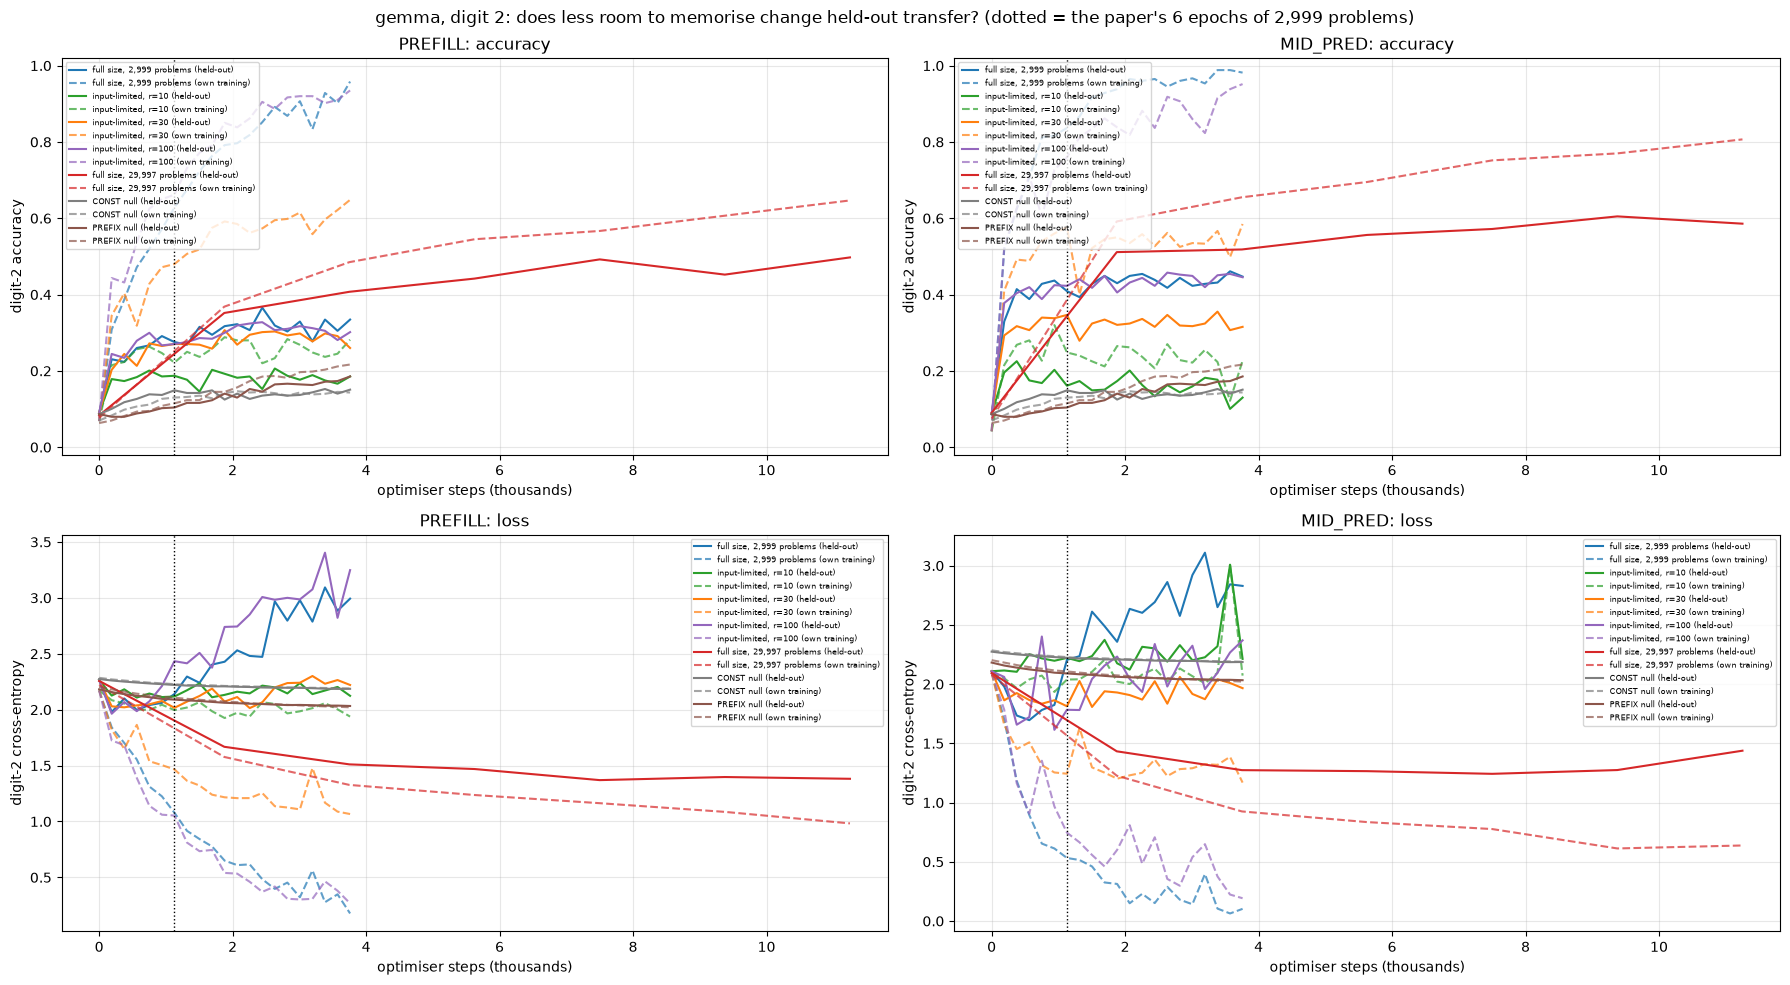

  [plot saved digitk_computation_gemma_plots/ADDON_digit2_inputlimited_bigdata.png]

  DIGIT 2 — every map through the same comparison (held-out, own training, minus the null chosen on the training bin, minus SHUF_PFX, minus the full-size map, label):
     PREFILL | full size, 2,999 problems, 6 epochs
         held-out 0.276 [0.241, 0.313] | own training 0.633 [0.600, 0.665] | held-out minus CONST +0.127 [+0.083, +0.170] | minus SHUF_PFX +0.146 [+0.108, +0.185]
         -> fit training and generalised above the null
     PREFILL | full size, 2,999 problems, 20 epochs
         held-out 0.334 [0.297, 0.374] | own training 0.954 [0.938, 0.966] | held-out minus PREFIX_ep20 +0.149 [+0.102, +0.196] | minus SHUF_PFX +0.207 [+0.165, +0.247] | minus PREFILL +0.059 [+0.021, +0.097]
         -> fit training and generalised above the null
     PREFILL | input-limited r=10, 6 epochs
         held-out 0.187 [0.157, 0.221] | own training 0.220 [0.193, 0.249] | held-out minus CONST +0.038 [-0.000, +0.

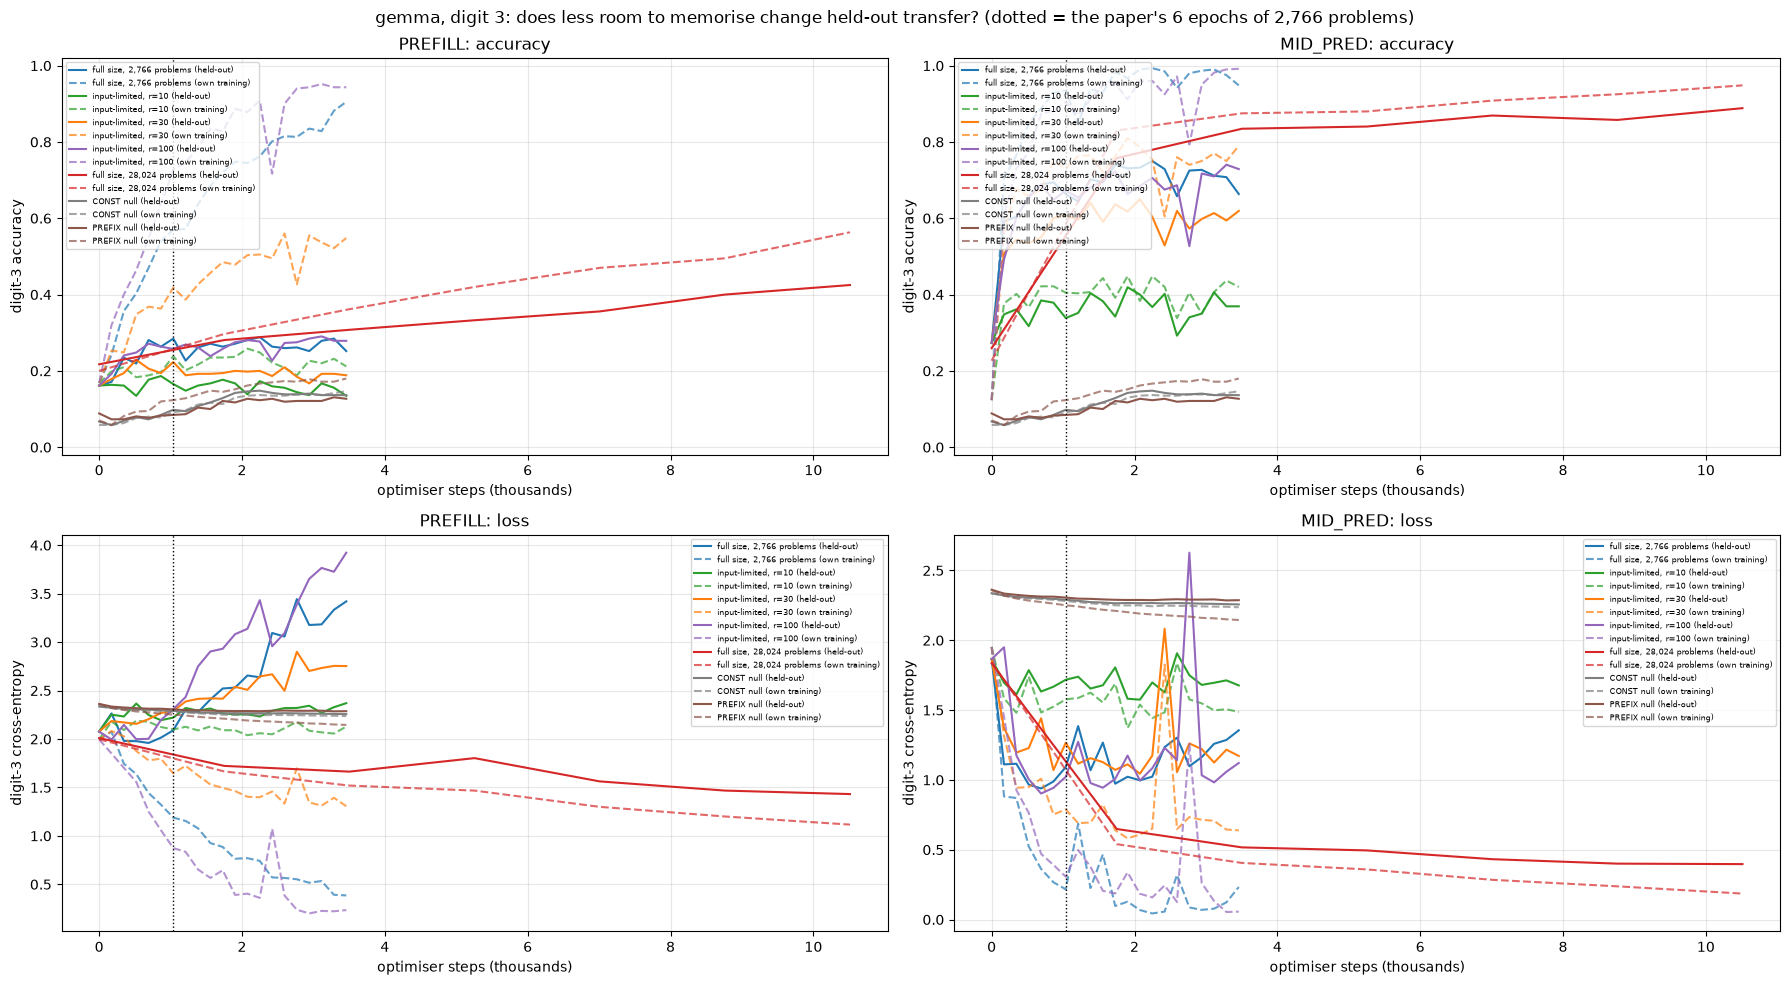

  [plot saved digitk_computation_gemma_plots/ADDON_digit3_inputlimited_bigdata.png]

  DIGIT 3 — every map through the same comparison (held-out, own training, minus the null chosen on the training bin, minus SHUF_PFX, minus the full-size map, label):
     PREFILL | full size, 2,766 problems, 6 epochs
         held-out 0.285 [0.248, 0.325] | own training 0.576 [0.540, 0.611] | held-out minus PREFIX +0.200 [+0.158, +0.244] | minus SHUF_PFX +0.178 [+0.135, +0.219]
         -> fit training and generalised above the null
     PREFILL | full size, 2,766 problems, 20 epochs
         held-out 0.252 [0.217, 0.291] | own training 0.909 [0.886, 0.928] | held-out minus PREFIX_ep20 +0.125 [+0.083, +0.165] | minus SHUF_PFX +0.136 [+0.093, +0.180] | minus PREFILL -0.033 [-0.075, +0.006]
         -> fit training and generalised above the null
     PREFILL | input-limited r=10, 6 epochs
         held-out 0.165 [0.136, 0.200] | own training 0.226 [0.198, 0.258] | held-out minus PREFIX +0.081 [+0.044, +

In [38]:
# === ADD-ON A3: one picture and one table per digit — full-size, input-limited and big-data maps vs the nulls ===
# x-axis = optimiser steps (thousands), so maps trained on different amounts of data are compared at equal training
# effort. Solid = held-out eval bin, dashed = the map's own training problems. Top: accuracy; bottom: cross-entropy
# (linear; y-axis fitted from two epochs of the 3,000-problem maps on). Dotted = the paper's 6 epochs of 3,000.
# The table puts every map through the same comparison (6-epoch maps vs 6-epoch nulls, 20-epoch maps vs 20-epoch
# nulls) and adds a training-order noise yardstick: the 6-epoch map minus the same map trained in another order.
AO_PAL = {"full": "#1f77b4", "big": "#d62728", "CONST": "#7f7f7f", "PREFIX": "#8c564b"}
_IN_PAL = ["#2ca02c", "#ff7f0e", "#9467bd", "#17becf", "#bcbd22"]
def _variants(k, src):
    v = []; lng = f"{src}_ep{LONG_EPOCHS}"
    v.append(("full", lng if lng in MAPS[k] else src, f"full size, {len(DS[k]['tr']):,} problems", AO_PAL["full"]))
    il = AO.get("inputlimited", {})
    for j, r in enumerate(il.get("ranks", [])):
        nm = f"{src}_in{r}_ep{il['epochs']}"; nm = nm if nm in MAPS[k] else f"{src}_in{r}"
        if nm in MAPS[k]: v.append((f"in{r}", nm, f"input-limited, r={r}", _IN_PAL[j % len(_IN_PAL)]))
    if f"{src}_big" in MAPS[k]:
        v.append(("big", f"{src}_big", f"full size, {AO['bigdata'][f'd{k}_data']['n_total']:,} problems", AO_PAL["big"]))
    for nl in ("CONST", "PREFIX"):
        nm = f"{nl}_ep{LONG_EPOCHS}" if f"{nl}_ep{LONG_EPOCHS}" in MAPS[k] else nl
        if nm in MAPS[k]: v.append((nl, nm, f"{nl} null", AO_PAL[nl]))
    return v
AO["table"] = {}
for k in K_LIST:
    srcs = [s for s in ("PREFILL", "MID_PRED") if s in MAPS[k]]
    fig, ax = plt.subplots(2, len(srcs), figsize=(9 * len(srcs), 10), squeeze=False)
    for j, src in enumerate(srcs):
        _yv = []; spe0 = MAPS[k][src][0].get("steps_per_epoch") or 1
        for key, nm, lab, col in _variants(k, src):
            M = MAPS[k][nm][0]; cv = M.get("curve") or []
            if not cv: continue
            spe = M.get("steps_per_epoch") or 1; x = [c["epoch"] * spe / 1000 for c in cv]
            ax[0, j].plot(x, [c["eval_bin"] for c in cv], "-", color=col, label=f"{lab} (held-out)")
            ax[0, j].plot(x, [c["train_bin"] for c in cv], "--", color=col, alpha=0.7, label=f"{lab} (own training)")
            ax[1, j].plot(x, [c["eval_bin_CE"] for c in cv], "-", color=col, label=f"{lab} (held-out)")
            ax[1, j].plot(x, [c["train_bin_CE"] for c in cv], "--", color=col, alpha=0.7, label=f"{lab} (own training)")
            _yv += [c[q] for c in cv if c["epoch"] * spe >= 2 * spe0 for q in ("eval_bin_CE", "train_bin_CE") if c.get(q) is not None]
        for i_ in (0, 1):
            ax[i_, j].axvline(TASK_EPOCHS * spe0 / 1000, ls=":", c="k", lw=1); ax[i_, j].grid(alpha=0.3)
            ax[i_, j].set_xlabel("optimiser steps (thousands)")
        ax[0, j].set_ylim(-0.02, 1.02); ax[0, j].set_ylabel(f"digit-{k} accuracy"); ax[0, j].set_title(f"{src}: accuracy")
        ax[0, j].legend(fontsize=6, loc="upper left")
        ax[1, j].set_ylabel(f"digit-{k} cross-entropy"); ax[1, j].set_title(f"{src}: loss")
        if _yv:
            pad = 0.05 * (max(_yv) - min(_yv) + 1e-9); ax[1, j].set_ylim(min(_yv) - pad, max(_yv) + pad)
        ax[1, j].legend(fontsize=6, loc="upper right")
    fig.suptitle(f"{PAIR}, digit {k}: does less room to memorise change held-out transfer? "
                 f"(dotted = the paper's {TASK_EPOCHS} epochs of {len(DS[k]['tr']):,} problems)")
    fig.tight_layout(); _p = os.path.join(PLOT_DIR, f"ADDON_digit{k}_inputlimited_bigdata.png"); fig.savefig(_p, dpi=130)
    plt.show(); plt.close(fig); print(f"  [plot saved {_p}]")
    AO["table"][f"d{k}"] = {}
    print(f"\n  DIGIT {k} — every map through the same comparison (held-out, own training, minus the null chosen on the "
          f"training bin, minus SHUF_PFX, minus the full-size map, label):")
    for src in srcs:
        tab = {f"full size, {len(DS[k]['tr']):,} problems, {TASK_EPOCHS} epochs": addon_eval(k, src, src)}
        if f"{src}_ep{LONG_EPOCHS}" in MAPS[k]:
            nl, tg = _nulls_for(LONG_EPOCHS)
            tab[f"full size, {len(DS[k]['tr']):,} problems, {LONG_EPOCHS} epochs"] = addon_eval(k, f"{src}_ep{LONG_EPOCHS}", src, nulls=nl, tag=tg)
        for r in AO.get("inputlimited", {}).get("ranks", []):
            rr = AO["inputlimited"].get(f"d{k}", {}).get(f"{src}_in{r}", {})
            for ep_key in sorted((q for q in rr if q.startswith("epoch_")), key=lambda q: int(q.split("_")[1])):
                tab[f"input-limited r={r}, {ep_key.split('_')[1]} epochs"] = rr[ep_key]
        for nk, r_ in AO.get("bigdata", {}).get(f"d{k}", {}).get(src, {}).items():
            if nk.startswith("vs_"):
                tab[(f"full size, {AO['bigdata'][f'd{k}_data']['n_total']:,} problems, {r_['steps'] / 1000:.1f}k steps "
                     f"(vs {MAPS[k][src][0]['steps'] / 1000:.1f}k), {nk.replace('_', ' ')}")] = r_
        for lab, r_ in tab.items(): _print_eval(f"{src} | {lab}", r_)
        if f"{src}_s1" in MAPS[k] and f"d{k}/{src}/eval_bin" in PER_ITEM and f"d{k}/{src}_s1/eval_bin" in PER_ITEM:
            ny = paired(PER_ITEM[f"d{k}/{src}_s1/eval_bin"], PER_ITEM[f"d{k}/{src}/eval_bin"])
            tab["noise yardstick: seed 0 minus seed 1 (held-out)"] = ny
            print(f"     {src} | noise yardstick (training order, held-out): {ny['ci']}")
        AO["table"][f"d{k}"][src] = tab
save("addon A3")